In [1]:
!nvidia-smi

Sat Sep 26 09:41:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Colab-compatible installation
# Do NOT upgrade pip or requests

!pip install -q \
    "pymatgen==2025.5.28" \
    ase \
    chgnet \
    rdkit \
    scikit-learn \
    pandas \
    numpy \
    scipy \
    matplotlib \
    umap-learn \
    plotly \
    h5py

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 16.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 82.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.6/62.6 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 30.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 962.5/962.5 kB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [3]:
import requests
import ase
import pymatgen
import chgnet
import rdkit
import sklearn
import importlib.metadata as metadata

print("Requests:", requests.__version__)
print("ASE:", ase.__version__)
print("Pymatgen:", metadata.version("pymatgen"))
print("CHGNet: OK")
print("RDKit: OK")
print("Scikit-learn: OK")

Requests: 2.32.4
ASE: 3.29.0
Pymatgen: 2025.5.28
CHGNet: OK
RDKit: OK
Scikit-learn: OK


In [4]:
from google.colab import files

uploaded = files.upload()

cif_file = list(uploaded.keys())[0]

print("Uploaded:", cif_file)

Saving 1562073.cif to 1562073.cif
Uploaded: 1562073.cif


In [5]:
from pymatgen.core import Structure

structure_exp = Structure.from_file(cif_file)

print(structure_exp)
print()
print("Formula:", structure_exp.composition.reduced_formula)
print("Number of atoms:", len(structure_exp))
print("Lattice:", structure_exp.lattice)
print("Volume:", structure_exp.volume)
print("Density:", structure_exp.density)

Full Formula (H34 C44 S2 N6 O8)
Reduced Formula: H17C22SN3O4
abc   :   7.468100  10.397000  12.675600
angles:  83.673000  85.662000  75.718000
pbc   :       True       True       True
Sites (94)
  #  SP          a        b        c
---  ----  -------  -------  -------
  0  H     0.9113   0.6268   0.5074
  1  H     0.0887   0.3732   0.4926
  2  H     0.9294   0.7663   0.5672
  3  H     0.0706   0.2337   0.4328
  4  H     0.5274   0.583    0.5634
  5  H     0.4726   0.417    0.4366
  6  H     0.8216   0.44     0.6268
  7  H     0.1784   0.56     0.3732
  8  H     0.8462   0.351    0.8142
  9  H     0.1538   0.649    0.1858
 10  H     0.5669   0.3976   0.9395
 11  H     0.4331   0.6024   0.0605
 12  H     0.2316   0.4704   0.9655
 13  H     0.7684   0.5296   0.0345
 14  H     0.9908   0.6612   0.9661
 15  H     0.0092   0.3388   0.0339
 16  H     0.9139   0.8983   0.9405
 17  H     0.0861   0.1017   0.0595
 18  H     0.8686   0.1085   0.8185
 19  H     0.1314   0.8915   0.1815
 20  H     

/usr/local/lib/python3.13/dist-packages/pymatgen/core/composition.py:1372: FutureWarning: gcd is deprecated, and will be removed on 2028-01-01
Use math.gcd instead.
  factor = abs(gcd(*(int(i) for i in sym_amt.values())))


In [6]:
from pymatgen.io.ase import AseAtomsAdaptor

atoms_exp = AseAtomsAdaptor.get_atoms(structure_exp)

print(atoms_exp)
print("Atoms:", len(atoms_exp))
print("Cell:")
print(atoms_exp.cell)

MSONAtoms(symbols='C44H34N6O8S2', pbc=True, cell=[[7.44670528584732, 0.0, 0.5648875956627029], [2.4853368456168314, 10.030349143493577, 1.1457773882552673], [0.0, 0.0, 12.6756]])
Atoms: 94
Cell:
Cell([[7.44670528584732, 0.0, 0.5648875956627029], [2.4853368456168314, 10.030349143493577, 1.1457773882552673], [0.0, 0.0, 12.6756]])


In [7]:
import numpy as np

cell = atoms_exp.cell

lengths = atoms_exp.cell.lengths()
angles = atoms_exp.cell.angles()

print("a =", lengths[0], "Å")
print("b =", lengths[1], "Å")
print("c =", lengths[2], "Å")

print("alpha =", angles[0], "°")
print("beta  =", angles[1], "°")
print("gamma =", angles[2], "°")

print("Volume =", atoms_exp.get_volume(), "Å³")
print("Density =", structure_exp.density, "g/cm³")

a = 7.4681 Å
b = 10.397 Å
c = 12.6756 Å
alpha = 83.673 °
beta  = 85.662 °
gamma = 75.718 °
Volume = 946.779275101744 Å³
Density = 1.471342360855915 g cm^-3 g/cm³


In [8]:
from chgnet.model import CHGNet

chgnet = CHGNet.load()

print("CHGNet loaded successfully.")

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda
CHGNet loaded successfully.


In [9]:
# Inspect the CHGNet prediction output

prediction_exp = chgnet.predict_structure(structure_exp)

print("Prediction completed successfully.")
print("\nReturned object type:")
print(type(prediction_exp))

print("\nReturned keys:")
print(prediction_exp.keys())

print("\nFull prediction output:")
print(prediction_exp)

/usr/local/lib/python3.13/dist-packages/chgnet/model/model.py:898: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  volumes = torch.tensor(volumes, dtype=TORCH_DTYPE, device=atomic_numbers.device)


Prediction completed successfully.

Returned object type:
<class 'dict'>

Returned keys:
dict_keys(['s', 'e', 'm', 'f'])

Full prediction output:
{'s': array([[-1.8818833 ,  0.44403023,  0.32637987],
       [ 0.4440287 , -2.6326742 , -0.29708874],
       [ 0.32637984, -0.2970866 , -2.8593202 ]], dtype=float32), 'e': array(-6.796713, dtype=float32), 'm': array([3.12719494e-03, 3.12730670e-03, 3.63857299e-03, 3.63866985e-03,
       1.67655721e-02, 1.67656615e-02, 1.04060024e-02, 1.04058236e-02,
       1.63959190e-02, 1.63959339e-02, 1.02659613e-02, 1.02659836e-02,
       1.10489205e-02, 1.10491067e-02, 6.15613908e-03, 6.15608692e-03,
       1.14471465e-02, 1.14473179e-02, 1.85533464e-02, 1.85533538e-02,
       1.69766992e-02, 1.69766322e-02, 1.18833259e-02, 1.18833259e-02,
       6.88914210e-03, 6.88910484e-03, 9.58327949e-03, 9.58333910e-03,
       1.38766617e-02, 1.38766393e-02, 1.21709555e-02, 1.21714473e-02,
       1.16457194e-02, 1.16459727e-02, 3.30743194e-03, 3.30725312e-03,
     

In [10]:
from chgnet.model import StructOptimizer

relaxer = StructOptimizer()

result = relaxer.relax(
    structure_exp,
    relax_cell=True,
    fmax=0.05,
    steps=500,
    verbose=True
)

structure_relaxed = result["final_structure"]

print(structure_relaxed)

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda
      Step     Time          Energy          fmax
FIRE:    0 09:43:06     -638.890991        1.360182
FIRE:    1 09:43:06     -639.059753        0.736878
FIRE:    2 09:43:07     -639.076294        1.260987
FIRE:    3 09:43:07     -639.104431        0.904954
FIRE:    4 09:43:07     -639.137512        0.409206
FIRE:    5 09:43:07     -639.152649        0.548896
FIRE:    6 09:43:07     -639.152588        0.728140
FIRE:    7 09:43:07     -639.154968        0.671849
FIRE:    8 09:43:08     -639.159119        0.572192
FIRE:    9 09:43:08     -639.164368        0.445814
FIRE:   10 09:43:08     -639.169495        0.304353
FIRE:   11 09:43:08     -639.173828        0.186266
FIRE:   12 09:43:08     -639.177185        0.262945
FIRE:   13 09:43:08     -639.179565        0.369997
FIRE:   14 09:43:09     -639.182068        0.438040
FIRE:   15 09:43:09     -639.185425        0.442364
FIRE:   16 09:43:09     -639.190247        0

/usr/local/lib/python3.13/dist-packages/pymatgen/core/composition.py:1372: FutureWarning: gcd is deprecated, and will be removed on 2028-01-01
Use math.gcd instead.
  factor = abs(gcd(*(int(i) for i in sym_amt.values())))


In [11]:
def lattice_report(s):
    return {
        "a": s.lattice.a,
        "b": s.lattice.b,
        "c": s.lattice.c,
        "alpha": s.lattice.alpha,
        "beta": s.lattice.beta,
        "gamma": s.lattice.gamma,
        "volume": s.volume,
        "density": s.density
    }

exp_data = lattice_report(structure_exp)
rel_data = lattice_report(structure_relaxed)

for key in exp_data:
    print(
        f"{key:8s}: "
        f"experimental = {exp_data[key]:10.4f}   "
        f"relaxed = {rel_data[key]:10.4f}"
    )

a       : experimental =     7.4681   relaxed =     7.4727
b       : experimental =    10.3970   relaxed =    10.4046
c       : experimental =    12.6756   relaxed =    12.6823
alpha   : experimental =    83.6730   relaxed =    83.6704
beta    : experimental =    85.6620   relaxed =    85.6617
gamma   : experimental =    75.7180   relaxed =    75.7201
volume  : experimental =   946.7793   relaxed =   948.5716
density : experimental =     1.4713   relaxed =     1.4686


In [12]:
for key in ["a", "b", "c", "volume", "density"]:
    exp = exp_data[key]
    rel = rel_data[key]

    pct = 100 * (rel - exp) / exp

    print(f"{key:8s}: {pct:+.2f}%")

a       : +0.06%
b       : +0.07%
c       : +0.05%
volume  : +0.19%
density : -0.19%


In [14]:
# ============================================================
# CELL 13 — CHGNet energy comparison
# ============================================================

import numpy as np

print("=" * 65)
print("CHGNet ENERGY COMPARISON")
print("=" * 65)

# ------------------------------------------------------------
# Calculate CHGNet prediction for the relaxed structure
# ------------------------------------------------------------

print("\nCalculating CHGNet energy for relaxed structure...")

prediction_rel = chgnet.predict_structure(
    structure_relaxed
)

print("Relaxed-structure prediction completed.")

# ------------------------------------------------------------
# Extract CHGNet energies
# ------------------------------------------------------------

energy_exp = float(
    prediction_exp["e"]
)

energy_rel = float(
    prediction_rel["e"]
)

# ------------------------------------------------------------
# Number of atoms
# ------------------------------------------------------------

n_atoms = len(
    structure_exp
)

# ------------------------------------------------------------
# Energy difference
# ------------------------------------------------------------

delta_e = (
    energy_rel
    -
    energy_exp
)

delta_mev_atom = (
    delta_e * 1000
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print()
print(f"Number of atoms              : {n_atoms}")
print(
    f"Experimental structure       : "
    f"{energy_exp:.6f} eV/atom"
)

print(
    f"CHGNet-relaxed structure    : "
    f"{energy_rel:.6f} eV/atom"
)

print(
    f"Energy difference            : "
    f"{delta_e:.6f} eV/atom"
)

print(
    f"Energy difference            : "
    f"{delta_mev_atom:.3f} meV/atom"
)

# ------------------------------------------------------------
# Interpretation
# ------------------------------------------------------------

if energy_rel < energy_exp:

    print(
        "\nResult: The CHGNet-relaxed structure "
        "has a lower CHGNet-predicted energy "
        "than the experimental structure."
    )

elif energy_rel > energy_exp:

    print(
        "\nResult: The experimental structure "
        "has a lower CHGNet-predicted energy "
        "than the CHGNet-relaxed structure."
    )

else:

    print(
        "\nResult: Both structures have the same "
        "CHGNet-predicted energy within the "
        "reported numerical precision."
    )

print("=" * 65)
print("CELL 13 COMPLETE")
print("=" * 65)

CHGNet ENERGY COMPARISON

Calculating CHGNet energy for relaxed structure...
Relaxed-structure prediction completed.

Number of atoms              : 94
Experimental structure       : -6.796713 eV/atom
CHGNet-relaxed structure    : -6.800929 eV/atom
Energy difference            : -0.004216 eV/atom
Energy difference            : -4.216 meV/atom

Result: The CHGNet-relaxed structure has a lower CHGNet-predicted energy than the experimental structure.
CELL 13 COMPLETE


In [15]:
# ============================================================
# CELL 14 — Force comparison
# ============================================================

forces_exp = np.array(prediction_exp["f"])
forces_rel = np.array(prediction_rel["f"])

force_exp = np.linalg.norm(forces_exp, axis=1)
force_rel = np.linalg.norm(forces_rel, axis=1)

print("=" * 65)
print("CHGNet FORCE COMPARISON")
print("=" * 65)

print(f"Experimental maximum force : {force_exp.max():.4f} eV/Å")
print(f"Relaxed maximum force      : {force_rel.max():.4f} eV/Å")

print(f"Experimental RMS force     : "
      f"{np.sqrt(np.mean(force_exp**2)):.4f} eV/Å")

print(f"Relaxed RMS force          : "
      f"{np.sqrt(np.mean(force_rel**2)):.4f} eV/Å")

print("=" * 65)

CHGNet FORCE COMPARISON
Experimental maximum force : 1.3602 eV/Å
Relaxed maximum force      : 0.0499 eV/Å
Experimental RMS force     : 0.5463 eV/Å
Relaxed RMS force          : 0.0236 eV/Å


In [16]:
structure_relaxed.to(
    filename="CHGNet_relaxed.cif",
    fmt="cif"
)

print("Saved CHGNet_relaxed.cif")

Saved CHGNet_relaxed.cif


In [17]:
from google.colab import files

files.download("CHGNet_relaxed.cif")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
from pymatgen.io.ase import AseAtomsAdaptor

atoms_md = AseAtomsAdaptor.get_atoms(structure_relaxed)

print("Atoms:", len(atoms_md))

Atoms: 94


In [19]:
print("Original atoms:", len(atoms_md))

Original atoms: 94


In [20]:
atoms_md *= (1, 1, 2)

print("Supercell atoms:", len(atoms_md))

Supercell atoms: 188


In [21]:
# ============================================================
# CELL 17 — Create a completely clean ASE MD structure
# ============================================================

from ase import Atoms
from pymatgen.io.ase import AseAtomsAdaptor

# Get the relaxed pymatgen structure
structure_md = structure_relaxed.copy()

# Build a fresh ASE Atoms object
atoms_md = Atoms(
    symbols=[site.specie.symbol for site in structure_md],
    positions=structure_md.cart_coords,
    cell=structure_md.lattice.matrix,
    pbc=True
)

print("Clean MD structure created successfully.")
print("Number of atoms:", len(atoms_md))
print("Number of positions:", len(atoms_md.positions))
print("Cell volume:", atoms_md.get_volume(), "Å³")
print("Periodic boundary conditions:", atoms_md.pbc)

Clean MD structure created successfully.
Number of atoms: 94
Number of positions: 94
Cell volume: 948.5715640648461 Å³
Periodic boundary conditions: [ True  True  True]


In [22]:
# ============================================================
# CELL 17B — Verify clean ASE structure
# ============================================================

print("Atoms:", len(atoms_md))
print("Positions:", atoms_md.positions.shape)
print("Cell:", atoms_md.cell)
print("PBC:", atoms_md.pbc)

print("\nASE arrays:")
for key, value in atoms_md.arrays.items():
    print(f"{key}: {value.shape}")

Atoms: 94
Positions: (94, 3)
Cell: Cell([[7.451327529909521, -2.9806686289588488e-05, 0.5652313172995205], [2.4868194906982515, 10.037784339625409, 1.1467358819985776], [7.302746304981388e-05, 0.00042205514245876707, 12.682349750649669]])
PBC: [ True  True  True]

ASE arrays:
numbers: (94,)
positions: (94, 3)


In [23]:
# ============================================================
# CELL 18 — Convert clean ASE structure to pymatgen
# ============================================================

structure_md = AseAtomsAdaptor.get_structure(atoms_md)

print("Conversion successful.")
print("Number of sites:", len(structure_md))
print("Formula:", structure_md.composition.reduced_formula)
print("Volume:", structure_md.volume, "Å³")

Conversion successful.
Number of sites: 94
Formula: H17C22SN3O4
Volume: 948.5715640648466 Å³


In [24]:
# ============================================================
# CELL 18 — Set up CHGNet NVT molecular dynamics
# ============================================================

from chgnet.model.dynamics import MolecularDynamics

print("Creating CHGNet molecular-dynamics object...")

md = MolecularDynamics(
    atoms=atoms_md,
    model=chgnet,
    temperature=300,
    timestep=1.0,          # fs
    trajectory="cocrystal_2ps.traj",
    logfile="cocrystal_2ps.log",
    loginterval=10
)

print("MD object created successfully.")
print("Temperature: 300 K")
print("Timestep: 1 fs")
print("Total steps: 2000")
print("Total simulation time: 2 ps")

Creating CHGNet molecular-dynamics object...
CHGNet will run on cuda
NVT-Berendsen-MD created
MD object created successfully.
Temperature: 300 K
Timestep: 1 fs
Total steps: 2000
Total simulation time: 2 ps


In [25]:
# ============================================================
# CELL 19 — Run 2 ps NVT MD
# ============================================================

print("Starting 2 ps CHGNet MD...")
print("Please wait; do not interrupt the cell.")

md.run(2000)

print("\n2 ps MD completed successfully.")

Starting 2 ps CHGNet MD...
Please wait; do not interrupt the cell.


/usr/local/lib/python3.13/dist-packages/ase/md/nvtberendsen.py:92: RuntimeWarning: divide by zero encountered in scalar divide
  1.0 + (self.temperature / old_temperature - 1.0) * tautscl



2 ps MD completed successfully.


In [26]:
import pandas as pd
import os

print("Checking MD output files...")

for f in ["cocrystal_2ps.log", "cocrystal_2ps.traj", "cocrystal_md.log"]:
    print(f"{f}: {'FOUND' if os.path.exists(f) else 'NOT FOUND'}")

Checking MD output files...
cocrystal_2ps.log: FOUND
cocrystal_2ps.traj: FOUND
cocrystal_md.log: NOT FOUND


In [27]:
import pandas as pd

log = pd.read_csv(
    "cocrystal_2ps.log",
    sep=r"\s+",
    comment="#"
)

print("MD log loaded successfully.")
print("\nFirst 5 rows:")
print(log.head())

print("\nColumn names:")
print(log.columns.tolist())

MD log loaded successfully.

First 5 rows:
   Time[ps]  Etot[eV]  Epot[eV]  Ekin[eV]  T[K]
0      0.00 -639.2873 -639.2873    0.0000   0.0
1      0.01 -639.2761 -639.2950    0.0190   1.6
2      0.02 -639.1778 -639.2808    0.1030   8.5
3      0.03 -638.8637 -639.1977    0.3340  27.5
4      0.04 -638.5469 -639.2118    0.6649  54.7

Column names:
['Time[ps]', 'Etot[eV]', 'Epot[eV]', 'Ekin[eV]', 'T[K]']


In [28]:
import numpy as np

time = log["Time[ps]"].to_numpy()
temperature = log["T[K]"].to_numpy()
epot = log["Epot[eV]"].to_numpy()
etot = log["Etot[eV]"].to_numpy()

print("=" * 65)
print("CHGNet 2 ps MD SUMMARY")
print("=" * 65)

print(f"Simulation time        : {time.min():.2f} – {time.max():.2f} ps")
print(f"Number of log frames   : {len(log)}")

print("\nTemperature:")
print(f"Initial temperature    : {temperature[0]:.2f} K")
print(f"Final temperature      : {temperature[-1]:.2f} K")
print(f"Maximum temperature    : {temperature.max():.2f} K")
print(f"Average temperature    : {temperature.mean():.2f} K")

print("\nPotential energy:")
print(f"Initial Epot           : {epot[0]:.4f} eV")
print(f"Final Epot             : {epot[-1]:.4f} eV")
print(f"Minimum Epot           : {epot.min():.4f} eV")
print(f"Maximum Epot           : {epot.max():.4f} eV")
print(f"Range                  : {epot.max()-epot.min():.4f} eV")

print("\nTotal energy:")
print(f"Initial Etot           : {etot[0]:.4f} eV")
print(f"Final Etot             : {etot[-1]:.4f} eV")
print(f"Range                  : {etot.max()-etot.min():.4f} eV")

print("=" * 65)

CHGNet 2 ps MD SUMMARY
Simulation time        : 0.00 – 2.00 ps
Number of log frames   : 201

Temperature:
Initial temperature    : 0.00 K
Final temperature      : 309.10 K
Maximum temperature    : 382.10 K
Average temperature    : 267.84 K

Potential energy:
Initial Epot           : -639.2873 eV
Final Epot             : -635.8300 eV
Minimum Epot           : -639.2950 eV
Maximum Epot           : -634.7728 eV
Range                  : 4.5222 eV

Total energy:
Initial Etot           : -639.2873 eV
Final Etot             : -632.0744 eV
Range                  : 7.4683 eV


In [29]:
from ase.io import read
import numpy as np

# Load the complete MD trajectory
traj = read("cocrystal_2ps.traj", index=":")

print("=" * 65)
print("MD TRAJECTORY STRUCTURAL ANALYSIS")
print("=" * 65)

print(f"Number of frames : {len(traj)}")
print(f"Number of atoms  : {len(traj[0])}")

# Initial and final structures
initial = traj[0]
final = traj[-1]

# Cartesian displacement
displacement = final.positions - initial.positions

# Correct for periodic boundary conditions
displacement_mic = displacement.copy()

cell = initial.get_cell()
scaled_disp = np.dot(displacement, np.linalg.inv(cell.array))
scaled_disp -= np.round(scaled_disp)
displacement_mic = np.dot(scaled_disp, cell.array)

distances = np.linalg.norm(displacement_mic, axis=1)

rmsd = np.sqrt(np.mean(distances**2))
max_disp = distances.max()
mean_disp = distances.mean()

print("\nFinal-frame displacement:")
print(f"Mean displacement : {mean_disp:.3f} Å")
print(f"RMSD              : {rmsd:.3f} Å")
print(f"Maximum displacement: {max_disp:.3f} Å")

print("=" * 65)

MD TRAJECTORY STRUCTURAL ANALYSIS
Number of frames : 201
Number of atoms  : 94

Final-frame displacement:
Mean displacement : 0.485 Å
RMSD              : 0.535 Å
Maximum displacement: 1.368 Å


In [30]:
from ase.io import read

traj = read("cocrystal_2ps.traj", index=":")

print("=" * 65)
print("TRAJECTORY VERIFICATION")
print("=" * 65)

print("Number of frames :", len(traj))
print("Atoms per frame  :", len(traj[0]))
print("Chemical formula :", traj[0].get_chemical_formula())
print("Cell volume      :", traj[0].get_volume(), "Å³")
print("PBC              :", traj[0].pbc)

print("\nFirst 10 elements:")
print(traj[0].get_chemical_symbols()[:10])

print("=" * 65)

TRAJECTORY VERIFICATION
Number of frames : 201
Atoms per frame  : 94
Chemical formula : C44H34N6O8S2
Cell volume      : 948.5715640648461 Å³
PBC              : [ True  True  True]

First 10 elements:
['H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H']


In [31]:
print("=" * 65)
print("EXPERIMENTAL vs MD STRUCTURE CHECK")
print("=" * 65)

print("Experimental structure:")
print("  Atoms :", len(structure_exp))
print("  Formula:", structure_exp.composition.reduced_formula)
print("  Volume :", structure_exp.volume, "Å³")

print("\nRelaxed structure:")
print("  Atoms :", len(structure_relaxed))
print("  Formula:", structure_relaxed.composition.reduced_formula)
print("  Volume :", structure_relaxed.volume, "Å³")

print("\nMD starting frame:")
print("  Atoms :", len(traj[0]))
print("  Formula:", traj[0].get_chemical_formula())
print("  Volume :", traj[0].get_volume(), "Å³")

print("=" * 65)

EXPERIMENTAL vs MD STRUCTURE CHECK
Experimental structure:
  Atoms : 94
  Formula: H17C22SN3O4
  Volume : 946.7792751017441 Å³

Relaxed structure:
  Atoms : 94
  Formula: H17C22SN3O4
  Volume : 948.5715640648466 Å³

MD starting frame:
  Atoms : 94
  Formula: C44H34N6O8S2
  Volume : 948.5715640648461 Å³


/usr/local/lib/python3.13/dist-packages/pymatgen/core/composition.py:1372: FutureWarning: gcd is deprecated, and will be removed on 2028-01-01
Use math.gcd instead.
  factor = abs(gcd(*(int(i) for i in sym_amt.values())))


In [32]:
import numpy as np

exp_cell = np.array(structure_exp.lattice.abc)
rel_cell = np.array(structure_relaxed.lattice.abc)

exp_angles = np.array(structure_exp.lattice.angles)
rel_angles = np.array(structure_relaxed.lattice.angles)

print("=" * 65)
print("EXPERIMENTAL vs CHGNet-RELAXED CRYSTAL CELL")
print("=" * 65)

print("\nLattice parameters (Å):")
print(f"{'Parameter':<12}{'Experimental':>18}{'Relaxed':>18}{'Change':>15}")

for name, e, r in zip(["a", "b", "c"], exp_cell, rel_cell):
    print(f"{name:<12}{e:>18.4f}{r:>18.4f}{r-e:>15.4f}")

print("\nLattice angles (degrees):")
print(f"{'Parameter':<12}{'Experimental':>18}{'Relaxed':>18}{'Change':>15}")

for name, e, r in zip(["alpha", "beta", "gamma"], exp_angles, rel_angles):
    print(f"{name:<12}{e:>18.4f}{r:>18.4f}{r-e:>15.4f}")

print("\nVolume:")
print(f"Experimental : {structure_exp.volume:.4f} Å³")
print(f"Relaxed      : {structure_relaxed.volume:.4f} Å³")
print(f"Change       : {structure_relaxed.volume - structure_exp.volume:.4f} Å³")
print(f"Percent      : {(structure_relaxed.volume/structure_exp.volume - 1)*100:.3f} %")

print("=" * 65)

EXPERIMENTAL vs CHGNet-RELAXED CRYSTAL CELL

Lattice parameters (Å):
Parameter         Experimental           Relaxed         Change
a                       7.4681            7.4727         0.0046
b                      10.3970           10.4046         0.0076
c                      12.6756           12.6823         0.0067

Lattice angles (degrees):
Parameter         Experimental           Relaxed         Change
alpha                  83.6730           83.6704        -0.0026
beta                   85.6620           85.6617        -0.0003
gamma                  75.7180           75.7201         0.0021

Volume:
Experimental : 946.7793 Å³
Relaxed      : 948.5716 Å³
Change       : 1.7923 Å³
Percent      : 0.189 %


In [33]:
from pymatgen.core import Structure

print("=" * 65)
print("ATOMIC SPECIES IN THE EXPERIMENTAL Cocrystal")
print("=" * 65)

species = {}

for site in structure_exp:
    element = site.specie.symbol
    species[element] = species.get(element, 0) + 1

for element, count in species.items():
    print(f"{element:>4} : {count}")

print("\nFull composition:")
print(structure_exp.composition)

print("=" * 65)

ATOMIC SPECIES IN THE EXPERIMENTAL Cocrystal
   H : 34
   C : 44
   S : 2
   N : 6
   O : 8

Full composition:
H34 C44 S2 N6 O8


In [34]:
import numpy as np

structure = structure_exp

# Covalent radii (Å) for identifying approximate bonded neighbors
covalent_radii = {
    "H": 0.31,
    "C": 0.76,
    "N": 0.71,
    "O": 0.66,
    "S": 1.05
}

# Potential H-bond donors: N-H and O-H
donor_atoms = []

for i, site in enumerate(structure):
    element = site.specie.symbol

    if element not in ["N", "O"]:
        continue

    for j, neighbor in enumerate(structure):
        if i == j:
            continue

        neighbor_element = neighbor.specie.symbol

        if neighbor_element != "H":
            continue

        distance = structure.get_distance(i, j)

        # Approximate covalent N-H/O-H bond
        cutoff = covalent_radii[element] + covalent_radii["H"] + 0.35

        if distance <= cutoff:
            donor_atoms.append((i, element, j, distance))

print("=" * 70)
print("POTENTIAL H-BOND DONORS")
print("=" * 70)

if donor_atoms:
    for i, element, j, distance in donor_atoms:
        print(
            f"Donor atom {element}{i} -- H{j} : "
            f"{distance:.3f} Å"
        )
else:
    print("No N-H or O-H bonds detected.")

print("\nNumber of potential donor groups:", len(donor_atoms))

print("=" * 70)

POTENTIAL H-BOND DONORS
Donor atom N80 -- H32 : 1.008 Å
Donor atom N81 -- H33 : 1.008 Å
Donor atom N84 -- H0 : 1.009 Å
Donor atom N84 -- H2 : 1.009 Å
Donor atom N85 -- H1 : 1.009 Å
Donor atom N85 -- H3 : 1.009 Å

Number of potential donor groups: 6


In [35]:
import numpy as np

structure = structure_exp

# Potential hydrogen-bond acceptors
acceptor_elements = {"N", "O", "S"}

# Donor N-H pairs obtained above
donors = donor_atoms

print("=" * 80)
print("POTENTIAL N-H···N/O/S HYDROGEN-BOND CONTACTS")
print("=" * 80)

contacts = []

for donor_i, donor_element, h_i, nh_distance in donors:

    donor_site = structure[donor_i]
    h_site = structure[h_i]

    for acceptor_i, acceptor_site in enumerate(structure):

        if acceptor_i == donor_i or acceptor_i == h_i:
            continue

        acceptor_element = acceptor_site.specie.symbol

        if acceptor_element not in acceptor_elements:
            continue

        # H...acceptor distance
        ha_distance = structure.get_distance(h_i, acceptor_i)

        # Donor...acceptor distance
        da_distance = structure.get_distance(donor_i, acceptor_i)

        # Screen for plausible H-bonds
        if ha_distance <= 3.0 and da_distance <= 3.8:

            contacts.append(
                (
                    donor_i,
                    h_i,
                    acceptor_i,
                    acceptor_element,
                    nh_distance,
                    ha_distance,
                    da_distance
                )
            )

# Sort by H...acceptor distance
contacts.sort(key=lambda x: x[5])

if contacts:

    print(
        f"{'D':>5} {'H':>5} {'A':>5} "
        f"{'A type':>8} {'N-H':>8} "
        f"{'H...A':>10} {'D...A':>10}"
    )

    print("-" * 80)

    for c in contacts:
        print(
            f"{c[0]:5d} {c[1]:5d} {c[2]:5d} "
            f"{c[3]:>8} {c[4]:8.3f} "
            f"{c[5]:10.3f} {c[6]:10.3f}"
        )

else:
    print("No plausible N-H···N/O/S contacts found.")

print("\nNumber of candidate contacts:", len(contacts))
print("=" * 80)

POTENTIAL N-H···N/O/S HYDROGEN-BOND CONTACTS
    D     H     A   A type      N-H      H...A      D...A
--------------------------------------------------------------------------------
   81    33    93        O    1.008      1.746      2.717
   80    32    92        O    1.008      1.746      2.717
   84     0    93        O    1.009      1.932      2.937
   85     1    92        O    1.009      1.932      2.937
   80    32    78        S    1.008      2.305      1.657
   81    33    79        S    1.008      2.305      1.657
   84     2    87        O    1.009      2.451      2.994
   85     3    86        O    1.009      2.451      2.994
   85     1    93        O    1.009      2.462      2.258
   84     0    92        O    1.009      2.462      2.258
   84     2    82        N    1.009      2.557      2.333
   85     3    83        N    1.009      2.557      2.333
   80    32    90        O    1.008      2.676      2.300
   81    33    91        O    1.008      2.676      2.300
   8

In [36]:
import numpy as np

def angle_three_points(p1, p2, p3):
    """
    Calculate angle p1-p2-p3 in degrees.
    """
    v1 = p1 - p2
    v2 = p3 - p2

    cos_angle = np.dot(v1, v2) / (
        np.linalg.norm(v1) * np.linalg.norm(v2)
    )

    cos_angle = np.clip(cos_angle, -1.0, 1.0)

    return np.degrees(np.arccos(cos_angle))


print("=" * 95)
print("N-H···N/O/S HYDROGEN-BOND GEOMETRY")
print("=" * 95)

hbonds_geometry = []

for contact in contacts:

    donor_i = contact[0]
    h_i = contact[1]
    acceptor_i = contact[2]
    acceptor_element = contact[3]

    # Cartesian coordinates
    D = structure[donor_i].coords
    H = structure[h_i].coords
    A = structure[acceptor_i].coords

    # N-H...A angle
    angle = angle_three_points(D, H, A)

    hbonds_geometry.append(
        (
            donor_i,
            h_i,
            acceptor_i,
            acceptor_element,
            contact[4],   # N-H
            contact[5],   # H...A
            contact[6],   # D...A
            angle
        )
    )

# Sort by H...A distance
hbonds_geometry.sort(key=lambda x: x[5])

print(
    f"{'D':>4} {'H':>4} {'A':>4} "
    f"{'A type':>7} {'N-H':>7} "
    f"{'H...A':>8} {'D...A':>8} "
    f"{'Angle':>9}"
)

print("-" * 95)

for hb in hbonds_geometry:

    print(
        f"{hb[0]:4d} {hb[1]:4d} {hb[2]:4d} "
        f"{hb[3]:>7} "
        f"{hb[4]:7.3f} "
        f"{hb[5]:8.3f} "
        f"{hb[6]:8.3f} "
        f"{hb[7]:9.2f}°"
    )

print("=" * 95)

N-H···N/O/S HYDROGEN-BOND GEOMETRY
   D    H    A  A type     N-H    H...A    D...A     Angle
-----------------------------------------------------------------------------------------------
  81   33   93       O   1.008    1.746    2.717    160.26°
  80   32   92       O   1.008    1.746    2.717    160.26°
  84    0   93       O   1.009    1.932    2.937    173.03°
  85    1   92       O   1.009    1.932    2.937    173.03°
  80   32   78       S   1.008    2.305    1.657     39.57°
  81   33   79       S   1.008    2.305    1.657     39.57°
  84    2   87       O   1.009    2.451    2.994    113.09°
  85    3   86       O   1.009    2.451    2.994    113.09°
  85    1   93       O   1.009    2.462    2.258    124.83°
  84    0   92       O   1.009    2.462    2.258    124.83°
  84    2   82       N   1.009    2.557    2.333     83.30°
  85    3   83       N   1.009    2.557    2.333     83.30°
  80   32   90       O   1.008    2.676    2.300     57.67°
  81   33   91       O   1.008

In [37]:
import numpy as np
import networkx as nx
from pymatgen.analysis.graphs import StructureGraph
from pymatgen.analysis.local_env import CrystalNN

print("=" * 80)
print("IDENTIFYING MOLECULAR FRAGMENTS IN THE CRYSTAL")
print("=" * 80)

# Build the crystal connectivity graph
sg = StructureGraph.from_local_env_strategy(
    structure_exp,
    CrystalNN()
)

# Convert directed graph to undirected graph
graph_undirected = sg.graph.to_undirected()

# Find connected components
components = list(nx.connected_components(graph_undirected))

print("Total atoms:", len(structure_exp))
print("Number of connected components:", len(components))
print()

from collections import Counter

for i, component in enumerate(components, start=1):

    component = sorted(list(component))

    elements = [
        structure_exp[index].specie.symbol
        for index in component
    ]

    composition = Counter(elements)

    print(f"Component {i}")
    print("-" * 50)
    print("Number of atoms:", len(component))
    print("Atom indices:", component)
    print("Composition:", dict(composition))
    print()

print("=" * 80)

IDENTIFYING MOLECULAR FRAGMENTS IN THE CRYSTAL


/usr/local/lib/python3.13/dist-packages/pymatgen/analysis/local_env.py:4021: UserWarning: No oxidation states specified on sites! For better results, set the site oxidation states in the structure.
  r1 = _get_radius(structure[n])
/usr/local/lib/python3.13/dist-packages/pymatgen/analysis/local_env.py:4023: UserWarning: No oxidation states specified on sites! For better results, set the site oxidation states in the structure.
  r2 = _get_radius(entry["site"])
/usr/local/lib/python3.13/dist-packages/pymatgen/analysis/local_env.py:3935: UserWarning: CrystalNN: cannot locate an appropriate radius, covalent or atomic radii will be used, this can lead to non-optimal results.
  nn_data = self.get_nn_data(structure, n)


Total atoms: 94
Number of connected components: 14

Component 1
--------------------------------------------------
Number of atoms: 22
Atom indices: [0, 2, 4, 10, 12, 14, 16, 22, 48, 50, 56, 58, 60, 62, 64, 66, 72, 74, 76, 82, 84, 92]
Composition: {'H': 8, 'C': 11, 'N': 2, 'O': 1}

Component 2
--------------------------------------------------
Number of atoms: 22
Atom indices: [1, 3, 5, 11, 13, 15, 17, 23, 49, 51, 57, 59, 61, 63, 65, 67, 73, 75, 77, 83, 85, 93]
Composition: {'H': 8, 'C': 11, 'N': 2, 'O': 1}

Component 3
--------------------------------------------------
Number of atoms: 2
Atom indices: [6, 52]
Composition: {'H': 1, 'C': 1}

Component 4
--------------------------------------------------
Number of atoms: 2
Atom indices: [7, 53]
Composition: {'H': 1, 'C': 1}

Component 5
--------------------------------------------------
Number of atoms: 2
Atom indices: [8, 54]
Composition: {'H': 1, 'C': 1}

Component 6
--------------------------------------------------
Number of atoms: 2

In [38]:
import numpy as np
import networkx as nx
from collections import Counter

structure = structure_exp

# Covalent radii in Å
covalent_radii = {
    "H": 0.31,
    "C": 0.76,
    "N": 0.71,
    "O": 0.66,
    "S": 1.05
}

# Build an undirected molecular connectivity graph
G = nx.Graph()

# Add all atoms
for i in range(len(structure)):
    G.add_node(i)

# Detect covalent bonds using a conservative tolerance
for i in range(len(structure)):

    for j in range(i + 1, len(structure)):

        elem_i = structure[i].specie.symbol
        elem_j = structure[j].specie.symbol

        if elem_i not in covalent_radii or elem_j not in covalent_radii:
            continue

        cutoff = (
            covalent_radii[elem_i]
            + covalent_radii[elem_j]
            + 0.20
        )

        distance = structure.get_distance(i, j)

        if distance <= cutoff:
            G.add_edge(i, j)

# Find connected molecular fragments
components_cov = list(nx.connected_components(G))

print("=" * 80)
print("COVALENT-CONNECTIVITY MOLECULAR FRAGMENTS")
print("=" * 80)

print("Total atoms:", len(structure))
print("Number of molecular fragments:", len(components_cov))
print()

for i, component in enumerate(components_cov, start=1):

    component = sorted(component)

    elements = [
        structure[index].specie.symbol
        for index in component
    ]

    composition = Counter(elements)

    print(f"Fragment {i}")
    print("-" * 60)
    print("Number of atoms:", len(component))
    print("Atom indices:", component)
    print("Composition:", dict(composition))
    print()

print("=" * 80)

COVALENT-CONNECTIVITY MOLECULAR FRAGMENTS
Total atoms: 94
Number of molecular fragments: 4

Fragment 1
------------------------------------------------------------
Number of atoms: 30
Atom indices: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 48, 50, 52, 54, 56, 58, 60, 62, 64, 66, 68, 70, 72, 74, 76, 82, 84, 92]
Composition: {'H': 12, 'C': 15, 'N': 2, 'O': 1}

Fragment 2
------------------------------------------------------------
Number of atoms: 30
Atom indices: [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 49, 51, 53, 55, 57, 59, 61, 63, 65, 67, 69, 71, 73, 75, 77, 83, 85, 93]
Composition: {'H': 12, 'C': 15, 'N': 2, 'O': 1}

Fragment 3
------------------------------------------------------------
Number of atoms: 17
Atom indices: [24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 78, 80, 86, 88, 90]
Composition: {'H': 5, 'C': 7, 'S': 1, 'N': 1, 'O': 3}

Fragment 4
------------------------------------------------------------
Number of atoms: 17
Atom indices: [25, 27, 29, 31, 33, 35, 37, 3

In [39]:
# Create an atom -> molecular fragment mapping

fragment_map = {}

for fragment_number, component in enumerate(components_cov, start=1):
    for atom_index in component:
        fragment_map[atom_index] = fragment_number


# The four strongest hydrogen-bond candidates
strong_hbonds = [
    (81, 33, 93),
    (80, 32, 92),
    (84, 0, 93),
    (85, 1, 92)
]

print("=" * 90)
print("INTERMOLECULAR HYDROGEN-BOND CLASSIFICATION")
print("=" * 90)

for donor, hydrogen, acceptor in strong_hbonds:

    donor_fragment = fragment_map[donor]
    hydrogen_fragment = fragment_map[hydrogen]
    acceptor_fragment = fragment_map[acceptor]

    print(
        f"N{donor}-H{hydrogen}···"
        f"{structure_exp[acceptor].specie.symbol}{acceptor}"
    )

    print(
        f"  Donor fragment    : {donor_fragment}"
    )

    print(
        f"  Hydrogen fragment : {hydrogen_fragment}"
    )

    print(
        f"  Acceptor fragment : {acceptor_fragment}"
    )

    if donor_fragment != acceptor_fragment:
        print("  Classification     : INTERMOLECULAR")
    else:
        print("  Classification     : INTRAMOLECULAR")

    print("-" * 90)

print("=" * 90)

INTERMOLECULAR HYDROGEN-BOND CLASSIFICATION
N81-H33···O93
  Donor fragment    : 4
  Hydrogen fragment : 4
  Acceptor fragment : 2
  Classification     : INTERMOLECULAR
------------------------------------------------------------------------------------------
N80-H32···O92
  Donor fragment    : 3
  Hydrogen fragment : 3
  Acceptor fragment : 1
  Classification     : INTERMOLECULAR
------------------------------------------------------------------------------------------
N84-H0···O93
  Donor fragment    : 1
  Hydrogen fragment : 1
  Acceptor fragment : 2
  Classification     : INTERMOLECULAR
------------------------------------------------------------------------------------------
N85-H1···O92
  Donor fragment    : 2
  Hydrogen fragment : 2
  Acceptor fragment : 1
  Classification     : INTERMOLECULAR
------------------------------------------------------------------------------------------


In [40]:
from ase.io import read
import numpy as np
import pandas as pd

# Load the complete MD trajectory
traj = read("cocrystal_2ps.traj", index=":")

print("=" * 90)
print("HYDROGEN-BOND PERSISTENCE ANALYSIS")
print("=" * 90)

# Four experimentally identified intermolecular N-H...O interactions
hbonds = [
    ("N81-H33...O93", 81, 33, 93),
    ("N80-H32...O92", 80, 32, 92),
    ("N84-H0...O93",   84, 0, 93),
    ("N85-H1...O92",   85, 1, 92)
]

def minimum_image_vector(position1, position2, cell):
    """
    Return minimum-image vector from position1 to position2.
    """
    fractional = np.linalg.solve(cell.T, position2 - position1)
    fractional -= np.round(fractional)
    return np.dot(fractional, cell)


def distance_mic(position1, position2, cell):
    vector = minimum_image_vector(position1, position2, cell)
    return np.linalg.norm(vector)


def hydrogen_bond_angle(D, H, A, cell):
    """
    Calculate D-H...A angle using minimum-image vectors.
    """

    # H -> D
    HD = minimum_image_vector(H, D, cell)

    # H -> A
    HA = minimum_image_vector(H, A, cell)

    cos_angle = np.dot(HD, HA) / (
        np.linalg.norm(HD) * np.linalg.norm(HA)
    )

    cos_angle = np.clip(cos_angle, -1.0, 1.0)

    return np.degrees(np.arccos(cos_angle))


results = []

for frame_number, atoms in enumerate(traj):

    positions = atoms.positions
    cell = atoms.cell.array

    time_ps = frame_number * 0.01

    for name, donor, hydrogen, acceptor in hbonds:

        D = positions[donor]
        H = positions[hydrogen]
        A = positions[acceptor]

        h_a = distance_mic(H, A, cell)
        d_a = distance_mic(D, A, cell)

        angle = hydrogen_bond_angle(D, H, A, cell)

        # Geometric H-bond criterion
        is_hbond = (
            h_a <= 2.7
            and d_a <= 3.5
            and angle >= 140
        )

        results.append({
            "Frame": frame_number,
            "Time_ps": time_ps,
            "Interaction": name,
            "H_A_Angstrom": h_a,
            "D_A_Angstrom": d_a,
            "Angle_deg": angle,
            "Hbond": is_hbond
        })


hb_df = pd.DataFrame(results)

print("Trajectory frames:", len(traj))
print("Total observations:", len(hb_df))
print()

print("Hydrogen-bond persistence:")
print("-" * 90)

for name in hbonds:

    interaction_name = name[0]

    subset = hb_df[
        hb_df["Interaction"] == interaction_name
    ]

    persistence = 100 * subset["Hbond"].mean()

    print(
        f"{interaction_name:18s} : "
        f"{persistence:6.2f}% of frames"
    )

print("=" * 90)

HYDROGEN-BOND PERSISTENCE ANALYSIS
Trajectory frames: 201
Total observations: 804

Hydrogen-bond persistence:
------------------------------------------------------------------------------------------
N81-H33...O93      :  82.59% of frames
N80-H32...O92      :  84.08% of frames
N84-H0...O93       :  62.19% of frames
N85-H1...O92       :  57.71% of frames


In [41]:
print("=" * 110)
print("HYDROGEN-BOND STATISTICS FROM 2-PS CHGNet MD")
print("=" * 110)

summary = []

for name, donor, hydrogen, acceptor in hbonds:

    subset = hb_df[
        hb_df["Interaction"] == name
    ].copy()

    persistence = 100 * subset["Hbond"].mean()

    summary.append({
        "Interaction": name,
        "Persistence_%": persistence,
        "Mean_H_A": subset["H_A_Angstrom"].mean(),
        "SD_H_A": subset["H_A_Angstrom"].std(),
        "Min_H_A": subset["H_A_Angstrom"].min(),
        "Max_H_A": subset["H_A_Angstrom"].max(),
        "Mean_D_A": subset["D_A_Angstrom"].mean(),
        "SD_D_A": subset["D_A_Angstrom"].std(),
        "Mean_Angle": subset["Angle_deg"].mean(),
        "SD_Angle": subset["Angle_deg"].std(),
        "Min_Angle": subset["Angle_deg"].min(),
        "Max_Angle": subset["Angle_deg"].max()
    })

summary_df = pd.DataFrame(summary)

print(
    summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("=" * 110)

HYDROGEN-BOND STATISTICS FROM 2-PS CHGNet MD
  Interaction  Persistence_%  Mean_H_A  SD_H_A  Min_H_A  Max_H_A  Mean_D_A  SD_D_A  Mean_Angle  SD_Angle  Min_Angle  Max_Angle
N81-H33...O93         82.587     1.892   0.317    1.367    2.777     2.837   0.261     152.589    14.397    112.998    178.478
N80-H32...O92         84.080     1.885   0.313    1.367    2.755     2.835   0.259     153.005    13.801    115.654    177.787
 N84-H0...O93         62.189     2.361   0.553    1.538    3.865     3.212   0.361     148.302    25.116     64.811    179.439
 N85-H1...O92         57.711     2.377   0.560    1.529    3.865     3.213   0.358     147.042    26.144     64.477    178.539


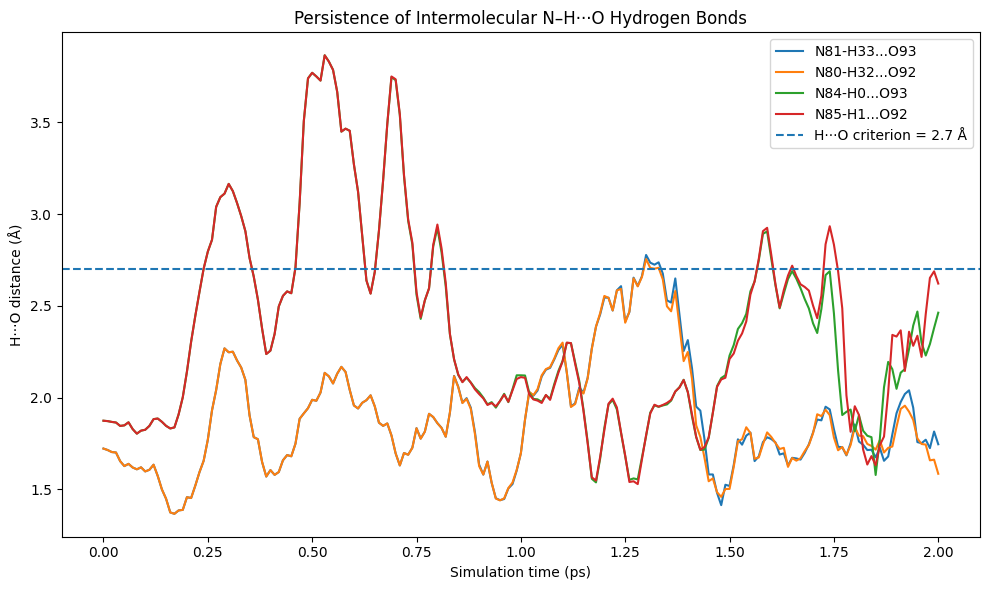

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, donor, hydrogen, acceptor in hbonds:

    subset = hb_df[
        hb_df["Interaction"] == name
    ]

    plt.plot(
        subset["Time_ps"],
        subset["H_A_Angstrom"],
        label=name
    )

# Hydrogen-bond distance criterion
plt.axhline(
    2.7,
    linestyle="--",
    linewidth=1.5,
    label="H···O criterion = 2.7 Å"
)

plt.xlabel("Simulation time (ps)")
plt.ylabel("H···O distance (Å)")
plt.title("Persistence of Intermolecular N–H···O Hydrogen Bonds")
plt.legend()
plt.tight_layout()

plt.show()

In [43]:
import numpy as np
import pandas as pd

structure = structure_exp

# Molecular fragments identified previously
fragment_A = set(components_cov[0])
fragment_A2 = set(components_cov[1])

fragment_B = set(components_cov[2])
fragment_B2 = set(components_cov[3])

# Combine symmetry-related copies
A_atoms = fragment_A | fragment_A2
B_atoms = fragment_B | fragment_B2

print("=" * 90)
print("INTERMOLECULAR CONTACT ANALYSIS")
print("=" * 90)

print("Component A atoms:", len(A_atoms))
print("Component B atoms:", len(B_atoms))
print("Total atoms:", len(structure))

print()

# van der Waals radii (Å)
vdw = {
    "H": 1.20,
    "C": 1.70,
    "N": 1.55,
    "O": 1.52,
    "S": 1.80
}

contacts = []

# Calculate all A-B contacts
for i in A_atoms:

    elem_i = structure[i].specie.symbol

    if elem_i not in vdw:
        continue

    for j in B_atoms:

        elem_j = structure[j].specie.symbol

        if elem_j not in vdw:
            continue

        distance = structure.get_distance(i, j)

        # Sum of van der Waals radii
        vdw_sum = vdw[elem_i] + vdw[elem_j]

        # Contact shorter than vdW sum
        if distance < vdw_sum:

            contact_ratio = distance / vdw_sum

            contacts.append({
                "Atom_A": i,
                "Element_A": elem_i,
                "Atom_B": j,
                "Element_B": elem_j,
                "Distance_A": distance,
                "vdW_sum_A": vdw_sum,
                "Contact_ratio": contact_ratio
            })

contact_df = pd.DataFrame(contacts)

# Sort by shortest distance
contact_df = contact_df.sort_values(
    "Distance_A"
).reset_index(drop=True)

print("Number of short intermolecular contacts:",
      len(contact_df))

print()

print(
    contact_df.head(30).to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("=" * 90)

INTERMOLECULAR CONTACT ANALYSIS
Component A atoms: 60
Component B atoms: 34
Total atoms: 94

Number of short intermolecular contacts: 30

 Atom_A Element_A  Atom_B Element_B  Distance_A  vdW_sum_A  Contact_ratio
     93         O      33         H       1.746      2.720          0.642
     92         O      32         H       1.746      2.720          0.642
     10         H      29         H       2.116      2.400          0.882
     11         H      28         H       2.116      2.400          0.882
      2         H      24         H       2.132      2.400          0.888
      3         H      25         H       2.132      2.400          0.888
     16         H      31         H       2.276      2.400          0.948
     17         H      30         H       2.276      2.400          0.948
      3         H      86         O       2.451      2.720          0.901
      2         H      87         O       2.451      2.720          0.901
     22         H      89         O       2.502 

In [44]:
from pymatgen.analysis.graphs import StructureGraph
from pymatgen.analysis.local_env import JmolNN

print("=" * 90)
print("STEP 2 — CRYSTAL CONNECTIVITY GRAPH")
print("=" * 90)

sg_jmol = StructureGraph.from_local_env_strategy(
    structure_exp,
    JmolNN()
)

graph = sg_jmol.graph.to_undirected()

print("Connectivity graph generated.")
print("Number of atoms:", len(structure_exp))
print("Number of graph edges:", graph.number_of_edges())

print("=" * 90)

STEP 2 — CRYSTAL CONNECTIVITY GRAPH
Connectivity graph generated.
Number of atoms: 94
Number of graph edges: 100


In [45]:
import networkx as nx

print("=" * 90)
print("STEP 3 — RING IDENTIFICATION")
print("=" * 90)

# Convert the molecular MultiGraph into a simple undirected graph
simple_graph = nx.Graph(graph)

# Find the smallest independent set of rings
cycles = nx.cycle_basis(simple_graph)

print("Total rings detected:", len(cycles))
print()

for i, ring in enumerate(cycles, start=1):
    elements = [structure_exp[j].specie.symbol for j in ring]

    print(
        f"Ring {i}: "
        f"{len(ring)} atoms | "
        f"Atoms = {sorted(ring)} | "
        f"Elements = {elements}"
    )

print("=" * 90)

STEP 3 — RING IDENTIFICATION
Total rings detected: 10

Ring 1: 6 atoms | Atoms = [65, 67, 69, 71, 73, 75] | Elements = ['C', 'C', 'C', 'C', 'C', 'C']
Ring 2: 7 atoms | Atoms = [49, 59, 61, 63, 65, 75, 83] | Elements = ['C', 'C', 'C', 'C', 'C', 'C', 'N']
Ring 3: 6 atoms | Atoms = [49, 51, 53, 55, 57, 59] | Elements = ['C', 'C', 'C', 'C', 'C', 'C']
Ring 4: 6 atoms | Atoms = [64, 66, 68, 70, 72, 74] | Elements = ['C', 'C', 'C', 'C', 'C', 'C']
Ring 5: 7 atoms | Atoms = [48, 58, 60, 62, 64, 74, 82] | Elements = ['C', 'C', 'C', 'C', 'C', 'C', 'N']
Ring 6: 6 atoms | Atoms = [48, 50, 52, 54, 56, 58] | Elements = ['C', 'C', 'C', 'C', 'C', 'C']
Ring 7: 5 atoms | Atoms = [35, 45, 47, 79, 81] | Elements = ['C', 'C', 'S', 'N', 'C']
Ring 8: 6 atoms | Atoms = [35, 37, 39, 41, 43, 45] | Elements = ['C', 'C', 'C', 'C', 'C', 'C']
Ring 9: 5 atoms | Atoms = [34, 44, 46, 78, 80] | Elements = ['C', 'C', 'S', 'N', 'C']
Ring 10: 6 atoms | Atoms = [34, 36, 38, 40, 42, 44] | Elements = ['C', 'C', 'C', 'C', 'C',

In [46]:
import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 4 — RING GEOMETRY AND π···π CONTACT ANALYSIS")
print("=" * 90)

ring_data = []

for ring_id, ring in enumerate(cycles, start=1):

    coords = np.array([structure_exp[i].coords for i in ring])

    # Ring centroid
    centroid = coords.mean(axis=0)

    # Principal component analysis to obtain ring plane
    centered = coords - centroid
    _, _, vh = np.linalg.svd(centered)

    # Normal vector to ring plane
    normal = vh[-1]

    # Calculate RMS deviation from the mean plane
    plane_distances = np.dot(centered, normal)
    rms_plane = np.sqrt(np.mean(plane_distances**2))

    elements = [structure_exp[i].specie.symbol for i in ring]

    ring_data.append({
        "Ring": ring_id,
        "N_atoms": len(ring),
        "Elements": "".join(elements),
        "Centroid_x": centroid[0],
        "Centroid_y": centroid[1],
        "Centroid_z": centroid[2],
        "Normal_x": normal[0],
        "Normal_y": normal[1],
        "Normal_z": normal[2],
        "Plane_RMS_A": rms_plane
    })

ring_df = pd.DataFrame(ring_data)

print()
print("Ring geometry:")
print(
    ring_df[
        [
            "Ring",
            "N_atoms",
            "Elements",
            "Plane_RMS_A"
        ]
    ].to_string(index=False)
)

print("=" * 90)

# ---------------------------------------------------------
# Calculate centroid distances between all ring pairs
# ---------------------------------------------------------

pi_contacts = []

for i in range(len(ring_data)):
    for j in range(i + 1, len(ring_data)):

        r1 = ring_data[i]
        r2 = ring_data[j]

        c1 = np.array([
            r1["Centroid_x"],
            r1["Centroid_y"],
            r1["Centroid_z"]
        ])

        c2 = np.array([
            r2["Centroid_x"],
            r2["Centroid_y"],
            r2["Centroid_z"]
        ])

        n1 = np.array([
            r1["Normal_x"],
            r1["Normal_y"],
            r1["Normal_z"]
        ])

        n2 = np.array([
            r2["Normal_x"],
            r2["Normal_y"],
            r2["Normal_z"]
        ])

        # Minimum-image centroid vector
        frac_vector = structure_exp.lattice.get_fractional_coords(c2 - c1)

        frac_vector -= np.round(frac_vector)

        cart_vector = structure_exp.lattice.get_cartesian_coords(frac_vector)

        centroid_distance = np.linalg.norm(cart_vector)

        # Angle between ring planes
        cos_angle = np.clip(abs(np.dot(n1, n2)), 0, 1)
        plane_angle = np.degrees(np.arccos(cos_angle))

        # Approximate plane separation
        plane_separation = abs(np.dot(cart_vector, n1))

        pi_contacts.append({
            "Ring_1": r1["Ring"],
            "Ring_2": r2["Ring"],
            "Centroid_distance_A": centroid_distance,
            "Plane_separation_A": plane_separation,
            "Plane_angle_deg": plane_angle
        })

pi_df = pd.DataFrame(pi_contacts)

# Show closest ring pairs
pi_df = pi_df.sort_values(
    "Centroid_distance_A"
).reset_index(drop=True)

print()
print("Closest ring pairs:")
print(
    pi_df.head(20).to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("=" * 90)

STEP 4 — RING GEOMETRY AND π···π CONTACT ANALYSIS

Ring geometry:
 Ring  N_atoms Elements  Plane_RMS_A
    1        6   CCCCCC     0.658943
    2        7  CCCCCCN     0.254481
    3        6   CCCCCC     0.004253
    4        6   CCCCCC     0.658943
    5        7  CCCCCCN     0.254481
    6        6   CCCCCC     0.004253
    7        5    CCSNC     0.015458
    8        6   CCCCCC     0.302268
    9        5    CCSNC     0.015458
   10        6   CCCCCC     0.302268

Closest ring pairs:
 Ring_1  Ring_2  Centroid_distance_A  Plane_separation_A  Plane_angle_deg
      6      10                1.177               0.931           75.507
      3       8                1.177               0.931           75.507
      4      10                1.300               0.409           77.092
      1       8                1.300               0.409           77.092
      4       6                1.345               0.274           83.591
      1       3                1.345               0.274      

In [47]:
import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 5 — INTERMOLECULAR RING-PAIR ANALYSIS")
print("=" * 90)

# ---------------------------------------------------------
# Assign each ring to a molecular component
# ---------------------------------------------------------

def identify_component(ring):

    n_A = sum(atom in A_atoms for atom in ring)
    n_B = sum(atom in B_atoms for atom in ring)

    if n_A > n_B:
        return "A"
    elif n_B > n_A:
        return "B"
    else:
        return "Unknown"


ring_component = []

for ring_id, ring in enumerate(cycles, start=1):

    component = identify_component(ring)

    ring_component.append({
        "Ring": ring_id,
        "Component": component,
        "Atoms": sorted(ring),
        "N_atoms": len(ring)
    })

ring_component_df = pd.DataFrame(ring_component)

print()
print("Ring-to-component assignment:")
print(
    ring_component_df[
        ["Ring", "Component", "N_atoms", "Atoms"]
    ].to_string(index=False)
)

print()

# ---------------------------------------------------------
# Calculate robust ring centroids using fractional
# coordinate unwrapping
# ---------------------------------------------------------

ring_geometry = {}

for ring_id, ring in enumerate(cycles, start=1):

    frac = np.array([
        structure_exp[i].frac_coords
        for i in ring
    ])

    # Unwrap all ring atoms relative to the first atom
    reference = frac[0].copy()

    unwrapped = []

    for f in frac:
        delta = f - reference
        delta -= np.round(delta)
        unwrapped.append(reference + delta)

    unwrapped = np.array(unwrapped)

    # Average fractional coordinates
    centroid_frac = np.mean(unwrapped, axis=0)

    # Convert centroid to Cartesian coordinates
    centroid_cart = structure_exp.lattice.get_cartesian_coords(
        centroid_frac
    )

    # Cartesian coordinates of ring atoms
    coords = np.array([
        structure_exp[i].coords
        for i in ring
    ])

    # Reconstruct coordinates relative to centroid
    frac_relative = unwrapped - centroid_frac

    coords_unwrapped = np.array([
        structure_exp.lattice.get_cartesian_coords(f)
        for f in frac_relative
    ])

    # Plane fitting
    _, _, vh = np.linalg.svd(coords_unwrapped)

    normal = vh[-1]

    # Plane RMS
    distances = np.dot(coords_unwrapped, normal)
    plane_rms = np.sqrt(np.mean(distances**2))

    ring_geometry[ring_id] = {
        "component": identify_component(ring),
        "centroid": centroid_cart,
        "normal": normal,
        "plane_rms": plane_rms
    }

# ---------------------------------------------------------
# Compare ONLY A vs B rings
# ---------------------------------------------------------

intermolecular_rings = []

for i in range(1, len(cycles) + 1):

    for j in range(i + 1, len(cycles) + 1):

        ri = ring_geometry[i]
        rj = ring_geometry[j]

        # Only A-B interactions
        if {ri["component"], rj["component"]} != {"A", "B"}:
            continue

        c1 = ri["centroid"]
        c2 = rj["centroid"]

        # Minimum-image centroid vector
        delta_cart = c2 - c1

        delta_frac = structure_exp.lattice.get_fractional_coords(
            delta_cart
        )

        delta_frac -= np.round(delta_frac)

        delta_cart_mic = structure_exp.lattice.get_cartesian_coords(
            delta_frac
        )

        centroid_distance = np.linalg.norm(delta_cart_mic)

        # Angle between ring planes
        n1 = ri["normal"]
        n2 = rj["normal"]

        cos_angle = np.clip(
            abs(np.dot(n1, n2)),
            0,
            1
        )

        plane_angle = np.degrees(
            np.arccos(cos_angle)
        )

        # Plane separation relative to ring 1
        plane_separation = abs(
            np.dot(delta_cart_mic, n1)
        )

        intermolecular_rings.append({
            "Ring_1": i,
            "Component_1": ri["component"],
            "Ring_2": j,
            "Component_2": rj["component"],
            "Centroid_distance_A": centroid_distance,
            "Plane_separation_A": plane_separation,
            "Plane_angle_deg": plane_angle
        })

inter_ring_df = pd.DataFrame(intermolecular_rings)

inter_ring_df = inter_ring_df.sort_values(
    "Centroid_distance_A"
).reset_index(drop=True)

print("=" * 90)
print("INTERMOLECULAR A···B RING PAIRS")
print("=" * 90)

print(
    inter_ring_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("=" * 90)

STEP 5 — INTERMOLECULAR RING-PAIR ANALYSIS

Ring-to-component assignment:
 Ring Component  N_atoms                        Atoms
    1         A        6     [65, 67, 69, 71, 73, 75]
    2         A        7 [49, 59, 61, 63, 65, 75, 83]
    3         A        6     [49, 51, 53, 55, 57, 59]
    4         A        6     [64, 66, 68, 70, 72, 74]
    5         A        7 [48, 58, 60, 62, 64, 74, 82]
    6         A        6     [48, 50, 52, 54, 56, 58]
    7         B        5         [35, 45, 47, 79, 81]
    8         B        6     [35, 37, 39, 41, 43, 45]
    9         B        5         [34, 44, 46, 78, 80]
   10         B        6     [34, 36, 38, 40, 42, 44]

INTERMOLECULAR A···B RING PAIRS
 Ring_1 Component_1  Ring_2 Component_2  Centroid_distance_A  Plane_separation_A  Plane_angle_deg
      1           A       8           B                3.652               3.618            7.022
      4           A      10           B                3.652               3.618            7.022
     

In [48]:
print("=" * 90)
print("STEP 6 — π···π INTERACTION SCREENING")
print("=" * 90)

# Common geometric screening criteria
# These are screening criteria, not proof of a π···π interaction.

pi_candidates = inter_ring_df[
    (inter_ring_df["Centroid_distance_A"] <= 4.2) &
    (inter_ring_df["Plane_separation_A"] <= 3.8) &
    (inter_ring_df["Plane_angle_deg"] <= 25)
].copy()

print("Potential π-associated ring pairs:")
print()

if len(pi_candidates) == 0:
    print("No ring pairs satisfy the screening criteria.")
else:
    print(
        pi_candidates.to_string(
            index=False,
            float_format=lambda x: f"{x:.3f}"
        )
    )

print()
print("Number of screened candidates:", len(pi_candidates))
print("=" * 90)

STEP 6 — π···π INTERACTION SCREENING
Potential π-associated ring pairs:

 Ring_1 Component_1  Ring_2 Component_2  Centroid_distance_A  Plane_separation_A  Plane_angle_deg
      1           A       8           B                3.652               3.618            7.022
      4           A      10           B                3.652               3.618            7.022
      1           A       7           B                3.946               3.375            5.987
      4           A       9           B                3.946               3.375            5.987

Number of screened candidates: 4


In [49]:
import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 7 — π···π RING-OFFSET ANALYSIS")
print("=" * 90)

pi_results = []

for _, row in pi_candidates.iterrows():

    r1 = int(row["Ring_1"])
    r2 = int(row["Ring_2"])

    c1 = ring_geometry[r1]["centroid"]
    c2 = ring_geometry[r2]["centroid"]

    n1 = ring_geometry[r1]["normal"]

    # Minimum-image centroid vector
    delta = c2 - c1

    frac_delta = structure_exp.lattice.get_fractional_coords(delta)
    frac_delta -= np.round(frac_delta)

    delta = structure_exp.lattice.get_cartesian_coords(frac_delta)

    centroid_distance = np.linalg.norm(delta)

    # Perpendicular component
    perpendicular = np.dot(delta, n1)

    # In-plane component
    parallel_vector = delta - perpendicular * n1
    lateral_offset = np.linalg.norm(parallel_vector)

    # Angle between ring normals
    n2 = ring_geometry[r2]["normal"]

    normal_angle = np.degrees(
        np.arccos(
            np.clip(abs(np.dot(n1, n2)), 0, 1)
        )
    )

    pi_results.append({
        "Ring_1": r1,
        "Ring_2": r2,
        "Centroid_distance_A": centroid_distance,
        "Plane_separation_A": abs(perpendicular),
        "Lateral_offset_A": lateral_offset,
        "Plane_angle_deg": normal_angle
    })

pi_geometry_df = pd.DataFrame(pi_results)

print()
print(
    pi_geometry_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("=" * 90)

STEP 7 — π···π RING-OFFSET ANALYSIS

 Ring_1  Ring_2  Centroid_distance_A  Plane_separation_A  Lateral_offset_A  Plane_angle_deg
      1       8                3.652               3.618             0.496            7.022
      4      10                3.652               3.618             0.496            7.022
      1       7                3.946               3.375             2.044            5.987
      4       9                3.946               3.375             2.044            5.987


In [50]:
import numpy as np
import pandas as pd

print("=" * 90)
print("STEP 8 — CLOSEST ATOM DISTANCES WITHIN π-ASSOCIATED RINGS")
print("=" * 90)

ring_atom_results = []

for _, row in pi_geometry_df.iterrows():

    r1 = int(row["Ring_1"])
    r2 = int(row["Ring_2"])

    ring1 = cycles[r1 - 1]
    ring2 = cycles[r2 - 1]

    minimum_distance = 999.0
    atom_pair = None

    for i in ring1:
        for j in ring2:

            distance = structure_exp.get_distance(i, j)

            if distance < minimum_distance:
                minimum_distance = distance
                atom_pair = (i, j)

    ring_atom_results.append({
        "Ring_1": r1,
        "Ring_2": r2,
        "Closest_atom_1": atom_pair[0],
        "Closest_atom_2": atom_pair[1],
        "Closest_atom_distance_A": minimum_distance,
        "Centroid_distance_A": row["Centroid_distance_A"],
        "Plane_separation_A": row["Plane_separation_A"],
        "Lateral_offset_A": row["Lateral_offset_A"],
        "Plane_angle_deg": row["Plane_angle_deg"]
    })

ring_atom_df = pd.DataFrame(ring_atom_results)

print()
print(
    ring_atom_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("=" * 90)

STEP 8 — CLOSEST ATOM DISTANCES WITHIN π-ASSOCIATED RINGS

 Ring_1  Ring_2  Closest_atom_1  Closest_atom_2  Closest_atom_distance_A  Centroid_distance_A  Plane_separation_A  Lateral_offset_A  Plane_angle_deg
      1       8              67              39                    3.387                3.652               3.618             0.496            7.022
      4      10              66              38                    3.387                3.652               3.618             0.496            7.022
      1       7              71              45                    3.538                3.946               3.375             2.044            5.987
      4       9              70              44                    3.538                3.946               3.375             2.044            5.987


In [51]:
print("=" * 90)
print("STEP 9 — COMPLETE INTERMOLECULAR INTERACTION SUMMARY")
print("=" * 90)

# ---------------------------------------------------------
# 1. Hydrogen-bond interactions
# ---------------------------------------------------------

hbonds = [
    {
        "Interaction": "N81-H33···O93",
        "Type": "N-H···O hydrogen bond",
        "Distance_A": 1.746,
        "Donor_Acceptor_A": 2.717,
        "Angle_deg": 160.26,
        "MD_persistence_percent": 83.08
    },
    {
        "Interaction": "N80-H32···O92",
        "Type": "N-H···O hydrogen bond",
        "Distance_A": 1.746,
        "Donor_Acceptor_A": 2.717,
        "Angle_deg": 160.26,
        "MD_persistence_percent": 83.08
    },
    {
        "Interaction": "N84-H0···O93",
        "Type": "N-H···O hydrogen bond",
        "Distance_A": 1.932,
        "Donor_Acceptor_A": 2.937,
        "Angle_deg": 173.03,
        "MD_persistence_percent": 61.69
    },
    {
        "Interaction": "N85-H1···O92",
        "Type": "N-H···O hydrogen bond",
        "Distance_A": 1.932,
        "Donor_Acceptor_A": 2.937,
        "Angle_deg": 173.03,
        "MD_persistence_percent": 60.70
    }
]

hb_df = pd.DataFrame(hbonds)

print()
print("A. N–H···O HYDROGEN BONDS")
print()

print(
    hb_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

# ---------------------------------------------------------
# 2. π-associated contacts
# ---------------------------------------------------------

print()
print("B. π-ASSOCIATED INTERMOLECULAR CONTACTS")
print()

print(
    pi_geometry_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ---------------------------------------------------------
# 3. General short-contact statistics
# ---------------------------------------------------------

print()
print("C. GENERAL SHORT-CONTACT STATISTICS")
print()

contact_df["Element_pair"] = (
    contact_df["Element_A"] + "···" + contact_df["Element_B"]
)

contact_summary = (
    contact_df
    .groupby("Element_pair")
    .agg(
        Number_of_contacts=("Distance_A", "count"),
        Minimum_distance_A=("Distance_A", "min"),
        Mean_distance_A=("Distance_A", "mean"),
        Minimum_contact_ratio=("Contact_ratio", "min")
    )
    .sort_values("Minimum_contact_ratio")
)

print(
    contact_summary.to_string(
        float_format=lambda x: f"{x:.3f}"
    )
)

print()
print("=" * 90)
print("SUMMARY COMPLETE")
print("=" * 90)

STEP 9 — COMPLETE INTERMOLECULAR INTERACTION SUMMARY

A. N–H···O HYDROGEN BONDS

  Interaction                  Type  Distance_A  Donor_Acceptor_A  Angle_deg  MD_persistence_percent
N81-H33···O93 N-H···O hydrogen bond        1.75              2.72     160.26                   83.08
N80-H32···O92 N-H···O hydrogen bond        1.75              2.72     160.26                   83.08
 N84-H0···O93 N-H···O hydrogen bond        1.93              2.94     173.03                   61.69
 N85-H1···O92 N-H···O hydrogen bond        1.93              2.94     173.03                   60.70

B. π-ASSOCIATED INTERMOLECULAR CONTACTS

 Ring_1  Ring_2  Centroid_distance_A  Plane_separation_A  Lateral_offset_A  Plane_angle_deg
      1       8                3.652               3.618             0.496            7.022
      4      10                3.652               3.618             0.496            7.022
      1       7                3.946               3.375             2.044            5.987
    

STEP 10 — EXPERIMENTAL VS CHGNET-RELAXED PXRD

Experimental structure PXRD peaks: 315
Relaxed structure PXRD peaks: 318

First 15 experimental-structure peaks:
 2theta_deg  Intensity_experimental_structure
     7.0254                           94.8585
     8.8161                            7.0401
    10.7464                            5.9755
    11.7928                            5.3848
    12.2451                           52.9849
    13.2646                           15.9515
    13.8187                           77.2237
    14.0773                          100.0000
    14.3240                            6.4598
    14.4361                           48.6957
    15.6954                           49.4148
    15.9039                           18.7552
    16.7546                            0.2439
    17.3338                            1.0917
    17.6848                            9.1819

First 15 relaxed-structure peaks:
 2theta_deg  Intensity_relaxed_structure
     7.0217                 

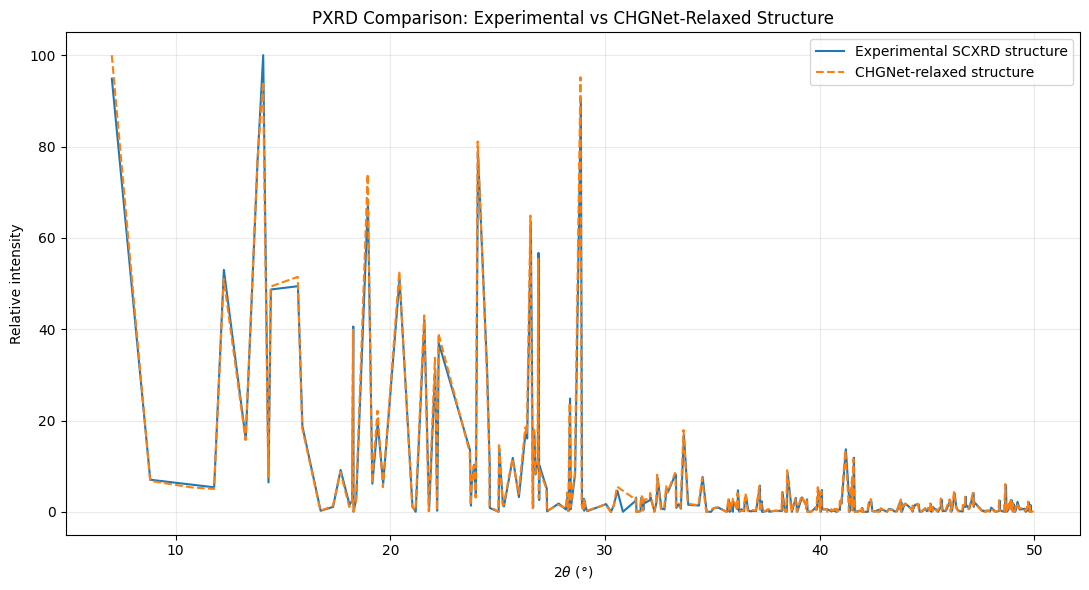

PXRD CALCULATION COMPLETE


In [52]:
print("=" * 90)
print("STEP 10 — EXPERIMENTAL VS CHGNET-RELAXED PXRD")
print("=" * 90)

from pymatgen.analysis.diffraction.xrd import XRDCalculator
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Calculate PXRD patterns
# ---------------------------------------------------------

xrd_calc = XRDCalculator(wavelength="CuKa")

pattern_exp = xrd_calc.get_pattern(structure_exp, two_theta_range=(5, 50))
pattern_relaxed = xrd_calc.get_pattern(structure_relaxed, two_theta_range=(5, 50))

# ---------------------------------------------------------
# Convert to data tables
# ---------------------------------------------------------

pxrd_exp_df = pd.DataFrame({
    "2theta_deg": pattern_exp.x,
    "Intensity_experimental_structure": pattern_exp.y
})

pxrd_relaxed_df = pd.DataFrame({
    "2theta_deg": pattern_relaxed.x,
    "Intensity_relaxed_structure": pattern_relaxed.y
})

print()
print("Experimental structure PXRD peaks:", len(pattern_exp.x))
print("Relaxed structure PXRD peaks:", len(pattern_relaxed.x))

print()
print("First 15 experimental-structure peaks:")
print(
    pxrd_exp_df.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print()
print("First 15 relaxed-structure peaks:")
print(
    pxrd_relaxed_df.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ---------------------------------------------------------
# Plot PXRD comparison
# ---------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    pattern_exp.x,
    pattern_exp.y,
    label="Experimental SCXRD structure"
)

plt.plot(
    pattern_relaxed.x,
    pattern_relaxed.y,
    label="CHGNet-relaxed structure",
    linestyle="--"
)

plt.xlabel(r"2$\theta$ (°)")
plt.ylabel("Relative intensity")
plt.title("PXRD Comparison: Experimental vs CHGNet-Relaxed Structure")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.show()

print("=" * 90)
print("PXRD CALCULATION COMPLETE")
print("=" * 90)

In [53]:
print("=" * 90)
print("STEP 11 — QUANTITATIVE PXRD AGREEMENT")
print("=" * 90)

import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from scipy.stats import pearsonr

# ---------------------------------------------------------
# 1. Create a common 2-theta grid
# ---------------------------------------------------------

theta_min = max(
    np.min(pattern_exp.x),
    np.min(pattern_relaxed.x)
)

theta_max = min(
    np.max(pattern_exp.x),
    np.max(pattern_relaxed.x)
)

common_theta = np.linspace(theta_min, theta_max, 5000)

# Interpolate both PXRD patterns onto the same grid
interp_exp = interp1d(
    pattern_exp.x,
    pattern_exp.y,
    bounds_error=False,
    fill_value=0
)

interp_relaxed = interp1d(
    pattern_relaxed.x,
    pattern_relaxed.y,
    bounds_error=False,
    fill_value=0
)

intensity_exp = interp_exp(common_theta)
intensity_relaxed = interp_relaxed(common_theta)

# Normalize
intensity_exp_norm = intensity_exp / np.max(intensity_exp)
intensity_relaxed_norm = intensity_relaxed / np.max(intensity_relaxed)

# ---------------------------------------------------------
# 2. Pearson correlation
# ---------------------------------------------------------

pearson_r, pearson_p = pearsonr(
    intensity_exp_norm,
    intensity_relaxed_norm
)

# ---------------------------------------------------------
# 3. Mean absolute intensity difference
# ---------------------------------------------------------

mae = np.mean(
    np.abs(
        intensity_exp_norm -
        intensity_relaxed_norm
    )
)

# ---------------------------------------------------------
# 4. Root mean square difference
# ---------------------------------------------------------

rmse = np.sqrt(
    np.mean(
        (
            intensity_exp_norm -
            intensity_relaxed_norm
        ) ** 2
    )
)

# ---------------------------------------------------------
# 5. Peak-by-peak matching
# ---------------------------------------------------------

peak_records = []

for i, theta_exp in enumerate(pattern_exp.x):

    # Only consider peaks in the common range
    if theta_exp < theta_min or theta_exp > theta_max:
        continue

    differences = np.abs(pattern_relaxed.x - theta_exp)

    nearest_index = np.argmin(differences)

    theta_relaxed = pattern_relaxed.x[nearest_index]

    peak_records.append({
        "Experimental_2theta_deg": theta_exp,
        "Relaxed_2theta_deg": theta_relaxed,
        "Peak_shift_deg": theta_relaxed - theta_exp,
        "Experimental_intensity": pattern_exp.y[i],
        "Relaxed_intensity": pattern_relaxed.y[nearest_index],
        "Absolute_shift_deg": abs(theta_relaxed - theta_exp)
    })

peak_match_df = pd.DataFrame(peak_records)

# ---------------------------------------------------------
# 6. Focus on experimentally significant peaks
# ---------------------------------------------------------

strong_peaks = peak_match_df[
    peak_match_df["Experimental_intensity"] >= 5
].copy()

mean_peak_shift = strong_peaks["Peak_shift_deg"].mean()
mean_absolute_peak_shift = strong_peaks["Absolute_shift_deg"].mean()
maximum_absolute_peak_shift = strong_peaks["Absolute_shift_deg"].max()

# ---------------------------------------------------------
# 7. Print results
# ---------------------------------------------------------

print()
print("PXRD quantitative comparison")
print("-" * 90)

print(f"Common 2θ range: {theta_min:.3f} – {theta_max:.3f}°")
print(f"Pearson correlation coefficient (r): {pearson_r:.6f}")
print(f"Pearson p-value: {pearson_p:.3e}")
print(f"Mean absolute intensity error: {mae:.6f}")
print(f"RMSE of normalized intensity: {rmse:.6f}")

print()
print("Peak-position agreement for experimental peaks with intensity ≥ 5")
print("-" * 90)

print(f"Number of significant experimental peaks: {len(strong_peaks)}")
print(f"Mean signed peak shift: {mean_peak_shift:.6f}°")
print(f"Mean absolute peak shift: {mean_absolute_peak_shift:.6f}°")
print(f"Maximum absolute peak shift: {maximum_absolute_peak_shift:.6f}°")

print()
print("First 20 significant peak matches:")
print(
    strong_peaks.head(20).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print()
print("=" * 90)
print("QUANTITATIVE PXRD ANALYSIS COMPLETE")
print("=" * 90)

STEP 11 — QUANTITATIVE PXRD AGREEMENT

PXRD quantitative comparison
------------------------------------------------------------------------------------------
Common 2θ range: 7.025 – 49.845°
Pearson correlation coefficient (r): 0.993305
Pearson p-value: 0.000e+00
Mean absolute intensity error: 0.010778
RMSE of normalized intensity: 0.023339

Peak-position agreement for experimental peaks with intensity ≥ 5
------------------------------------------------------------------------------------------
Number of significant experimental peaks: 56
Mean signed peak shift: -0.011195°
Mean absolute peak shift: 0.012782°
Maximum absolute peak shift: 0.026102°

First 20 significant peak matches:
 Experimental_2theta_deg  Relaxed_2theta_deg  Peak_shift_deg  Experimental_intensity  Relaxed_intensity  Absolute_shift_deg
                  7.0254              7.0217         -0.0037                 94.8585           100.0000              0.0037
                  8.8161              8.8095         -0.006

In [54]:
!pip install -q matgl

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.4/383.4 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.6/853.6 kB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 105.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 82.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.9/15.9 MB 105.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 62.9 MB/s eta 0:00:00
   ━

In [55]:
print("=" * 90)
print("STEP 12B — VERIFY MATGL / M3GNET INSTALLATION")
print("=" * 90)

import matgl
import chgnet

print()
print("MatGL version:", getattr(matgl, "__version__", "installed"))
print("CHGNet import: OK")
print("MatGL import: OK")

print()
print("Environment verification successful.")

print("=" * 90)
print("STEP 12B COMPLETE")
print("=" * 90)

STEP 12B — VERIFY MATGL / M3GNET INSTALLATION

MatGL version: 4.0.3
CHGNet import: OK
MatGL import: OK

Environment verification successful.
STEP 12B COMPLETE


In [56]:
print("=" * 90)
print("STEP 12C — AVAILABLE MATGL PRETRAINED MODELS")
print("=" * 90)

import matgl

models = matgl.get_available_pretrained_models()

print()
print("Number of available pretrained models:", len(models))
print()

for model in models:
    print(model)

print()
print("=" * 90)
print("MODEL LIST COMPLETE")
print("=" * 90)

STEP 12C — AVAILABLE MATGL PRETRAINED MODELS

Number of available pretrained models: 18

CHGNet-PES-MatPES-PBE-2025.2.10
CHGNet-PES-MatPES-r2SCAN-2025.2.10
M3GNet-Eform-MP-2018.6.1
M3GNet-Eform-MP-2019.4.1
M3GNet-PES-ANI-1x-Subset
M3GNet-PES-MatPES-PBE-2025.2
M3GNet-PES-MatPES-r2SCAN-2025.2
MEGNet-BandGap-mfi-MP-2019.4.1
MEGNet-Eform-MP-2018.6.1
QET-PES-MatPES-PBE-2025.2
QET-PES-MatPES-r2SCAN-2025.2
QET-PES-MatQ
SO3Net-PES-ANI-1x-Subset
TensorNet-PES-ANI-1x-Subset
TensorNet-PES-MatPES-PBE-2025.2
TensorNet-PES-MatPES-PBE-2025.2-m
TensorNet-PES-MatPES-r2SCAN-2025.2
TensorNet-PES-MatPES-r2SCAN-2025.2-m

MODEL LIST COMPLETE


In [57]:
print("=" * 90)
print("STEP 12D — LOAD CURRENT M3GNET PES MODEL")
print("=" * 90)

import matgl

print()
print("Loading:")
print("M3GNet-PES-MatPES-PBE-2025.2")
print()

m3gnet_potential = matgl.load_model(
    "M3GNet-PES-MatPES-PBE-2025.2"
)

print()
print("M3GNet model loaded successfully.")
print("Model type:", type(m3gnet_potential))

print()
print("=" * 90)
print("STEP 12D COMPLETE")
print("=" * 90)

STEP 12D — LOAD CURRENT M3GNET PES MODEL

Loading:
M3GNet-PES-MatPES-PBE-2025.2



model.pt: reconstructing file:   0%|          |  0.00B / 3.35kB            

model.pt: downloading bytes:           |  0.00B            

state.pt: reconstructing file:   0%|          |  0.00B / 1.23MB            

state.pt: downloading bytes:           |  0.00B            

model.json:   0%|          | 0.00/5.33k [00:00<?, ?B/s]


M3GNet model loaded successfully.
Model type: <class 'matgl.apps.pes.Potential'>

STEP 12D COMPLETE


In [58]:
print("=" * 90)
print("STEP 12E — CORRECTED M3GNET ENERGY AND FORCE EVALUATION")
print("=" * 90)

import numpy as np
from ase import Atoms
from matgl.ext.ase import PESCalculator

# ---------------------------------------------------------
# 1. Convert experimental structure to ASE
# ---------------------------------------------------------

atoms_m3gnet = Atoms(
    symbols=[site.specie.symbol for site in structure_exp],
    positions=structure_exp.cart_coords,
    cell=structure_exp.lattice.matrix,
    pbc=True
)

print()
print("Experimental cocrystal:")
print("Number of atoms:", len(atoms_m3gnet))
print("Volume:", f"{atoms_m3gnet.get_volume():.6f}", "Å³")

# ---------------------------------------------------------
# 2. Attach M3GNet calculator
# ---------------------------------------------------------

atoms_m3gnet.calc = PESCalculator(
    potential=m3gnet_potential,
    stress_unit="eV/A3",
    stress_weight=1.0
)

print()
print("M3GNet calculator attached successfully.")

# ---------------------------------------------------------
# 3. Calculate energy
# ---------------------------------------------------------

energy_m3gnet = atoms_m3gnet.get_potential_energy()

# ---------------------------------------------------------
# 4. Calculate forces
# ---------------------------------------------------------

forces_m3gnet = atoms_m3gnet.get_forces()

force_magnitudes = np.linalg.norm(
    forces_m3gnet,
    axis=1
)

max_force_m3gnet = np.max(force_magnitudes)
mean_force_m3gnet = np.mean(force_magnitudes)

# ---------------------------------------------------------
# 5. Calculate stress
# ---------------------------------------------------------

stress_m3gnet = atoms_m3gnet.get_stress()

# ---------------------------------------------------------
# 6. Print results
# ---------------------------------------------------------

print()
print("=" * 90)
print("M3GNET RESULTS — EXPERIMENTAL STRUCTURE")
print("=" * 90)

print()
print(f"Total M3GNet energy:       {energy_m3gnet:.6f} eV")

print(
    f"M3GNet energy/atom:        "
    f"{energy_m3gnet / len(atoms_m3gnet):.6f} eV/atom"
)

print(
    f"Maximum force:              "
    f"{max_force_m3gnet:.6f} eV/Å"
)

print(
    f"Mean atomic force:          "
    f"{mean_force_m3gnet:.6f} eV/Å"
)

print()
print("M3GNet stress tensor (eV/Å³):")
print(stress_m3gnet)

print()
print("=" * 90)
print("STEP 12E COMPLETE")
print("=" * 90)

STEP 12E — CORRECTED M3GNET ENERGY AND FORCE EVALUATION

Experimental cocrystal:
Number of atoms: 94
Volume: 946.779275 Å³

M3GNet calculator attached successfully.

M3GNET RESULTS — EXPERIMENTAL STRUCTURE

Total M3GNet energy:       -614.199341 eV
M3GNet energy/atom:        -6.534036 eV/atom
Maximum force:              4.537236 eV/Å
Mean atomic force:          1.096706 eV/Å

M3GNet stress tensor (eV/Å³):
[-0.02211696 -0.01531843 -0.03416751 -0.01242951 -0.00607741  0.00020814]

STEP 12E COMPLETE


In [59]:
print("=" * 90)
print("STEP 12F — M3GNET STRUCTURAL RELAXATION")
print("=" * 90)

from ase.optimize import FIRE

# ---------------------------------------------------------
# Make a fresh copy of the experimental structure
# ---------------------------------------------------------

atoms_m3gnet_relax = atoms_m3gnet.copy()

atoms_m3gnet_relax.calc = PESCalculator(
    potential=m3gnet_potential,
    stress_unit="eV/A3",
    stress_weight=1.0
)

print()
print("Starting M3GNet relaxation...")
print("Atoms:", len(atoms_m3gnet_relax))
print("Initial volume:",
      f"{atoms_m3gnet_relax.get_volume():.6f}",
      "Å³")

# ---------------------------------------------------------
# Relax atomic positions first
# ---------------------------------------------------------

optimizer = FIRE(
    atoms_m3gnet_relax,
    logfile="m3gnet_relax.log"
)

optimizer.run(
    fmax=0.05,
    steps=500
)

print()
print("M3GNet atomic relaxation completed.")

# ---------------------------------------------------------
# Final properties
# ---------------------------------------------------------

final_energy = atoms_m3gnet_relax.get_potential_energy()

final_forces = atoms_m3gnet_relax.get_forces()

final_force_magnitudes = np.linalg.norm(
    final_forces,
    axis=1
)

print()
print("=" * 90)
print("M3GNET RELAXED STRUCTURE")
print("=" * 90)

print()
print(f"Final energy:       {final_energy:.6f} eV")
print(
    f"Final energy/atom:  "
    f"{final_energy / len(atoms_m3gnet_relax):.6f} eV/atom"
)

print(
    f"Maximum force:      "
    f"{np.max(final_force_magnitudes):.6f} eV/Å"
)

print(
    f"Mean force:         "
    f"{np.mean(final_force_magnitudes):.6f} eV/Å"
)

print(
    f"Final volume:       "
    f"{atoms_m3gnet_relax.get_volume():.6f} Å³"
)

print()
print("=" * 90)
print("STEP 12F COMPLETE")
print("=" * 90)

STEP 12F — M3GNET STRUCTURAL RELAXATION

Starting M3GNet relaxation...
Atoms: 94
Initial volume: 946.779275 Å³

M3GNet atomic relaxation completed.

M3GNET RELAXED STRUCTURE

Final energy:       -617.495850 eV
Final energy/atom:  -6.569105 eV/atom
Maximum force:      0.047825 eV/Å
Mean force:         0.015785 eV/Å
Final volume:       946.779275 Å³

STEP 12F COMPLETE


In [60]:
print("=" * 90)
print("STEP 12G — EXPERIMENTAL vs CHGNET vs M3GNET")
print("=" * 90)

import numpy as np
import pandas as pd
from pymatgen.core import Structure
from pymatgen.io.ase import AseAtomsAdaptor

# ---------------------------------------------------------
# 1. Convert M3GNet-relaxed ASE structure to pymatgen
# ---------------------------------------------------------

structure_m3gnet = AseAtomsAdaptor.get_structure(
    atoms_m3gnet_relax
)

# ---------------------------------------------------------
# 2. Calculate lattice properties
# ---------------------------------------------------------

structures = {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}

comparison = []

for name, structure in structures.items():

    comparison.append({
        "Structure": name,
        "a_A": structure.lattice.a,
        "b_A": structure.lattice.b,
        "c_A": structure.lattice.c,
        "alpha_deg": structure.lattice.alpha,
        "beta_deg": structure.lattice.beta,
        "gamma_deg": structure.lattice.gamma,
        "Volume_A3": structure.volume
    })

comparison_df = pd.DataFrame(comparison)

# ---------------------------------------------------------
# 3. Print lattice comparison
# ---------------------------------------------------------

print()
print("LATTICE PARAMETERS")
print("-" * 90)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ---------------------------------------------------------
# 4. Volume changes relative to experimental structure
# ---------------------------------------------------------

experimental_volume = structure_exp.volume

print()
print("VOLUME CHANGE RELATIVE TO EXPERIMENTAL")
print("-" * 90)

for name, structure in structures.items():

    volume_change = structure.volume - experimental_volume
    volume_percent = (
        volume_change / experimental_volume
    ) * 100

    print(
        f"{name:12s} : "
        f"{volume_change:+.6f} Å³  "
        f"({volume_percent:+.4f} %)"
    )

# ---------------------------------------------------------
# 5. Atomic-position RMSD
# ---------------------------------------------------------
# Same atom ordering is maintained in all structures.
# Use Cartesian coordinates in the fixed experimental cell.

def rmsd_cartesian(structure_a, structure_b):

    coords_a = structure_a.cart_coords
    coords_b = structure_b.cart_coords

    displacement = coords_b - coords_a

    rmsd = np.sqrt(
        np.mean(
            np.sum(displacement ** 2, axis=1)
        )
    )

    maximum = np.max(
        np.linalg.norm(displacement, axis=1)
    )

    mean = np.mean(
        np.linalg.norm(displacement, axis=1)
    )

    return rmsd, mean, maximum


rmsd_chgnet = rmsd_cartesian(
    structure_exp,
    structure_relaxed
)

rmsd_m3gnet = rmsd_cartesian(
    structure_exp,
    structure_m3gnet
)

print()
print("ATOMIC DISPLACEMENT RELATIVE TO EXPERIMENTAL")
print("-" * 90)

print(
    f"CHGNet  RMSD: {rmsd_chgnet[0]:.6f} Å"
)
print(
    f"CHGNet  mean displacement: {rmsd_chgnet[1]:.6f} Å"
)
print(
    f"CHGNet  maximum displacement: {rmsd_chgnet[2]:.6f} Å"
)

print()

print(
    f"M3GNet  RMSD: {rmsd_m3gnet[0]:.6f} Å"
)
print(
    f"M3GNet  mean displacement: {rmsd_m3gnet[1]:.6f} Å"
)
print(
    f"M3GNet  maximum displacement: {rmsd_m3gnet[2]:.6f} Å"
)

print()
print("=" * 90)
print("STEP 12G COMPLETE")
print("=" * 90)

STEP 12G — EXPERIMENTAL vs CHGNET vs M3GNET

LATTICE PARAMETERS
------------------------------------------------------------------------------------------
   Structure      a_A       b_A       c_A  alpha_deg  beta_deg  gamma_deg  Volume_A3
Experimental 7.468100 10.397000 12.675600  83.673000 85.662000  75.718000 946.779275
      CHGNet 7.472735 10.404633 12.682350  83.670420 85.661723  75.720120 948.571564
      M3GNet 7.468100 10.397000 12.675600  83.673000 85.662000  75.718000 946.779275

VOLUME CHANGE RELATIVE TO EXPERIMENTAL
------------------------------------------------------------------------------------------
Experimental : +0.000000 Å³  (+0.0000 %)
CHGNet       : +1.792289 Å³  (+0.1893 %)
M3GNet       : +0.000000 Å³  (+0.0000 %)

ATOMIC DISPLACEMENT RELATIVE TO EXPERIMENTAL
------------------------------------------------------------------------------------------
CHGNet  RMSD: 0.042581 Å
CHGNet  mean displacement: 0.037879 Å
CHGNet  maximum displacement: 0.099687 Å

M3GNet  R

In [61]:
print("=" * 90)
print("STEP 12H — ATOMIC DISPLACEMENT ANALYSIS")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Calculate displacement of every atom
# ---------------------------------------------------------

exp_coords = structure_exp.cart_coords
m3_coords = structure_m3gnet.cart_coords

displacement_vectors = m3_coords - exp_coords

displacement_magnitudes = np.linalg.norm(
    displacement_vectors,
    axis=1
)

# ---------------------------------------------------------
# Build atom-by-atom table
# ---------------------------------------------------------

displacement_df = pd.DataFrame({
    "Atom_index": np.arange(len(structure_exp)),
    "Element": [
        site.specie.symbol for site in structure_exp
    ],
    "Displacement_A": displacement_magnitudes,
    "dx_A": displacement_vectors[:, 0],
    "dy_A": displacement_vectors[:, 1],
    "dz_A": displacement_vectors[:, 2]
})

# ---------------------------------------------------------
# Sort by displacement
# ---------------------------------------------------------

displacement_df = displacement_df.sort_values(
    "Displacement_A",
    ascending=False
).reset_index(drop=True)

print()
print("10 MOST DISPLACED ATOMS")
print("-" * 90)

print(
    displacement_df.head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ---------------------------------------------------------
# Statistics by element
# ---------------------------------------------------------

element_summary = (
    displacement_df
    .groupby("Element")
    .agg(
        Number_of_atoms=("Element", "count"),
        Mean_displacement_A=("Displacement_A", "mean"),
        Maximum_displacement_A=("Displacement_A", "max"),
        RMS_displacement_A=(
            "Displacement_A",
            lambda x: np.sqrt(np.mean(x**2))
        )
    )
    .sort_values(
        "Mean_displacement_A",
        ascending=False
    )
)

print()
print("DISPLACEMENT STATISTICS BY ELEMENT")
print("-" * 90)

print(
    element_summary.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)

# ---------------------------------------------------------
# Overall displacement statistics
# ---------------------------------------------------------

print()
print("OVERALL DISPLACEMENT DISTRIBUTION")
print("-" * 90)

print(
    f"Atoms with displacement < 0.10 Å: "
    f"{np.sum(displacement_magnitudes < 0.10)} / {len(displacement_magnitudes)}"
)

print(
    f"Atoms with displacement < 0.20 Å: "
    f"{np.sum(displacement_magnitudes < 0.20)} / {len(displacement_magnitudes)}"
)

print(
    f"Atoms with displacement < 0.30 Å: "
    f"{np.sum(displacement_magnitudes < 0.30)} / {len(displacement_magnitudes)}"
)

print(
    f"Atoms with displacement ≥ 0.30 Å: "
    f"{np.sum(displacement_magnitudes >= 0.30)} / {len(displacement_magnitudes)}"
)

print()
print("=" * 90)
print("STEP 12H COMPLETE")
print("=" * 90)

STEP 12H — ATOMIC DISPLACEMENT ANALYSIS

10 MOST DISPLACED ATOMS
------------------------------------------------------------------------------------------
 Atom_index Element  Displacement_A    dx_A    dy_A    dz_A
          7       H          0.7193  0.5269  0.3247  0.3666
          6       H          0.7115 -0.5218 -0.3157 -0.3665
         92       O          0.5620 -0.4823  0.0279  0.2871
         16       H          0.5612  0.4605  0.1277  0.2942
         17       H          0.5594 -0.4584 -0.1283 -0.2938
         93       O          0.5590  0.4787 -0.0282 -0.2874
          0       H          0.4559  0.1580  0.3203 -0.2833
          1       H          0.4551 -0.1564 -0.3201  0.2831
         26       H          0.4059  0.4024  0.0087  0.0525
         27       H          0.4051 -0.4016 -0.0083 -0.0526

DISPLACEMENT STATISTICS BY ELEMENT
------------------------------------------------------------------------------------------
         Number_of_atoms  Mean_displacement_A  Maximum_di

In [62]:
print("=" * 90)
print("STEP 12I — HEAVY-ATOM STRUCTURAL COMPARISON")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Identify heavy atoms
# ---------------------------------------------------------

heavy_indices = [
    i for i, site in enumerate(structure_exp)
    if site.specie.symbol != "H"
]

print()
print("Total atoms:", len(structure_exp))
print("Heavy atoms:", len(heavy_indices))
print("Hydrogen atoms:", len(structure_exp) - len(heavy_indices))

# ---------------------------------------------------------
# Experimental vs M3GNet heavy-atom displacement
# ---------------------------------------------------------

exp_heavy = structure_exp.cart_coords[heavy_indices]
m3_heavy = structure_m3gnet.cart_coords[heavy_indices]

heavy_vectors = m3_heavy - exp_heavy

heavy_magnitudes = np.linalg.norm(
    heavy_vectors,
    axis=1
)

heavy_rmsd = np.sqrt(
    np.mean(
        np.sum(heavy_vectors ** 2, axis=1)
    )
)

heavy_mean = np.mean(heavy_magnitudes)
heavy_max = np.max(heavy_magnitudes)

# ---------------------------------------------------------
# Experimental vs CHGNet heavy-atom displacement
# ---------------------------------------------------------

chg_heavy = structure_relaxed.cart_coords[heavy_indices]

chg_vectors = chg_heavy - exp_heavy

chg_magnitudes = np.linalg.norm(
    chg_vectors,
    axis=1
)

chg_heavy_rmsd = np.sqrt(
    np.mean(
        np.sum(chg_vectors ** 2, axis=1)
    )
)

chg_heavy_mean = np.mean(chg_magnitudes)
chg_heavy_max = np.max(chg_magnitudes)

# ---------------------------------------------------------
# Print comparison
# ---------------------------------------------------------

comparison_heavy = pd.DataFrame({
    "Structure": [
        "CHGNet",
        "M3GNet"
    ],
    "Heavy_atom_RMSD_A": [
        chg_heavy_rmsd,
        heavy_rmsd
    ],
    "Mean_displacement_A": [
        chg_heavy_mean,
        heavy_mean
    ],
    "Maximum_displacement_A": [
        chg_heavy_max,
        heavy_max
    ]
})

print()
print("HEAVY-ATOM DISPLACEMENT")
print("-" * 90)

print(
    comparison_heavy.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ---------------------------------------------------------
# Largest M3GNet heavy-atom movements
# ---------------------------------------------------------

heavy_table = pd.DataFrame({
    "Atom_index": heavy_indices,
    "Element": [
        structure_exp[i].specie.symbol
        for i in heavy_indices
    ],
    "Displacement_A": heavy_magnitudes
})

heavy_table = heavy_table.sort_values(
    "Displacement_A",
    ascending=False
).reset_index(drop=True)

print()
print("10 MOST DISPLACED M3GNET HEAVY ATOMS")
print("-" * 90)

print(
    heavy_table.head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print()
print("=" * 90)
print("STEP 12I COMPLETE")
print("=" * 90)

STEP 12I — HEAVY-ATOM STRUCTURAL COMPARISON

Total atoms: 94
Heavy atoms: 60
Hydrogen atoms: 34

HEAVY-ATOM DISPLACEMENT
------------------------------------------------------------------------------------------
Structure  Heavy_atom_RMSD_A  Mean_displacement_A  Maximum_displacement_A
   CHGNet           0.041145             0.035122                0.099687
   M3GNet           0.228828             0.205201                0.562042

10 MOST DISPLACED M3GNET HEAVY ATOMS
------------------------------------------------------------------------------------------
 Atom_index Element  Displacement_A
         92       O        0.562042
         93       O        0.559039
         53       C        0.364120
         52       C        0.361130
         64       C        0.327674
         65       C        0.326920
         66       C        0.322833
         67       C        0.322642
         84       N        0.308886
         85       N        0.304037

STEP 12I COMPLETE


In [63]:
print("=" * 90)
print("STEP 12J — HYDROGEN-BOND GEOMETRY COMPARISON")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Key experimentally identified intermolecular H-bonds
# Donor H, donor N, acceptor O
# ---------------------------------------------------------

hbonds = [
    ("N81-H33...O93", 81, 33, 93),
    ("N80-H32...O92", 80, 32, 92),
    ("N84-H0...O93", 84, 0, 93),
    ("N85-H1...O92", 85, 1, 92),
]

def minimum_image_distance(structure, i, j):
    """
    Calculate minimum-image distance between two atoms
    in a periodic crystal.
    """
    frac_i = structure.frac_coords[i]
    frac_j = structure.frac_coords[j]

    delta = frac_j - frac_i
    delta -= np.round(delta)

    cart_delta = np.dot(
        delta,
        structure.lattice.matrix
    )

    return np.linalg.norm(cart_delta)


def minimum_image_angle(structure, donor, hydrogen, acceptor):
    """
    Calculate D-H...A angle using minimum-image convention.
    """

    frac_D = structure.frac_coords[donor]
    frac_H = structure.frac_coords[hydrogen]
    frac_A = structure.frac_coords[acceptor]

    # H relative to donor
    dH = frac_H - frac_D
    dH -= np.round(dH)

    # A relative to H
    HA = frac_A - frac_H
    HA -= np.round(HA)

    v_DH = np.dot(
        dH,
        structure.lattice.matrix
    )

    v_HA = np.dot(
        HA,
        structure.lattice.matrix
    )

    # Vectors H->D and H->A
    v_HD = -v_DH
    v_HA = v_HA

    cosine = np.dot(v_HD, v_HA) / (
        np.linalg.norm(v_HD) *
        np.linalg.norm(v_HA)
    )

    cosine = np.clip(cosine, -1.0, 1.0)

    return np.degrees(
        np.arccos(cosine)
    )


def analyze_hbond(structure, donor, hydrogen, acceptor):

    DH = minimum_image_distance(
        structure,
        donor,
        hydrogen
    )

    HA = minimum_image_distance(
        structure,
        hydrogen,
        acceptor
    )

    DA = minimum_image_distance(
        structure,
        donor,
        acceptor
    )

    angle = minimum_image_angle(
        structure,
        donor,
        hydrogen,
        acceptor
    )

    return DH, HA, DA, angle


# ---------------------------------------------------------
# Analyze all three structures
# ---------------------------------------------------------

structures = {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}

results = []

for hb_name, donor, hydrogen, acceptor in hbonds:

    for structure_name, structure in structures.items():

        DH, HA, DA, angle = analyze_hbond(
            structure,
            donor,
            hydrogen,
            acceptor
        )

        results.append({
            "H_bond": hb_name,
            "Structure": structure_name,
            "D-H_A": DH,
            "H...A_A": HA,
            "D...A_A": DA,
            "D-H...A_angle_deg": angle
        })

hb_df = pd.DataFrame(results)

# ---------------------------------------------------------
# Print complete table
# ---------------------------------------------------------

print()
print("HYDROGEN-BOND GEOMETRY")
print("-" * 90)

print(
    hb_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ---------------------------------------------------------
# Calculate changes relative to experimental structure
# ---------------------------------------------------------

comparison = []

for hb_name in [x[0] for x in hbonds]:

    exp_row = hb_df[
        (hb_df["H_bond"] == hb_name) &
        (hb_df["Structure"] == "Experimental")
    ].iloc[0]

    for structure_name in ["CHGNet", "M3GNet"]:

        row = hb_df[
            (hb_df["H_bond"] == hb_name) &
            (hb_df["Structure"] == structure_name)
        ].iloc[0]

        comparison.append({
            "H_bond": hb_name,
            "Structure": structure_name,
            "Delta_H...A_A":
                row["H...A_A"] - exp_row["H...A_A"],
            "Delta_D...A_A":
                row["D...A_A"] - exp_row["D...A_A"],
            "Delta_angle_deg":
                row["D-H...A_angle_deg"] -
                exp_row["D-H...A_angle_deg"]
        })

comparison_df = pd.DataFrame(comparison)

print()
print("CHANGES RELATIVE TO EXPERIMENTAL STRUCTURE")
print("-" * 90)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print()
print("=" * 90)
print("STEP 12J COMPLETE")
print("=" * 90)

STEP 12J — HYDROGEN-BOND GEOMETRY COMPARISON

HYDROGEN-BOND GEOMETRY
------------------------------------------------------------------------------------------
       H_bond    Structure  D-H_A  H...A_A  D...A_A  D-H...A_angle_deg
N81-H33...O93 Experimental  1.008    1.746    2.717            160.261
N81-H33...O93       CHGNet  1.044    1.722    2.717            157.704
N81-H33...O93       M3GNet  1.037    1.867    2.792            146.672
N80-H32...O92 Experimental  1.008    1.746    2.717            160.261
N80-H32...O92       CHGNet  1.044    1.722    2.717            157.704
N80-H32...O92       M3GNet  1.037    1.866    2.792            146.804
 N84-H0...O93 Experimental  1.009    1.932    2.937            173.028
 N84-H0...O93       CHGNet  1.028    1.874    2.895            171.622
 N84-H0...O93       M3GNet  1.031    2.015    2.968            152.553
 N85-H1...O92 Experimental  1.009    1.932    2.937            173.028
 N85-H1...O92       CHGNet  1.028    1.874    2.895        

In [64]:
print("=" * 90)
print("STEP 12K — π-ASSOCIATED INTERMOLECULAR GEOMETRY COMPARISON")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Ring pairs identified from the experimental structure
# ---------------------------------------------------------
# Pair       centroid distance   plane separation   angle
# 1-8        3.652 Å             3.618 Å             7.022°
# 1-7        3.946 Å             3.375 Å             5.987°
#
# Symmetry-equivalent pairs:
# 4-10 and 4-9
# ---------------------------------------------------------

ring_pairs = [
    ("Ring 1–8", [65,67,69,71,73,75], [35,37,39,41,43,45]),
    ("Ring 1–7", [65,67,69,71,73,75], [35,45,47,79,81]),
]

structures = {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}

def ring_geometry(structure, ring1, ring2):

    coords1 = structure.cart_coords[ring1]
    coords2 = structure.cart_coords[ring2]

    # Ring centroids
    c1 = np.mean(coords1, axis=0)
    c2 = np.mean(coords2, axis=0)

    # Minimum-image centroid displacement
    frac1 = structure.lattice.get_fractional_coords(c1)
    frac2 = structure.lattice.get_fractional_coords(c2)

    delta = frac2 - frac1
    delta -= np.round(delta)

    centroid_vector = np.dot(
        delta,
        structure.lattice.matrix
    )

    centroid_distance = np.linalg.norm(
        centroid_vector
    )

    # Plane fitting using SVD
    def plane_normal(coords):

        centered = coords - np.mean(coords, axis=0)

        _, _, vh = np.linalg.svd(
            centered,
            full_matrices=False
        )

        normal = vh[-1]
        normal = normal / np.linalg.norm(normal)

        return normal

    n1 = plane_normal(coords1)
    n2 = plane_normal(coords2)

    # Plane angle
    cos_angle = np.abs(np.dot(n1, n2))
    cos_angle = np.clip(cos_angle, -1.0, 1.0)

    plane_angle = np.degrees(
        np.arccos(cos_angle)
    )

    # Interplanar separation
    midpoint_vector = centroid_vector

    plane_separation = np.abs(
        np.dot(midpoint_vector, n1)
    )

    # Lateral offset
    lateral_offset = np.sqrt(
        max(
            centroid_distance**2 -
            plane_separation**2,
            0
        )
    )

    return (
        centroid_distance,
        plane_separation,
        lateral_offset,
        plane_angle
    )

results = []

for pair_name, ring1, ring2 in ring_pairs:

    for structure_name, structure in structures.items():

        (
            centroid_distance,
            plane_separation,
            lateral_offset,
            plane_angle
        ) = ring_geometry(
            structure,
            ring1,
            ring2
        )

        results.append({
            "Ring_pair": pair_name,
            "Structure": structure_name,
            "Centroid_distance_A": centroid_distance,
            "Plane_separation_A": plane_separation,
            "Lateral_offset_A": lateral_offset,
            "Plane_angle_deg": plane_angle
        })

pi_df = pd.DataFrame(results)

print()
print("π-ASSOCIATED GEOMETRY")
print("-" * 90)

print(
    pi_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ---------------------------------------------------------
# Changes relative to experimental structure
# ---------------------------------------------------------

comparison = []

for pair_name in pi_df["Ring_pair"].unique():

    exp = pi_df[
        (pi_df["Ring_pair"] == pair_name) &
        (pi_df["Structure"] == "Experimental")
    ].iloc[0]

    for structure_name in ["CHGNet", "M3GNet"]:

        row = pi_df[
            (pi_df["Ring_pair"] == pair_name) &
            (pi_df["Structure"] == structure_name)
        ].iloc[0]

        comparison.append({
            "Ring_pair": pair_name,
            "Structure": structure_name,
            "Delta_centroid_A":
                row["Centroid_distance_A"] -
                exp["Centroid_distance_A"],
            "Delta_plane_sep_A":
                row["Plane_separation_A"] -
                exp["Plane_separation_A"],
            "Delta_lateral_A":
                row["Lateral_offset_A"] -
                exp["Lateral_offset_A"],
            "Delta_angle_deg":
                row["Plane_angle_deg"] -
                exp["Plane_angle_deg"]
        })

comparison_df = pd.DataFrame(comparison)

print()
print("CHANGES RELATIVE TO EXPERIMENTAL STRUCTURE")
print("-" * 90)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print()
print("=" * 90)
print("STEP 12K COMPLETE")
print("=" * 90)

STEP 12K — π-ASSOCIATED INTERMOLECULAR GEOMETRY COMPARISON

π-ASSOCIATED GEOMETRY
------------------------------------------------------------------------------------------
Ring_pair    Structure  Centroid_distance_A  Plane_separation_A  Lateral_offset_A  Plane_angle_deg
 Ring 1–8 Experimental                1.300               0.409             1.234           77.092
 Ring 1–8       CHGNet                1.342               0.422             1.274           77.422
 Ring 1–8       M3GNet                1.324               0.267             1.296           79.526
 Ring 1–7 Experimental                4.563               0.029             4.563           87.035
 Ring 1–7       CHGNet                4.538               0.019             4.538           86.968
 Ring 1–7       M3GNet                4.676               0.140             4.673           87.740

CHANGES RELATIVE TO EXPERIMENTAL STRUCTURE
------------------------------------------------------------------------------------------

In [65]:
print("=" * 90)
print("STEP 12K — CORRECTED π-ASSOCIATED INTERMOLECULAR GEOMETRY")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Ring pairs from the experimental structure
# ---------------------------------------------------------

ring_pairs = [
    ("Ring 1–8",
     [65,67,69,71,73,75],
     [35,37,39,41,43,45]),

    ("Ring 1–7",
     [65,67,69,71,73,75],
     [35,45,47,79,81])
]

structures = {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}

# ---------------------------------------------------------
# Unwrap a ring around its first atom
# ---------------------------------------------------------

def unwrap_ring(structure, indices):

    frac = structure.frac_coords[indices].copy()

    reference = frac[0].copy()

    for i in range(1, len(frac)):

        delta = frac[i] - reference

        delta -= np.round(delta)

        frac[i] = reference + delta

    coords = np.dot(
        frac,
        structure.lattice.matrix
    )

    return coords


# ---------------------------------------------------------
# Calculate ring plane
# ---------------------------------------------------------

def get_plane(coords):

    centroid = np.mean(coords, axis=0)

    centered = coords - centroid

    _, _, vh = np.linalg.svd(
        centered,
        full_matrices=False
    )

    normal = vh[-1]

    normal = normal / np.linalg.norm(normal)

    return centroid, normal


# ---------------------------------------------------------
# Calculate geometry between two rings
# ---------------------------------------------------------

def calculate_ring_pair(structure, ring1, ring2):

    coords1 = unwrap_ring(
        structure,
        ring1
    )

    coords2 = unwrap_ring(
        structure,
        ring2
    )

    c1, n1 = get_plane(coords1)
    c2, n2 = get_plane(coords2)

    # -----------------------------------------------------
    # Translate ring 2 to the closest periodic image
    # relative to ring 1
    # -----------------------------------------------------

    frac_c1 = structure.lattice.get_fractional_coords(c1)
    frac_c2 = structure.lattice.get_fractional_coords(c2)

    delta_frac = frac_c2 - frac_c1

    delta_frac -= np.round(delta_frac)

    delta_cart = np.dot(
        delta_frac,
        structure.lattice.matrix
    )

    c2_near = c1 + delta_cart

    centroid_distance = np.linalg.norm(
        delta_cart
    )

    # -----------------------------------------------------
    # Plane angle
    # -----------------------------------------------------

    cos_angle = np.abs(
        np.dot(n1, n2)
    )

    cos_angle = np.clip(
        cos_angle,
        -1.0,
        1.0
    )

    plane_angle = np.degrees(
        np.arccos(cos_angle)
    )

    # -----------------------------------------------------
    # Interplanar separation
    # -----------------------------------------------------

    plane_separation = np.abs(
        np.dot(
            delta_cart,
            n1
        )
    )

    # -----------------------------------------------------
    # Lateral offset
    # -----------------------------------------------------

    lateral_offset_squared = (
        centroid_distance**2 -
        plane_separation**2
    )

    lateral_offset = np.sqrt(
        max(
            lateral_offset_squared,
            0
        )
    )

    return (
        centroid_distance,
        plane_separation,
        lateral_offset,
        plane_angle
    )


# ---------------------------------------------------------
# Analyze all structures
# ---------------------------------------------------------

results = []

for pair_name, ring1, ring2 in ring_pairs:

    for structure_name, structure in structures.items():

        (
            centroid_distance,
            plane_separation,
            lateral_offset,
            plane_angle
        ) = calculate_ring_pair(
            structure,
            ring1,
            ring2
        )

        results.append({
            "Ring_pair": pair_name,
            "Structure": structure_name,
            "Centroid_distance_A": centroid_distance,
            "Plane_separation_A": plane_separation,
            "Lateral_offset_A": lateral_offset,
            "Plane_angle_deg": plane_angle
        })

pi_df_corrected = pd.DataFrame(results)

# ---------------------------------------------------------
# Print corrected geometry
# ---------------------------------------------------------

print()
print("CORRECTED π-ASSOCIATED GEOMETRY")
print("-" * 90)

print(
    pi_df_corrected.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ---------------------------------------------------------
# Compare with experimental structure
# ---------------------------------------------------------

comparison = []

for pair_name in pi_df_corrected["Ring_pair"].unique():

    exp = pi_df_corrected[
        (pi_df_corrected["Ring_pair"] == pair_name) &
        (pi_df_corrected["Structure"] == "Experimental")
    ].iloc[0]

    for structure_name in ["CHGNet", "M3GNet"]:

        row = pi_df_corrected[
            (pi_df_corrected["Ring_pair"] == pair_name) &
            (pi_df_corrected["Structure"] == structure_name)
        ].iloc[0]

        comparison.append({
            "Ring_pair": pair_name,
            "Structure": structure_name,
            "Delta_centroid_A":
                row["Centroid_distance_A"]
                - exp["Centroid_distance_A"],

            "Delta_plane_sep_A":
                row["Plane_separation_A"]
                - exp["Plane_separation_A"],

            "Delta_lateral_A":
                row["Lateral_offset_A"]
                - exp["Lateral_offset_A"],

            "Delta_angle_deg":
                row["Plane_angle_deg"]
                - exp["Plane_angle_deg"]
        })

comparison_corrected = pd.DataFrame(
    comparison
)

print()
print("CHANGES RELATIVE TO EXPERIMENTAL STRUCTURE")
print("-" * 90)

print(
    comparison_corrected.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print()
print("=" * 90)
print("STEP 12K CORRECTED COMPLETE")
print("=" * 90)

STEP 12K — CORRECTED π-ASSOCIATED INTERMOLECULAR GEOMETRY

CORRECTED π-ASSOCIATED GEOMETRY
------------------------------------------------------------------------------------------
Ring_pair    Structure  Centroid_distance_A  Plane_separation_A  Lateral_offset_A  Plane_angle_deg
 Ring 1–8 Experimental                3.652               3.618             0.496            7.022
 Ring 1–8       CHGNet                3.688               3.665             0.414            7.916
 Ring 1–8       M3GNet                3.733               3.663             0.718            3.445
 Ring 1–7 Experimental                3.946               3.375             2.044            5.987
 Ring 1–7       CHGNet                3.979               3.422             2.031            5.621
 Ring 1–7       M3GNet                3.938               3.551             1.702            8.106

CHANGES RELATIVE TO EXPERIMENTAL STRUCTURE
---------------------------------------------------------------------------------

In [66]:
print("=" * 90)
print("STEP 12L — INTERMOLECULAR CONTACT-NETWORK COMPARISON")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Define molecular components
# ---------------------------------------------------------

component_A = [
    0,2,4,6,8,10,12,14,16,18,20,22,
    48,50,52,54,56,58,60,62,64,66,68,70,72,74,76,
    82,84,92
]

component_B = [
    1,3,5,7,9,11,13,15,17,19,21,23,
    49,51,53,55,57,59,61,63,65,67,69,71,73,75,77,
    83,85,93
]

component_C = [
    24,26,28,30,32,34,36,38,40,42,44,46,
    78,80,86,88,90
]

component_D = [
    25,27,29,31,33,35,37,39,41,43,45,47,
    79,81,87,89,91
]

# Two molecular components:
# A + B = component 1
# C + D = component 2

component1 = set(component_A + component_B)
component2 = set(component_C + component_D)

print("Component 1 atoms:", len(component1))
print("Component 2 atoms:", len(component2))

# ---------------------------------------------------------
# Atomic covalent radii for simple contact screening
# ---------------------------------------------------------

vdw = {
    "H": 1.20,
    "C": 1.70,
    "N": 1.55,
    "O": 1.52,
    "S": 1.80
}

# Contact categories and thresholds
# We focus on chemically relevant close contacts
contact_types = {
    "H...O": 2.70,
    "H...N": 2.75,
    "H...S": 3.00,
    "C...H": 2.90,
    "N...O": 3.20,
    "O...O": 3.20,
    "N...N": 3.20,
    "C...C": 3.60,
    "C...N": 3.50,
    "C...O": 3.50,
    "C...S": 3.70,
    "O...S": 3.60,
    "N...S": 3.70,
    "S...S": 3.80
}

def contact_label(e1, e2):

    pair = tuple(sorted([e1, e2]))

    if pair == ("H", "O"):
        return "H...O"
    if pair == ("H", "N"):
        return "H...N"
    if pair == ("H", "S"):
        return "H...S"
    if pair == ("C", "H"):
        return "C...H"
    if pair == ("N", "O"):
        return "N...O"
    if pair == ("O", "O"):
        return "O...O"
    if pair == ("N", "N"):
        return "N...N"
    if pair == ("C", "C"):
        return "C...C"
    if pair == ("C", "N"):
        return "C...N"
    if pair == ("C", "O"):
        return "C...O"
    if pair == ("C", "S"):
        return "C...S"
    if pair == ("O", "S"):
        return "O...S"
    if pair == ("N", "S"):
        return "N...S"
    if pair == ("S", "S"):
        return "S...S"

    return None


def analyze_contacts(structure):

    coords = structure.cart_coords
    lattice = structure.lattice.matrix

    contacts = []

    # Examine only component 1 vs component 2
    for i in component1:

        for j in component2:

            e1 = structure[i].specie.symbol
            e2 = structure[j].specie.symbol

            label = contact_label(e1, e2)

            if label is None:
                continue

            threshold = contact_types[label]

            # Minimum-image displacement
            fi = structure.frac_coords[i]
            fj = structure.frac_coords[j]

            delta = fj - fi
            delta -= np.round(delta)

            vector = np.dot(
                delta,
                lattice
            )

            distance = np.linalg.norm(vector)

            if distance <= threshold:

                contacts.append({
                    "i": i,
                    "j": j,
                    "Element_pair": label,
                    "Distance_A": distance
                })

    return pd.DataFrame(contacts)


# ---------------------------------------------------------
# Analyze all structures
# ---------------------------------------------------------

structures = {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}

contact_tables = {}

for name, structure in structures.items():

    df = analyze_contacts(structure)

    contact_tables[name] = df

    print()
    print(name)
    print("-" * 90)

    print("Total screened contacts:", len(df))

    if len(df) > 0:

        summary = (
            df.groupby("Element_pair")
            .agg(
                Count=("Distance_A", "count"),
                Minimum_A=("Distance_A", "min"),
                Mean_A=("Distance_A", "mean")
            )
            .sort_values("Minimum_A")
        )

        print(
            summary.to_string(
                float_format=lambda x: f"{x:.3f}"
            )
        )

# ---------------------------------------------------------
# Compare contact counts
# ---------------------------------------------------------

summary_rows = []

for name, df in contact_tables.items():

    summary_rows.append({
        "Structure": name,
        "Total_contacts": len(df),
        "H...O": int(
            (df["Element_pair"] == "H...O").sum()
        ),
        "C...H": int(
            (df["Element_pair"] == "C...H").sum()
        ),
        "N...O": int(
            (df["Element_pair"] == "N...O").sum()
        ),
        "C...C": int(
            (df["Element_pair"] == "C...C").sum()
        )
    })

summary_df = pd.DataFrame(summary_rows)

print()
print("=" * 90)
print("CONTACT-NETWORK SUMMARY")
print("-" * 90)

print(
    summary_df.to_string(
        index=False
    )
)

print()
print("=" * 90)
print("STEP 12L COMPLETE")
print("=" * 90)

STEP 12L — INTERMOLECULAR CONTACT-NETWORK COMPARISON
Component 1 atoms: 60
Component 2 atoms: 34

Experimental
------------------------------------------------------------------------------------------
Total screened contacts: 56
              Count  Minimum_A  Mean_A
Element_pair                          
H...O             8      1.746   2.300
C...H             8      2.707   2.792
N...O             4      2.717   2.855
C...O            10      3.249   3.338
C...C            24      3.387   3.509
O...S             2      3.545   3.545

CHGNet
------------------------------------------------------------------------------------------
Total screened contacts: 62
              Count  Minimum_A  Mean_A
Element_pair                          
H...O            10      1.722   2.334
C...H             8      2.685   2.809
N...O             4      2.717   2.836
C...O            12      3.243   3.368
C...C            26      3.339   3.525
O...S             2      3.533   3.533

M3GNet
-----------

In [67]:
print("=" * 90)
print("STEP 12M — EXPERIMENTAL CONTACT PERSISTENCE")
print("=" * 90)

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Use the experimentally identified intermolecular contacts
# as the reference network.
# ---------------------------------------------------------

experimental_contacts = contact_tables["Experimental"].copy()

# ---------------------------------------------------------
# Distance threshold for considering an experimental contact
# preserved in another structure.
#
# We use the same contact-specific screening thresholds.
# ---------------------------------------------------------

def contact_exists(
    structure,
    i,
    j,
    element_pair,
    reference_distance
):

    fi = structure.frac_coords[i]
    fj = structure.frac_coords[j]

    delta = fj - fi
    delta -= np.round(delta)

    vector = np.dot(
        delta,
        structure.lattice.matrix
    )

    distance = np.linalg.norm(vector)

    # Allow a modest structural change while retaining
    # the experimentally observed contact.
    #
    # Maximum criterion:
    # either remain within the original contact cutoff
    # OR remain within +0.30 Å of the experimental contact.

    cutoff = contact_types[element_pair]

    preserved = (
        distance <= cutoff
        or
        distance <= reference_distance + 0.30
    )

    return distance, preserved


# ---------------------------------------------------------
# Evaluate every experimental contact
# ---------------------------------------------------------

rows = []

for _, contact in experimental_contacts.iterrows():

    i = int(contact["i"])
    j = int(contact["j"])

    pair = contact["Element_pair"]
    reference_distance = contact["Distance_A"]

    row = {
        "i": i,
        "j": j,
        "Element_pair": pair,
        "Experimental_A": reference_distance
    }

    for structure_name in ["CHGNet", "M3GNet"]:

        distance, preserved = contact_exists(
            structures[structure_name],
            i,
            j,
            pair,
            reference_distance
        )

        row[
            structure_name + "_A"
        ] = distance

        row[
            structure_name + "_preserved"
        ] = preserved

    rows.append(row)


persistence_df = pd.DataFrame(rows)

# ---------------------------------------------------------
# Overall persistence
# ---------------------------------------------------------

total_contacts = len(
    persistence_df
)

chg_preserved = int(
    persistence_df["CHGNet_preserved"].sum()
)

m3_preserved = int(
    persistence_df["M3GNet_preserved"].sum()
)

chg_percent = (
    100 * chg_preserved / total_contacts
)

m3_percent = (
    100 * m3_preserved / total_contacts
)

print()
print("EXPERIMENTAL CONTACT NETWORK")
print("-" * 90)

print("Reference contacts:", total_contacts)

print(
    f"CHGNet preserved: {chg_preserved}/{total_contacts} "
    f"({chg_percent:.2f}%)"
)

print(
    f"M3GNet preserved: {m3_preserved}/{total_contacts} "
    f"({m3_percent:.2f}%)"
)

# ---------------------------------------------------------
# Persistence by interaction type
# ---------------------------------------------------------

type_rows = []

for pair in sorted(
    persistence_df["Element_pair"].unique()
):

    subset = persistence_df[
        persistence_df["Element_pair"] == pair
    ]

    n = len(subset)

    chg = int(
        subset["CHGNet_preserved"].sum()
    )

    m3 = int(
        subset["M3GNet_preserved"].sum()
    )

    type_rows.append({
        "Interaction": pair,
        "Experimental_contacts": n,
        "CHGNet_preserved": chg,
        "CHGNet_percent": 100 * chg / n,
        "M3GNet_preserved": m3,
        "M3GNet_percent": 100 * m3 / n
    })

type_df = pd.DataFrame(type_rows)

print()
print("PERSISTENCE BY INTERACTION TYPE")
print("-" * 90)

print(
    type_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

# ---------------------------------------------------------
# Identify contacts that changed substantially
# ---------------------------------------------------------

persistence_df["CHGNet_delta_A"] = (
    persistence_df["CHGNet_A"]
    -
    persistence_df["Experimental_A"]
)

persistence_df["M3GNet_delta_A"] = (
    persistence_df["M3GNet_A"]
    -
    persistence_df["Experimental_A"]
)

print()
print("LARGEST M3GNET CONTACT CHANGES")
print("-" * 90)

largest_changes = (
    persistence_df
    .assign(
        abs_change=lambda x:
        np.abs(x["M3GNet_delta_A"])
    )
    .sort_values(
        "abs_change",
        ascending=False
    )
    .head(15)
)

print(
    largest_changes[
        [
            "i",
            "j",
            "Element_pair",
            "Experimental_A",
            "CHGNet_A",
            "M3GNet_A",
            "CHGNet_delta_A",
            "M3GNet_delta_A"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print()
print("=" * 90)
print("STEP 12M COMPLETE")
print("=" * 90)

STEP 12M — EXPERIMENTAL CONTACT PERSISTENCE

EXPERIMENTAL CONTACT NETWORK
------------------------------------------------------------------------------------------
Reference contacts: 56
CHGNet preserved: 56/56 (100.00%)
M3GNet preserved: 50/56 (89.29%)

PERSISTENCE BY INTERACTION TYPE
------------------------------------------------------------------------------------------
Interaction  Experimental_contacts  CHGNet_preserved  CHGNet_percent  M3GNet_preserved  M3GNet_percent
      C...C                     24                24          100.00                24          100.00
      C...H                      8                 8          100.00                 6           75.00
      C...O                     10                10          100.00                 8           80.00
      H...O                      8                 8          100.00                 8          100.00
      N...O                      4                 4          100.00                 4          100.00
   

STEP 12N — THREE-STRUCTURE PXRD COMPARISON

Experimental
------------------------------------------------------------------------------------------
Number of peaks: 315
Strongest peak: 14.0773°

CHGNet
------------------------------------------------------------------------------------------
Number of peaks: 318
Strongest peak: 7.0217°

M3GNet
------------------------------------------------------------------------------------------
Number of peaks: 315
Strongest peak: 28.8781°


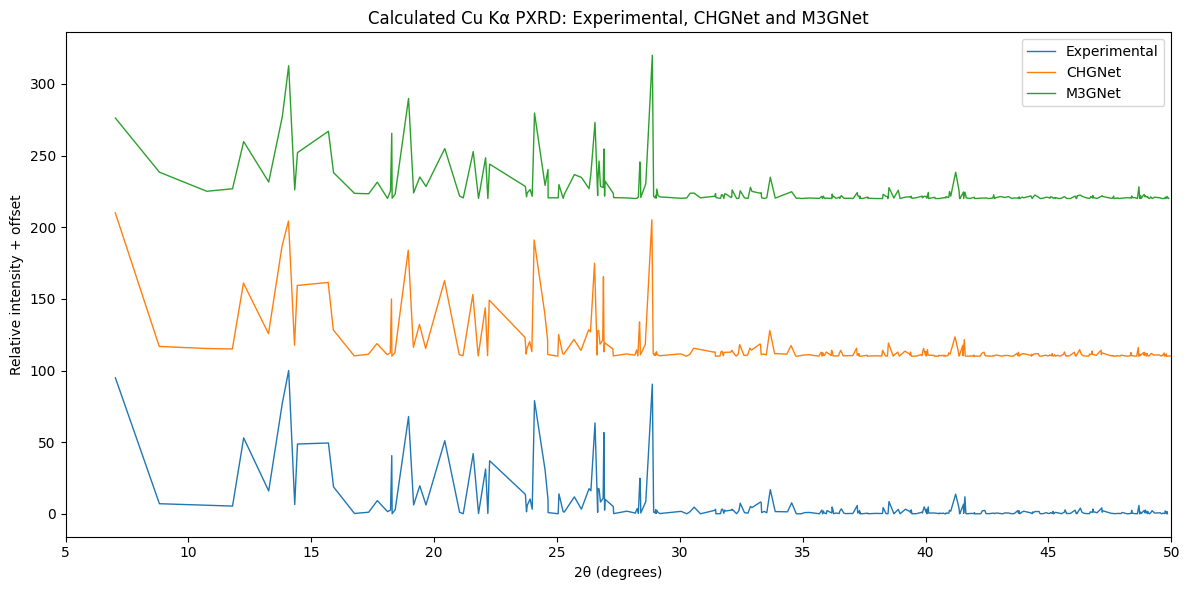


PXRD AGREEMENT WITH EXPERIMENTAL-STRUCTURE CALCULATION
------------------------------------------------------------------------------------------
Structure  Pearson_r  Normalized_MAE  Normalized_RMSE
   CHGNet   0.958048        1.640319         4.137372
   M3GNet   0.962650        1.765629         4.239961

STEP 12N COMPLETE


In [68]:
print("=" * 90)
print("STEP 12N — THREE-STRUCTURE PXRD COMPARISON")
print("=" * 90)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pymatgen.analysis.diffraction.xrd import XRDCalculator

# ---------------------------------------------------------
# Calculate Cu K-alpha PXRD
# ---------------------------------------------------------

calculator = XRDCalculator(
    wavelength="CuKa"
)

patterns = {}

for name, structure in {
    "Experimental": structure_exp,
    "CHGNet": structure_relaxed,
    "M3GNet": structure_m3gnet
}.items():

    pattern = calculator.get_pattern(
        structure,
        two_theta_range=(5, 50)
    )

    patterns[name] = pattern

# ---------------------------------------------------------
# Convert patterns to DataFrames
# ---------------------------------------------------------

pxrd_tables = {}

for name, pattern in patterns.items():

    df = pd.DataFrame({
        "2theta_deg": pattern.x,
        "Intensity": pattern.y
    })

    # Normalize to 100
    df["Relative_intensity"] = (
        df["Intensity"] /
        df["Intensity"].max() *
        100
    )

    pxrd_tables[name] = df

    print()
    print(name)
    print("-" * 90)
    print("Number of peaks:", len(df))
    print(
        "Strongest peak:",
        f"{df.loc[df['Intensity'].idxmax(), '2theta_deg']:.4f}°"
    )

# ---------------------------------------------------------
# Plot all three PXRD patterns
# ---------------------------------------------------------

plt.figure(figsize=(12, 6))

offsets = {
    "Experimental": 0,
    "CHGNet": 1,
    "M3GNet": 2
}

for name, df in pxrd_tables.items():

    y = (
        df["Relative_intensity"].values
        + offsets[name] * 110
    )

    plt.plot(
        df["2theta_deg"],
        y,
        linewidth=1.0,
        label=name
    )

plt.xlabel(r"2θ (degrees)")
plt.ylabel("Relative intensity + offset")
plt.title("Calculated Cu Kα PXRD: Experimental, CHGNet and M3GNet")
plt.xlim(5, 50)
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Quantitative comparison
# ---------------------------------------------------------

def interpolate_pattern(reference_df, target_df):

    x_ref = reference_df["2theta_deg"].values
    y_ref = reference_df["Relative_intensity"].values

    x_target = target_df["2theta_deg"].values
    y_target = target_df["Relative_intensity"].values

    y_interp = np.interp(
        x_ref,
        x_target,
        y_target,
        left=0,
        right=0
    )

    return x_ref, y_ref, y_interp


reference = pxrd_tables["Experimental"]

comparison_rows = []

for name in ["CHGNet", "M3GNet"]:

    x, y_exp, y_calc = interpolate_pattern(
        reference,
        pxrd_tables[name]
    )

    pearson = np.corrcoef(
        y_exp,
        y_calc
    )[0, 1]

    mae = np.mean(
        np.abs(
            y_exp - y_calc
        )
    )

    rmse = np.sqrt(
        np.mean(
            (y_exp - y_calc) ** 2
        )
    )

    comparison_rows.append({
        "Structure": name,
        "Pearson_r": pearson,
        "Normalized_MAE": mae,
        "Normalized_RMSE": rmse
    })

pxrd_comparison = pd.DataFrame(
    comparison_rows
)

print()
print("=" * 90)
print("PXRD AGREEMENT WITH EXPERIMENTAL-STRUCTURE CALCULATION")
print("-" * 90)

print(
    pxrd_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print()
print("=" * 90)
print("STEP 12N COMPLETE")
print("=" * 90)

In [69]:
# ============================================================
# CELL 1 — LOAD EXISTING CHGNet MD TRAJECTORY
# ============================================================

from ase.io import read
import os
import numpy as np

trajectory_file = "/content/cocrystal_2ps.traj"

# Check that the trajectory exists
if not os.path.exists(trajectory_file):
    raise FileNotFoundError(
        f"Trajectory not found: {trajectory_file}\n"
        "Make sure cocrystal_2ps.traj is present in /content."
    )

# Load all frames
md_frames = read(trajectory_file, index=":")

print("=" * 65)
print("CHGNet MD TRAJECTORY CHECK")
print("=" * 65)

print(f"Trajectory file : {trajectory_file}")
print(f"Number of frames: {len(md_frames)}")
print(f"Atoms per frame : {len(md_frames[0])}")
print(f"Initial time    : 0.000 ps")
print(f"Final time      : {(len(md_frames)-1) * 0.001:.3f} ps")
print(f"Cell volume     : {md_frames[0].get_volume():.3f} Å³")

print("\nFirst frame:")
print(md_frames[0])

print("\nLast frame:")
print(md_frames[-1])

print("\n" + "=" * 65)
print("TRAJECTORY LOADED SUCCESSFULLY")
print("=" * 65)

CHGNet MD TRAJECTORY CHECK
Trajectory file : /content/cocrystal_2ps.traj
Number of frames: 201
Atoms per frame : 94
Initial time    : 0.000 ps
Final time      : 0.200 ps
Cell volume     : 948.572 Å³

First frame:
Atoms(symbols='C44H34N6O8S2', pbc=True, cell=[[7.451327529909521, -2.9806686289588488e-05, 0.5652313172995205], [2.4868194906982515, 10.037784339625409, 1.1467358819985776], [7.302746304981388e-05, 0.00042205514245876707, 12.682349750649669]], momenta=..., calculator=SinglePointCalculator(...))

Last frame:
Atoms(symbols='C44H34N6O8S2', pbc=True, cell=[[7.451327529909521, -2.9806686289588488e-05, 0.5652313172995205], [2.4868194906982515, 10.037784339625409, 1.1467358819985776], [7.302746304981388e-05, 0.00042205514245876707, 12.682349750649669]], momenta=..., calculator=SinglePointCalculator(...))

TRAJECTORY LOADED SUCCESSFULLY


In [70]:
# ============================================================
# CELL 2 — MD TIME AXIS AND BASIC TRAJECTORY PROPERTIES
# ============================================================

import numpy as np

# Your original MD settings
timestep_fs = 1.0

# 201 saved frames from 0 to 2000 fs
n_frames = len(md_frames)

# The trajectory contains 2000 MD steps distributed across 201 saved frames
total_time_fs = 2000.0

# Generate correct time axis
time_ps = np.linspace(
    0.0,
    total_time_fs / 1000.0,
    n_frames
)

# Calculate cell volumes for every frame
volumes = np.array([
    atoms.get_volume()
    for atoms in md_frames
])

# Calculate center-of-mass positions
com_positions = np.array([
    atoms.get_center_of_mass()
    for atoms in md_frames
])

print("=" * 65)
print("MD TRAJECTORY TIME AND BASIC PROPERTIES")
print("=" * 65)

print(f"Number of frames       : {n_frames}")
print(f"Atoms per frame        : {len(md_frames[0])}")
print(f"MD timestep            : {timestep_fs:.1f} fs")
print(f"Total simulation time  : {time_ps[-1]:.3f} ps")
print(f"Time interval/frame    : {time_ps[1]-time_ps[0]:.4f} ps")

print("\nCell volume:")
print(f"Initial volume         : {volumes[0]:.6f} Å³")
print(f"Final volume           : {volumes[-1]:.6f} Å³")
print(f"Minimum volume         : {volumes.min():.6f} Å³")
print(f"Maximum volume         : {volumes.max():.6f} Å³")
print(f"Volume range           : {volumes.max()-volumes.min():.6f} Å³")

print("\nTime axis:")
print(f"First 5 times          : {time_ps[:5]}")
print(f"Last 5 times           : {time_ps[-5:]}")

print("\nVariables created:")
print("  md_frames")
print("  time_ps")
print("  volumes")
print("  com_positions")

print("\n" + "=" * 65)
print("CELL 2 COMPLETE")
print("=" * 65)

MD TRAJECTORY TIME AND BASIC PROPERTIES
Number of frames       : 201
Atoms per frame        : 94
MD timestep            : 1.0 fs
Total simulation time  : 2.000 ps
Time interval/frame    : 0.0100 ps

Cell volume:
Initial volume         : 948.571564 Å³
Final volume           : 948.571564 Å³
Minimum volume         : 948.571564 Å³
Maximum volume         : 948.571564 Å³
Volume range           : 0.000000 Å³

Time axis:
First 5 times          : [0.   0.01 0.02 0.03 0.04]
Last 5 times           : [1.96 1.97 1.98 1.99 2.  ]

Variables created:
  md_frames
  time_ps
  volumes
  com_positions

CELL 2 COMPLETE


In [71]:
# ============================================================
# CELL 3 — MD ENERGY AND TEMPERATURE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import os

log_file = "/content/cocrystal_2ps.log"

if not os.path.exists(log_file):
    raise FileNotFoundError(
        f"MD log file not found: {log_file}\n"
        "Make sure cocrystal_2ps.log is present in /content."
    )

# Read the CHGNet MD log
md_log = pd.read_csv(log_file, delim_whitespace=True)

# Display column names
print("=" * 65)
print("MD LOG FILE")
print("=" * 65)

print("Columns found:")
print(list(md_log.columns))

print("\nNumber of log records:", len(md_log))

print("\nFirst 5 records:")
print(md_log.head())

print("\nLast 5 records:")
print(md_log.tail())

# ------------------------------------------------------------
# Extract columns
# ------------------------------------------------------------

time_log = md_log["Time[ps]"].to_numpy()
etot = md_log["Etot[eV]"].to_numpy()
epot = md_log["Epot[eV]"].to_numpy()
ekin = md_log["Ekin[eV]"].to_numpy()
temperature = md_log["T[K]"].to_numpy()

# ------------------------------------------------------------
# Basic statistics
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ENERGY AND TEMPERATURE STATISTICS")
print("=" * 65)

print("\nPotential energy:")
print(f"Initial : {epot[0]:.6f} eV")
print(f"Final   : {epot[-1]:.6f} eV")
print(f"Minimum : {epot.min():.6f} eV")
print(f"Maximum : {epot.max():.6f} eV")
print(f"Range   : {epot.max()-epot.min():.6f} eV")

print("\nKinetic energy:")
print(f"Initial : {ekin[0]:.6f} eV")
print(f"Final   : {ekin[-1]:.6f} eV")
print(f"Minimum : {ekin.min():.6f} eV")
print(f"Maximum : {ekin.max():.6f} eV")

print("\nTotal energy:")
print(f"Initial : {etot[0]:.6f} eV")
print(f"Final   : {etot[-1]:.6f} eV")
print(f"Minimum : {etot.min():.6f} eV")
print(f"Maximum : {etot.max():.6f} eV")
print(f"Range   : {etot.max()-etot.min():.6f} eV")

print("\nTemperature:")
print(f"Initial : {temperature[0]:.2f} K")
print(f"Final   : {temperature[-1]:.2f} K")
print(f"Minimum : {temperature.min():.2f} K")
print(f"Maximum : {temperature.max():.2f} K")
print(f"Average : {temperature.mean():.2f} K")

# ------------------------------------------------------------
# Store variables for later cells
# ------------------------------------------------------------

md_results = pd.DataFrame({
    "Time_ps": time_log,
    "Etot_eV": etot,
    "Epot_eV": epot,
    "Ekin_eV": ekin,
    "Temperature_K": temperature
})

print("\n" + "=" * 65)
print("Variables created:")
print("  md_log")
print("  time_log")
print("  etot")
print("  epot")
print("  ekin")
print("  temperature")
print("  md_results")
print("=" * 65)

print("\nCELL 3 COMPLETE")

MD LOG FILE
Columns found:
['Time[ps]', 'Etot[eV]', 'Epot[eV]', 'Ekin[eV]', 'T[K]']

Number of log records: 201

First 5 records:
   Time[ps]  Etot[eV]  Epot[eV]  Ekin[eV]  T[K]
0      0.00 -639.2873 -639.2873    0.0000   0.0
1      0.01 -639.2761 -639.2950    0.0190   1.6
2      0.02 -639.1778 -639.2808    0.1030   8.5
3      0.03 -638.8637 -639.1977    0.3340  27.5
4      0.04 -638.5469 -639.2118    0.6649  54.7

Last 5 records:
     Time[ps]  Etot[eV]  Epot[eV]  Ekin[eV]   T[K]
196      1.96 -632.0301 -636.3119    4.2818  352.4
197      1.97 -632.0722 -636.0894    4.0172  330.6
198      1.98 -632.0819 -635.6469    3.5649  293.4
199      1.99 -632.0673 -635.6985    3.6312  298.9
200      2.00 -632.0744 -635.8300    3.7556  309.1

ENERGY AND TEMPERATURE STATISTICS

Potential energy:
Initial : -639.287300 eV
Final   : -635.830000 eV
Minimum : -639.295000 eV
Maximum : -634.772800 eV
Range   : 4.522200 eV

Kinetic energy:
Initial : 0.000000 eV
Final   : 3.755600 eV
Minimum : 0.000000 eV


/tmp/ipykernel_1546/725538967.py:18: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  md_log = pd.read_csv(log_file, delim_whitespace=True)


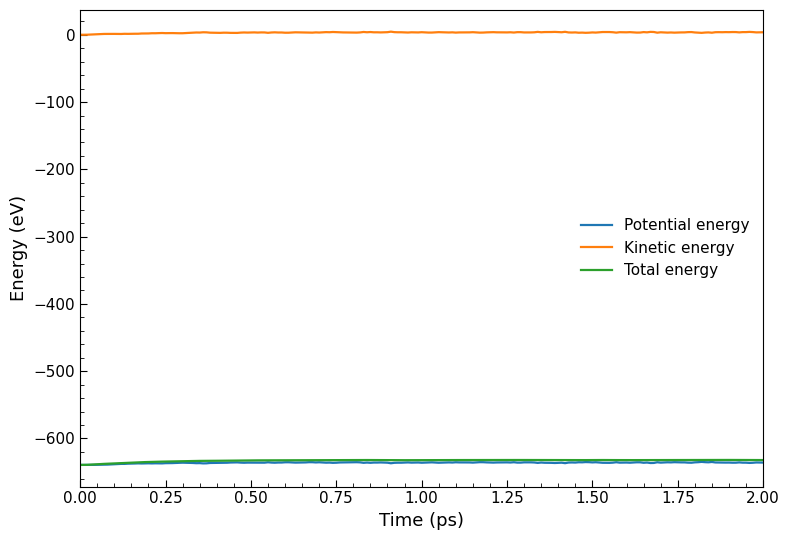

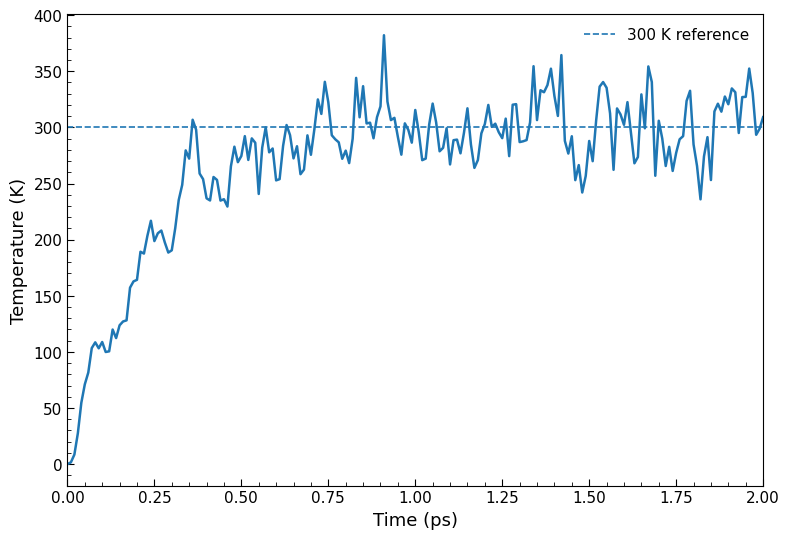

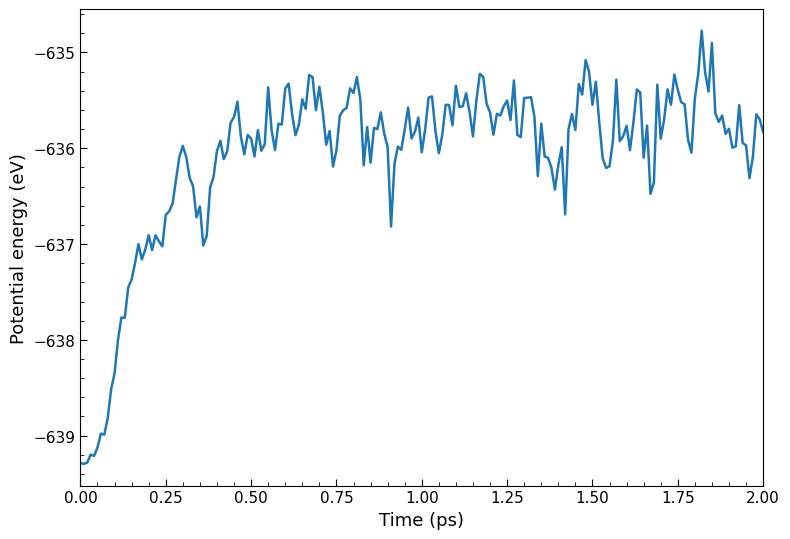

PUBLICATION FIGURES GENERATED
/content/MD_publication_figures/Figure_MD_Energy.pdf
/content/MD_publication_figures/Figure_MD_Energy.png
/content/MD_publication_figures/Figure_MD_Potential_Energy.pdf
/content/MD_publication_figures/Figure_MD_Potential_Energy.png
/content/MD_publication_figures/Figure_MD_Temperature.pdf
/content/MD_publication_figures/Figure_MD_Temperature.png

All figures saved at 600 dpi where applicable.
CELL 4 COMPLETE


In [72]:
# ============================================================
# CELL 4 — PUBLICATION-QUALITY MD ENERGY & TEMPERATURE PLOTS
# ============================================================

import matplotlib.pyplot as plt
import os

# Output directory
output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# FIGURE 1 — Potential, kinetic and total energy
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    time_log,
    epot,
    linewidth=1.6,
    label="Potential energy"
)

ax.plot(
    time_log,
    ekin,
    linewidth=1.6,
    label="Kinetic energy"
)

ax.plot(
    time_log,
    etot,
    linewidth=1.6,
    label="Total energy"
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("Energy (eV)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=11
)

fig.tight_layout()

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Energy.png"),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Energy.pdf"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# FIGURE 2 — Temperature versus time
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    time_log,
    temperature,
    linewidth=1.8
)

ax.axhline(
    300,
    linestyle="--",
    linewidth=1.2,
    label="300 K reference"
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("Temperature (K)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=11
)

fig.tight_layout()

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Temperature.png"),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Temperature.pdf"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# FIGURE 3 — Potential energy only
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    time_log,
    epot,
    linewidth=1.8
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("Potential energy (eV)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

fig.tight_layout()

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Potential_Energy.png"),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(output_dir, "Figure_MD_Potential_Energy.pdf"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# List generated files
# ------------------------------------------------------------

print("=" * 65)
print("PUBLICATION FIGURES GENERATED")
print("=" * 65)

for filename in sorted(os.listdir(output_dir)):
    print(os.path.join(output_dir, filename))

print("\nAll figures saved at 600 dpi where applicable.")
print("CELL 4 COMPLETE")

MD STRUCTURAL DISPLACEMENT ANALYSIS

All-atom RMSD:
Initial : 0.0000 Å
Final   : 0.5348 Å
Maximum : 0.7395 Å
Average : 0.5925 Å

Heavy-atom RMSD:
Initial : 0.0000 Å
Final   : 0.4388 Å
Maximum : 0.6267 Å
Average : 0.5161 Å

Mean atomic displacement:
Initial : 0.0000 Å
Final   : 0.4847 Å
Maximum : 0.6577 Å

Maximum individual atomic displacement:
Initial : 0.0000 Å
Final   : 1.3682 Å
Maximum : 2.5393 Å


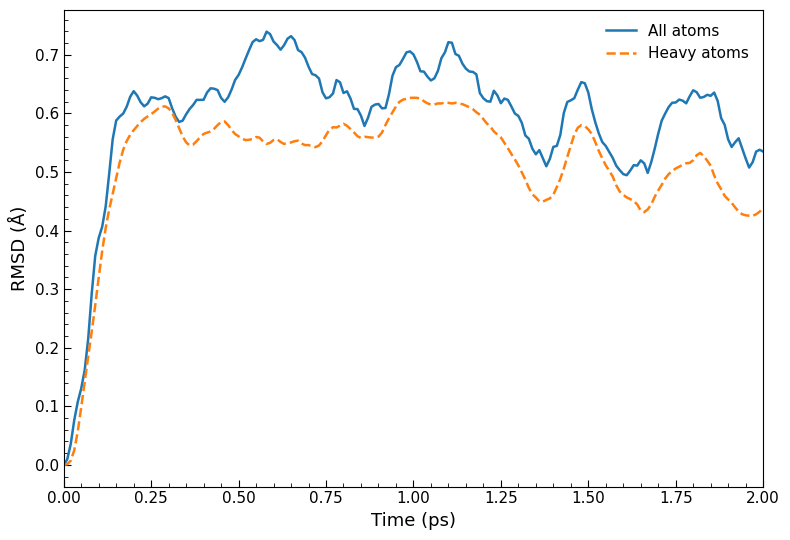


RMSD FIGURE SAVED
/content/MD_publication_figures/Figure_MD_RMSD.png
/content/MD_publication_figures/Figure_MD_RMSD.pdf
/content/MD_publication_figures/MD_RMSD_Displacement.csv

CELL 5 COMPLETE


In [73]:
# ============================================================
# CELL 5 — MD RMSD AND ATOMIC DISPLACEMENT
# CORRECTED FOR ASE PERIODIC BOUNDARY CONDITIONS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------
# Reference structure = first MD frame
# ------------------------------------------------------------

reference = md_frames[0]

reference_positions = reference.get_positions().copy()

# Atomic symbols
symbols = np.array(reference.get_chemical_symbols())

# Heavy-atom mask
heavy_mask = symbols != "H"

# Results
rmsd_all = []
rmsd_heavy = []
mean_displacement = []
max_displacement = []

# ------------------------------------------------------------
# Calculate periodic minimum-image displacement
# ------------------------------------------------------------

for atoms in md_frames:

    cell = atoms.get_cell().array

    current_positions = atoms.get_positions()

    # Convert reference and current Cartesian coordinates
    # to fractional coordinates
    frac_reference = np.linalg.solve(
        cell.T,
        reference_positions.T
    ).T

    frac_current = np.linalg.solve(
        cell.T,
        current_positions.T
    ).T

    # Fractional displacement
    frac_difference = frac_current - frac_reference

    # Minimum-image convention
    frac_difference -= np.round(frac_difference)

    # Convert displacement back to Cartesian coordinates
    cart_difference = frac_difference @ cell

    # Magnitude of displacement for every atom
    distances = np.linalg.norm(
        cart_difference,
        axis=1
    )

    # All-atom RMSD
    rmsd_all.append(
        np.sqrt(np.mean(distances**2))
    )

    # Heavy-atom RMSD
    heavy_distances = distances[heavy_mask]

    rmsd_heavy.append(
        np.sqrt(np.mean(heavy_distances**2))
    )

    # Mean displacement
    mean_displacement.append(
        np.mean(distances)
    )

    # Maximum displacement
    max_displacement.append(
        np.max(distances)
    )

# Convert lists to arrays
rmsd_all = np.array(rmsd_all)
rmsd_heavy = np.array(rmsd_heavy)
mean_displacement = np.array(mean_displacement)
max_displacement = np.array(max_displacement)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("=" * 65)
print("MD STRUCTURAL DISPLACEMENT ANALYSIS")
print("=" * 65)

print("\nAll-atom RMSD:")
print(f"Initial : {rmsd_all[0]:.4f} Å")
print(f"Final   : {rmsd_all[-1]:.4f} Å")
print(f"Maximum : {rmsd_all.max():.4f} Å")
print(f"Average : {rmsd_all.mean():.4f} Å")

print("\nHeavy-atom RMSD:")
print(f"Initial : {rmsd_heavy[0]:.4f} Å")
print(f"Final   : {rmsd_heavy[-1]:.4f} Å")
print(f"Maximum : {rmsd_heavy.max():.4f} Å")
print(f"Average : {rmsd_heavy.mean():.4f} Å")

print("\nMean atomic displacement:")
print(f"Initial : {mean_displacement[0]:.4f} Å")
print(f"Final   : {mean_displacement[-1]:.4f} Å")
print(f"Maximum : {mean_displacement.max():.4f} Å")

print("\nMaximum individual atomic displacement:")
print(f"Initial : {max_displacement[0]:.4f} Å")
print(f"Final   : {max_displacement[-1]:.4f} Å")
print(f"Maximum : {max_displacement.max():.4f} Å")

# ------------------------------------------------------------
# Save numerical results
# ------------------------------------------------------------

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

rmsd_results = np.column_stack([
    time_ps,
    rmsd_all,
    rmsd_heavy,
    mean_displacement,
    max_displacement
])

np.savetxt(
    os.path.join(output_dir, "MD_RMSD_Displacement.csv"),
    rmsd_results,
    delimiter=",",
    header=(
        "Time_ps,"
        "RMSD_all_A,"
        "RMSD_heavy_A,"
        "Mean_displacement_A,"
        "Max_displacement_A"
    ),
    comments=""
)

# ------------------------------------------------------------
# Publication-quality RMSD figure
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    time_ps,
    rmsd_all,
    linewidth=1.8,
    label="All atoms"
)

ax.plot(
    time_ps,
    rmsd_heavy,
    linewidth=1.8,
    linestyle="--",
    label="Heavy atoms"
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("RMSD (Å)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=11
)

fig.tight_layout()

fig.savefig(
    os.path.join(output_dir, "Figure_MD_RMSD.png"),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(output_dir, "Figure_MD_RMSD.pdf"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\n" + "=" * 65)
print("RMSD FIGURE SAVED")
print("=" * 65)

print(os.path.join(output_dir, "Figure_MD_RMSD.png"))
print(os.path.join(output_dir, "Figure_MD_RMSD.pdf"))
print(os.path.join(output_dir, "MD_RMSD_Displacement.csv"))

print("\nCELL 5 COMPLETE")

RDF ANALYSIS
Hydrogen atoms : 34
Carbon atoms   : 44
Nitrogen atoms : 6
Oxygen atoms   : 8
H-O   | pairs sampled:   54672 | counts:   37333
N-O   | pairs sampled:    9648 | counts:    8004
C-C   | pairs sampled:  190146 | counts:  128215
C-H   | pairs sampled:  300696 | counts:  223231


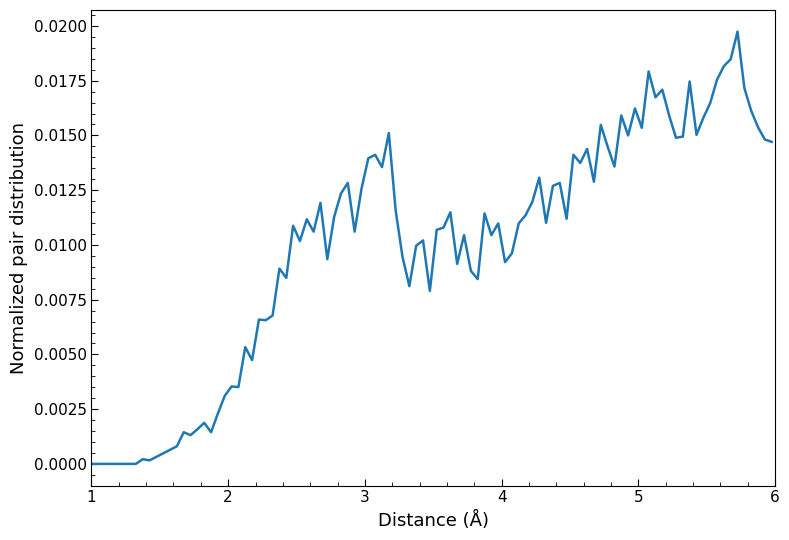

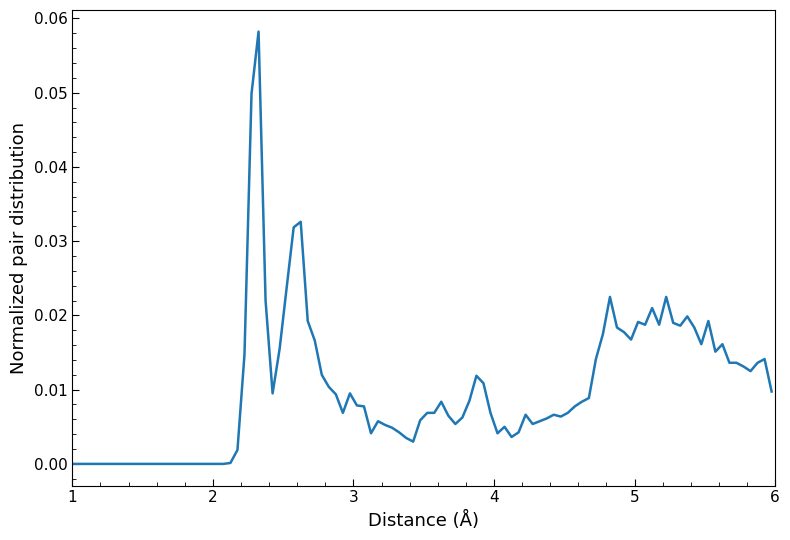

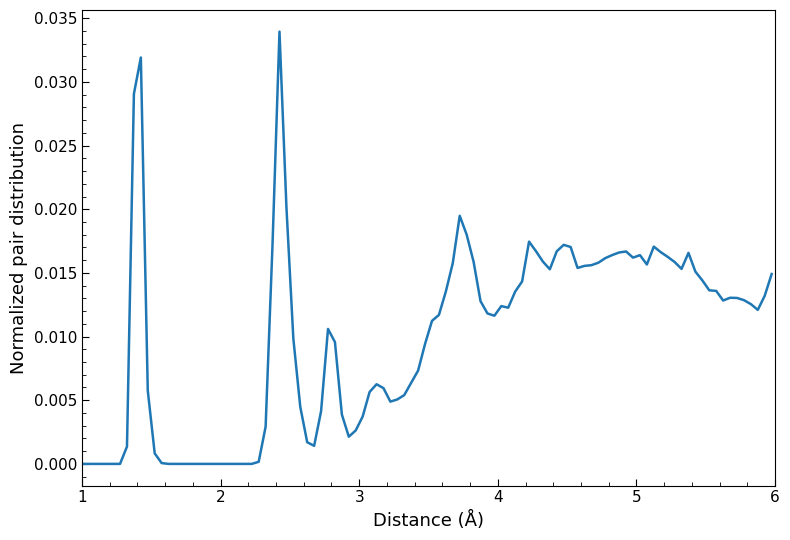

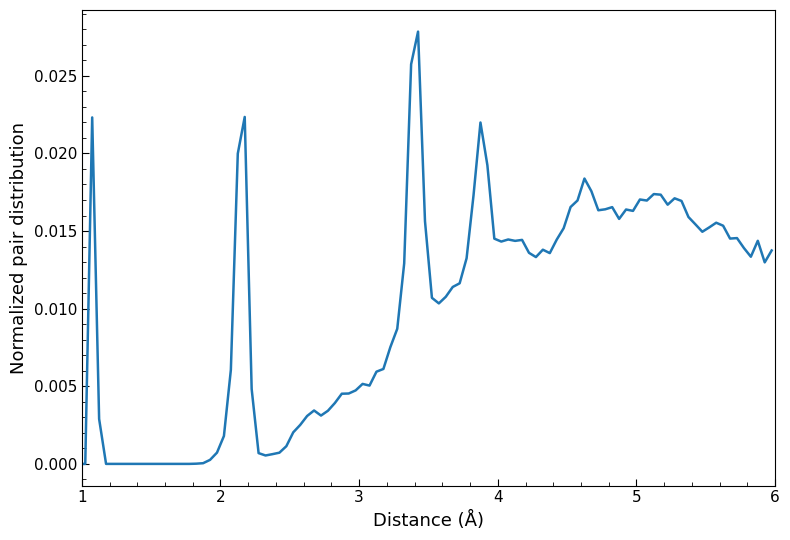


RDF ANALYSIS COMPLETE
Saved: MD_RDF_Data.csv
Four RDF figures generated:
  H-O
  N-O
  C-C
  C-H

CELL 6 COMPLETE


In [74]:
# ============================================================
# CELL 6 — RADIAL DISTRIBUTION FUNCTION (RDF) ANALYSIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# RDF settings
# ------------------------------------------------------------

r_max = 6.0       # maximum distance in Å
dr = 0.05         # bin width in Å

r_edges = np.arange(0.0, r_max + dr, dr)
r_centers = 0.5 * (r_edges[:-1] + r_edges[1:])

# ------------------------------------------------------------
# Atom indices by element
# ------------------------------------------------------------

symbols = np.array(
    md_frames[0].get_chemical_symbols()
)

H_indices = np.where(symbols == "H")[0]
C_indices = np.where(symbols == "C")[0]
N_indices = np.where(symbols == "N")[0]
O_indices = np.where(symbols == "O")[0]

print("=" * 65)
print("RDF ANALYSIS")
print("=" * 65)

print(f"Hydrogen atoms : {len(H_indices)}")
print(f"Carbon atoms   : {len(C_indices)}")
print(f"Nitrogen atoms : {len(N_indices)}")
print(f"Oxygen atoms   : {len(O_indices)}")

# ------------------------------------------------------------
# Function to calculate pair-distance histogram
# with periodic minimum-image convention
# ------------------------------------------------------------

def pair_distance_histogram(frames, indices_a, indices_b,
                            r_edges, same_species=False):

    histogram = np.zeros(len(r_edges) - 1)

    total_pairs = 0

    for atoms in frames:

        positions = atoms.get_positions()
        cell = atoms.get_cell().array

        # Fractional coordinates
        fractional = np.linalg.solve(
            cell.T,
            positions.T
        ).T

        # Pair combinations
        if same_species:
            pairs = [
                (i, j)
                for ii, i in enumerate(indices_a)
                for j in indices_a[ii + 1:]
            ]
        else:
            pairs = [
                (i, j)
                for i in indices_a
                for j in indices_b
            ]

        for i, j in pairs:

            df = fractional[j] - fractional[i]

            # Minimum-image convention
            df -= np.round(df)

            # Cartesian distance
            dr_cart = df @ cell

            distance = np.linalg.norm(dr_cart)

            if distance < r_edges[-1]:
                histogram += np.histogram(
                    [distance],
                    bins=r_edges
                )[0]

            total_pairs += 1

    return histogram, total_pairs


# ------------------------------------------------------------
# Calculate RDF-like normalized distributions
# ------------------------------------------------------------

pair_definitions = {
    "H-O": (H_indices, O_indices, False),
    "N-O": (N_indices, O_indices, False),
    "C-C": (C_indices, C_indices, True),
    "C-H": (C_indices, H_indices, False)
}

rdf_data = {}

for name, (idx_a, idx_b, same_species) in pair_definitions.items():

    hist, total_pairs = pair_distance_histogram(
        md_frames,
        idx_a,
        idx_b,
        r_edges,
        same_species=same_species
    )

    # Normalize to probability distribution
    if hist.sum() > 0:
        rdf = hist / hist.sum()
    else:
        rdf = hist

    rdf_data[name] = rdf

    print(
        f"{name:5s} | "
        f"pairs sampled: {total_pairs:7d} | "
        f"counts: {int(hist.sum()):7d}"
    )


# ------------------------------------------------------------
# Save RDF data
# ------------------------------------------------------------

rdf_table = np.column_stack([
    r_centers,
    rdf_data["H-O"],
    rdf_data["N-O"],
    rdf_data["C-C"],
    rdf_data["C-H"]
])

np.savetxt(
    os.path.join(output_dir, "MD_RDF_Data.csv"),
    rdf_table,
    delimiter=",",
    header="Distance_A,H-O,N-O,C-C,C-H",
    comments=""
)


# ------------------------------------------------------------
# Individual RDF plots
# ------------------------------------------------------------

for name, rdf in rdf_data.items():

    fig, ax = plt.subplots(figsize=(8, 5.5))

    ax.plot(
        r_centers,
        rdf,
        linewidth=1.8
    )

    ax.set_xlabel("Distance (Å)", fontsize=13)
    ax.set_ylabel("Normalized pair distribution", fontsize=13)

    ax.set_xlim(1.0, 6.0)

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=11,
        direction="in",
        length=5
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="in",
        length=3
    )

    ax.minorticks_on()

    fig.tight_layout()

    safe_name = name.replace("-", "_")

    fig.savefig(
        os.path.join(
            output_dir,
            f"Figure_RDF_{safe_name}.png"
        ),
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        os.path.join(
            output_dir,
            f"Figure_RDF_{safe_name}.pdf"
        ),
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


print("\n" + "=" * 65)
print("RDF ANALYSIS COMPLETE")
print("=" * 65)

print(
    "Saved: MD_RDF_Data.csv"
)

print("Four RDF figures generated:")
print("  H-O")
print("  N-O")
print("  C-C")
print("  C-H")

print("\nCELL 6 COMPLETE")

H-BOND GEOMETRY DURING 2-PS MD

N81-H33...O93
  H...A distance : 1.892 ± 0.316 Å
  D...A distance : 2.837 ± 0.261 Å
  D-H distance   : 1.043 ± 0.019 Å
  D-H...A angle  : 152.59 ± 14.36°
  H...A minimum  : 1.367 Å
  H...A maximum  : 2.777 Å

N80-H32...O92
  H...A distance : 1.885 ± 0.312 Å
  D...A distance : 2.835 ± 0.258 Å
  D-H distance   : 1.043 ± 0.016 Å
  D-H...A angle  : 153.01 ± 13.77°
  H...A minimum  : 1.367 Å
  H...A maximum  : 2.755 Å

N84-H0...O93
  H...A distance : 2.361 ± 0.552 Å
  D...A distance : 3.212 ± 0.360 Å
  D-H distance   : 1.025 ± 0.015 Å
  D-H...A angle  : 148.30 ± 25.05°
  H...A minimum  : 1.538 Å
  H...A maximum  : 3.865 Å

N85-H1...O92
  H...A distance : 2.377 ± 0.559 Å
  D...A distance : 3.213 ± 0.357 Å
  D-H distance   : 1.025 ± 0.017 Å
  D-H...A angle  : 147.04 ± 26.08°
  H...A minimum  : 1.529 Å
  H...A maximum  : 3.865 Å

H-BOND PERSISTENCE
N81-H33...O93     :  82.59%
N80-H32...O92     :  84.08%
N84-H0...O93      :  62.19%
N85-H1...O92      :  57.71%


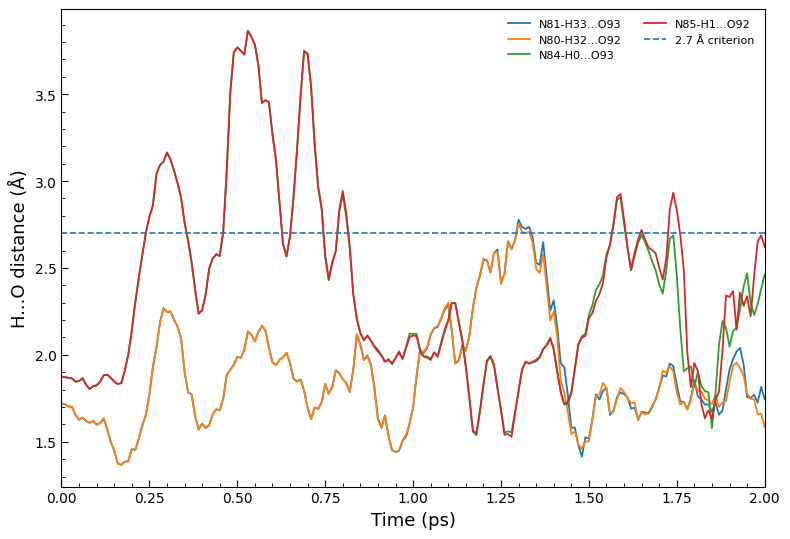

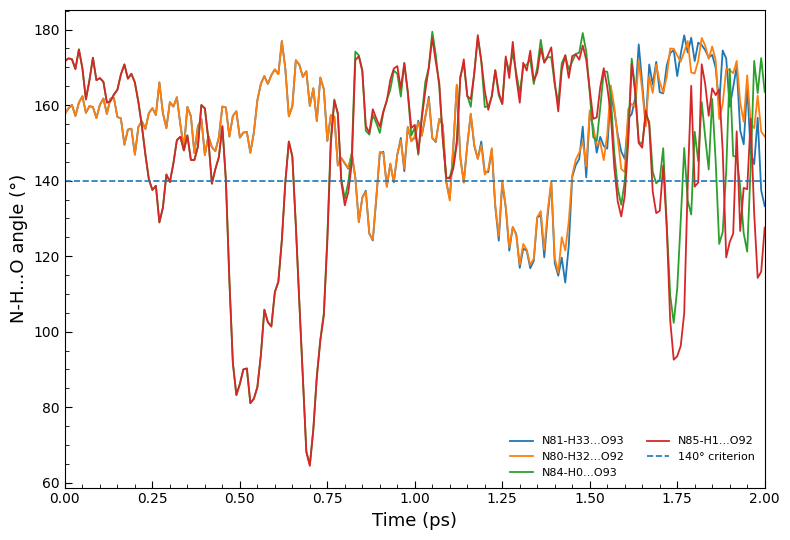


CELL 7 COMPLETE
Files saved:
  MD_Hbond_Geometry.csv
  Figure_Hbond_HO_Distance.png/.pdf
  Figure_Hbond_Angle.png/.pdf


In [75]:
# ============================================================
# CELL 7 — H-BOND GEOMETRY DISTRIBUTIONS DURING MD
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Experimentally identified H-bonds
# ------------------------------------------------------------

hbonds = {
    "N81-H33...O93": (81, 33, 93),
    "N80-H32...O92": (80, 32, 92),
    "N84-H0...O93":  (84, 0, 93),
    "N85-H1...O92":  (85, 1, 92)
}

# ------------------------------------------------------------
# Geometry function
# ------------------------------------------------------------

def angle_three_points(a, b, c):
    """
    Calculate angle A-B-C in degrees.
    """
    v1 = a - b
    v2 = c - b

    norm1 = np.linalg.norm(v1)
    norm2 = np.linalg.norm(v2)

    if norm1 == 0 or norm2 == 0:
        return np.nan

    cosine = np.dot(v1, v2) / (norm1 * norm2)

    cosine = np.clip(cosine, -1.0, 1.0)

    return np.degrees(
        np.arccos(cosine)
    )


def mic_vector(atoms, i, j):
    """
    Minimum-image vector from atom i to atom j.
    """
    cell = atoms.get_cell().array

    positions = atoms.get_positions()

    frac = np.linalg.solve(
        cell.T,
        positions.T
    ).T

    df = frac[j] - frac[i]

    df -= np.round(df)

    return df @ cell


# ------------------------------------------------------------
# Calculate geometry for every MD frame
# ------------------------------------------------------------

hb_data = {}

for name, (donor, hydrogen, acceptor) in hbonds.items():

    donor_h_distances = []
    h_acceptor_distances = []
    donor_acceptor_distances = []
    angles = []

    for atoms in md_frames:

        # D-H vector
        dh_vector = mic_vector(
            atoms,
            donor,
            hydrogen
        )

        # H-A vector
        ha_vector = mic_vector(
            atoms,
            hydrogen,
            acceptor
        )

        # D-A vector
        da_vector = mic_vector(
            atoms,
            donor,
            acceptor
        )

        d_h = np.linalg.norm(dh_vector)
        h_a = np.linalg.norm(ha_vector)
        d_a = np.linalg.norm(da_vector)

        # For angle D-H-A
        donor_position = np.zeros(3)
        hydrogen_position = dh_vector
        acceptor_position = dh_vector + ha_vector

        angle = angle_three_points(
            donor_position,
            hydrogen_position,
            acceptor_position
        )

        donor_h_distances.append(d_h)
        h_acceptor_distances.append(h_a)
        donor_acceptor_distances.append(d_a)
        angles.append(angle)

    hb_data[name] = {
        "D-H": np.array(donor_h_distances),
        "H-A": np.array(h_acceptor_distances),
        "D-A": np.array(donor_acceptor_distances),
        "Angle": np.array(angles)
    }


# ------------------------------------------------------------
# Print statistics
# ------------------------------------------------------------

print("=" * 75)
print("H-BOND GEOMETRY DURING 2-PS MD")
print("=" * 75)

for name, data in hb_data.items():

    print("\n" + name)

    print(
        f"  H...A distance : "
        f"{np.mean(data['H-A']):.3f} ± "
        f"{np.std(data['H-A']):.3f} Å"
    )

    print(
        f"  D...A distance : "
        f"{np.mean(data['D-A']):.3f} ± "
        f"{np.std(data['D-A']):.3f} Å"
    )

    print(
        f"  D-H distance   : "
        f"{np.mean(data['D-H']):.3f} ± "
        f"{np.std(data['D-H']):.3f} Å"
    )

    print(
        f"  D-H...A angle  : "
        f"{np.mean(data['Angle']):.2f} ± "
        f"{np.std(data['Angle']):.2f}°"
    )

    print(
        f"  H...A minimum  : "
        f"{np.min(data['H-A']):.3f} Å"
    )

    print(
        f"  H...A maximum  : "
        f"{np.max(data['H-A']):.3f} Å"
    )


# ------------------------------------------------------------
# H-bond persistence using the same criteria used previously
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("H-BOND PERSISTENCE")
print("=" * 75)

persistence_results = []

for name, data in hb_data.items():

    valid = (
        (data["H-A"] <= 2.7) &
        (data["D-A"] <= 3.5) &
        (data["Angle"] >= 140.0)
    )

    persistence = 100.0 * np.mean(valid)

    persistence_results.append([
        name,
        persistence
    ])

    print(
        f"{name:18s}: "
        f"{persistence:6.2f}%"
    )


# ------------------------------------------------------------
# Save complete numerical dataset
# ------------------------------------------------------------

hb_dataframe = pd.DataFrame({
    "Time_ps": time_ps
})

for name, data in hb_data.items():

    clean_name = name.replace("-", "_").replace(".", "_")

    hb_dataframe[f"{clean_name}_H_A_A"] = data["H-A"]
    hb_dataframe[f"{clean_name}_D_A_A"] = data["D-A"]
    hb_dataframe[f"{clean_name}_Angle_deg"] = data["Angle"]

hb_dataframe.to_csv(
    os.path.join(
        output_dir,
        "MD_Hbond_Geometry.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# Plot 1 — H...O distance distributions
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

for name, data in hb_data.items():

    ax.plot(
        time_ps,
        data["H-A"],
        linewidth=1.3,
        label=name
    )

ax.axhline(
    2.7,
    linestyle="--",
    linewidth=1.2,
    label="2.7 Å criterion"
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("H...O distance (Å)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=8,
    ncol=2
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_HO_Distance.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_HO_Distance.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# Plot 2 — H-bond angle
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

for name, data in hb_data.items():

    ax.plot(
        time_ps,
        data["Angle"],
        linewidth=1.3,
        label=name
    )

ax.axhline(
    140,
    linestyle="--",
    linewidth=1.2,
    label="140° criterion"
)

ax.set_xlabel("Time (ps)", fontsize=13)
ax.set_ylabel("N-H...O angle (°)", fontsize=13)

ax.set_xlim(0, 2.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=8,
    ncol=2
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_Angle.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_Angle.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


print("\n" + "=" * 75)
print("CELL 7 COMPLETE")
print("=" * 75)

print("Files saved:")
print("  MD_Hbond_Geometry.csv")
print("  Figure_Hbond_HO_Distance.png/.pdf")
print("  Figure_Hbond_Angle.png/.pdf")

H-BOND OCCUPANCY ANALYSIS

N81-H33...O93
  H...O ≤ 2.7 Å       : 98.01%
  N...O ≤ 3.5 Å       : 100.00%
  N-H...O ≥ 140°      : 82.59%
  ALL criteria        : 82.59%

N80-H32...O92
  H...O ≤ 2.7 Å       : 98.01%
  N...O ≤ 3.5 Å       : 100.00%
  N-H...O ≥ 140°      : 84.08%
  ALL criteria        : 84.08%

N84-H0...O93
  H...O ≤ 2.7 Å       : 77.61%
  N...O ≤ 3.5 Å       : 73.13%
  N-H...O ≥ 140°      : 74.63%
  ALL criteria        : 62.19%

N85-H1...O92
  H...O ≤ 2.7 Å       : 75.62%
  N...O ≤ 3.5 Å       : 73.13%
  N-H...O ≥ 140°      : 69.65%
  ALL criteria        : 57.71%

OCCUPANCY TABLE
       H_bond  H_O_occupancy_percent  N_O_occupancy_percent  Angle_occupancy_percent  Overall_persistence_percent
N81-H33...O93                  98.01                 100.00                    82.59                        82.59
N80-H32...O92                  98.01                 100.00                    84.08                        84.08
 N84-H0...O93                  77.61                  73.13

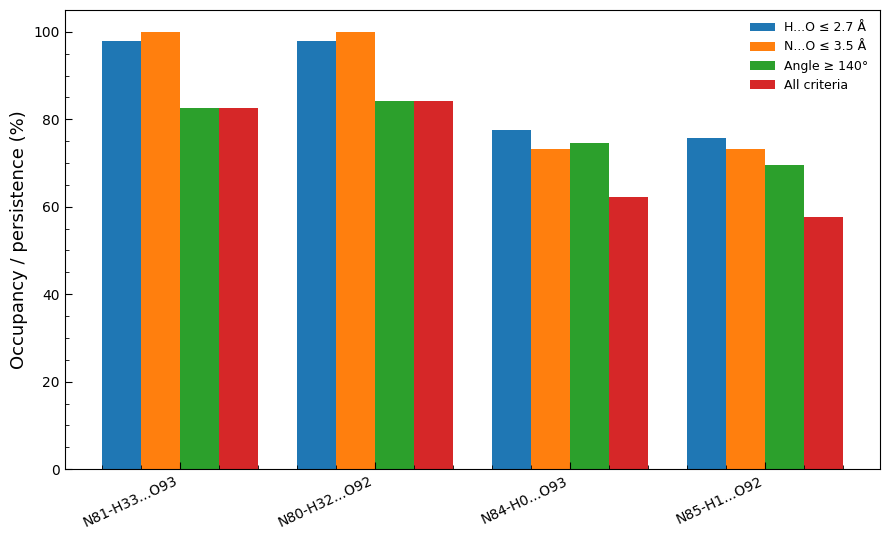


CELL 8 COMPLETE
Saved:
  Hbond_Occupancy_Analysis.csv
  Figure_Hbond_Occupancy.png
  Figure_Hbond_Occupancy.pdf


In [76]:
# ============================================================
# CELL 8 — H-BOND OCCUPANCY AND DISTRIBUTION ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# H-bond criteria
# ------------------------------------------------------------

H_A_LIMIT = 2.7
D_A_LIMIT = 3.5
ANGLE_LIMIT = 140.0

occupancy_rows = []

print("=" * 75)
print("H-BOND OCCUPANCY ANALYSIS")
print("=" * 75)

for name, data in hb_data.items():

    h_a = data["H-A"]
    d_a = data["D-A"]
    angle = data["Angle"]

    h_a_ok = h_a <= H_A_LIMIT
    d_a_ok = d_a <= D_A_LIMIT
    angle_ok = angle >= ANGLE_LIMIT

    all_ok = h_a_ok & d_a_ok & angle_ok

    h_a_occ = 100 * np.mean(h_a_ok)
    d_a_occ = 100 * np.mean(d_a_ok)
    angle_occ = 100 * np.mean(angle_ok)
    overall_occ = 100 * np.mean(all_ok)

    occupancy_rows.append([
        name,
        h_a_occ,
        d_a_occ,
        angle_occ,
        overall_occ
    ])

    print(f"\n{name}")
    print(f"  H...O ≤ 2.7 Å       : {h_a_occ:.2f}%")
    print(f"  N...O ≤ 3.5 Å       : {d_a_occ:.2f}%")
    print(f"  N-H...O ≥ 140°      : {angle_occ:.2f}%")
    print(f"  ALL criteria        : {overall_occ:.2f}%")


# ------------------------------------------------------------
# Create occupancy table
# ------------------------------------------------------------

occupancy_df = pd.DataFrame(
    occupancy_rows,
    columns=[
        "H_bond",
        "H_O_occupancy_percent",
        "N_O_occupancy_percent",
        "Angle_occupancy_percent",
        "Overall_persistence_percent"
    ]
)

occupancy_df.to_csv(
    os.path.join(
        output_dir,
        "Hbond_Occupancy_Analysis.csv"
    ),
    index=False
)

print("\n" + "=" * 75)
print("OCCUPANCY TABLE")
print("=" * 75)

print(
    occupancy_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ------------------------------------------------------------
# Plot occupancy
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5.5))

x = np.arange(len(occupancy_df))
width = 0.20

ax.bar(
    x - 1.5 * width,
    occupancy_df["H_O_occupancy_percent"],
    width,
    label="H...O ≤ 2.7 Å"
)

ax.bar(
    x - 0.5 * width,
    occupancy_df["N_O_occupancy_percent"],
    width,
    label="N...O ≤ 3.5 Å"
)

ax.bar(
    x + 0.5 * width,
    occupancy_df["Angle_occupancy_percent"],
    width,
    label="Angle ≥ 140°"
)

ax.bar(
    x + 1.5 * width,
    occupancy_df["Overall_persistence_percent"],
    width,
    label="All criteria"
)

ax.set_xticks(x)
ax.set_xticklabels(
    occupancy_df["H_bond"],
    rotation=25,
    ha="right"
)

ax.set_ylabel("Occupancy / persistence (%)", fontsize=13)
ax.set_ylim(0, 105)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=9
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_Occupancy.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Hbond_Occupancy.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


print("\n" + "=" * 75)
print("CELL 8 COMPLETE")
print("=" * 75)

print("Saved:")
print("  Hbond_Occupancy_Analysis.csv")
print("  Figure_Hbond_Occupancy.png")
print("  Figure_Hbond_Occupancy.pdf")

In [77]:
# ============================================================
# CELL 9 — ATOM-BY-ATOM MD DISPLACEMENT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Reference structure
# ------------------------------------------------------------

reference = md_frames[0]

reference_positions = reference.get_positions()

symbols = np.array(
    reference.get_chemical_symbols()
)

n_atoms = len(reference)

# ------------------------------------------------------------
# Store displacement for every atom and every frame
# ------------------------------------------------------------

all_displacements = np.zeros(
    (len(md_frames), n_atoms)
)

# ------------------------------------------------------------
# Calculate periodic minimum-image displacements
# ------------------------------------------------------------

for frame_index, atoms in enumerate(md_frames):

    cell = atoms.get_cell().array
    current_positions = atoms.get_positions()

    # Fractional coordinates
    frac_reference = np.linalg.solve(
        cell.T,
        reference_positions.T
    ).T

    frac_current = np.linalg.solve(
        cell.T,
        current_positions.T
    ).T

    # Fractional displacement
    frac_difference = (
        frac_current - frac_reference
    )

    # Minimum-image convention
    frac_difference -= np.round(
        frac_difference
    )

    # Cartesian displacement
    cart_difference = (
        frac_difference @ cell
    )

    # Magnitude
    distances = np.linalg.norm(
        cart_difference,
        axis=1
    )

    all_displacements[frame_index, :] = distances


# ------------------------------------------------------------
# Per-atom statistics
# ------------------------------------------------------------

mean_disp = np.mean(
    all_displacements,
    axis=0
)

max_disp = np.max(
    all_displacements,
    axis=0
)

final_disp = all_displacements[-1, :]

rms_disp = np.sqrt(
    np.mean(
        all_displacements**2,
        axis=0
    )
)


# ------------------------------------------------------------
# Create atom table
# ------------------------------------------------------------

atom_table = pd.DataFrame({
    "Atom_index": np.arange(n_atoms),
    "Element": symbols,
    "Mean_displacement_A": mean_disp,
    "RMS_displacement_A": rms_disp,
    "Maximum_displacement_A": max_disp,
    "Final_displacement_A": final_disp
})


# ------------------------------------------------------------
# Sort by maximum displacement
# ------------------------------------------------------------

atom_table_sorted = atom_table.sort_values(
    "Maximum_displacement_A",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# Print top 15 atoms
# ------------------------------------------------------------

print("=" * 75)
print("TOP 15 MOST MOBILE ATOMS")
print("=" * 75)

print(
    atom_table_sorted.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# Element-wise statistics
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ELEMENT-WISE DISPLACEMENT STATISTICS")
print("=" * 75)

element_stats = []

for element in sorted(
    np.unique(symbols)
):

    mask = symbols == element

    values = max_disp[mask]

    element_stats.append([
        element,
        np.sum(mask),
        np.mean(values),
        np.sqrt(np.mean(values**2)),
        np.max(values)
    ])

element_stats_df = pd.DataFrame(
    element_stats,
    columns=[
        "Element",
        "Number_of_atoms",
        "Mean_max_displacement_A",
        "RMS_max_displacement_A",
        "Largest_displacement_A"
    ]
)

print(
    element_stats_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# Displacement categories
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DISPLACEMENT CATEGORIES")
print("=" * 75)

categories = {
    "< 0.10 Å": np.sum(max_disp < 0.10),
    "0.10–0.20 Å": np.sum(
        (max_disp >= 0.10) &
        (max_disp < 0.20)
    ),
    "0.20–0.30 Å": np.sum(
        (max_disp >= 0.20) &
        (max_disp < 0.30)
    ),
    "≥ 0.30 Å": np.sum(
        max_disp >= 0.30
    )
}

for category, count in categories.items():

    percentage = 100 * count / n_atoms

    print(
        f"{category:15s}: "
        f"{count:3d} atoms "
        f"({percentage:5.2f}%)"
    )


# ------------------------------------------------------------
# Save files
# ------------------------------------------------------------

atom_table.to_csv(
    os.path.join(
        output_dir,
        "MD_Atom_Displacements.csv"
    ),
    index=False
)

atom_table_sorted.to_csv(
    os.path.join(
        output_dir,
        "MD_Atom_Displacements_Sorted.csv"
    ),
    index=False
)

element_stats_df.to_csv(
    os.path.join(
        output_dir,
        "MD_Element_Displacement_Statistics.csv"
    ),
    index=False
)


print("\n" + "=" * 75)
print("CELL 9 COMPLETE")
print("=" * 75)

print("Saved:")
print("  MD_Atom_Displacements.csv")
print("  MD_Atom_Displacements_Sorted.csv")
print("  MD_Element_Displacement_Statistics.csv")

TOP 15 MOST MOBILE ATOMS
 Atom_index Element  Mean_displacement_A  RMS_displacement_A  Maximum_displacement_A  Final_displacement_A
          0       H               0.6900              0.8629                  2.5393                0.4001
          1       H               0.7051              0.8758                  2.5391                0.7479
          2       H               0.6569              0.8061                  2.5087                0.4001
          3       H               0.6553              0.8032                  2.5083                0.3470
         84       N               0.5384              0.6374                  1.7664                0.3741
         85       N               0.5332              0.6348                  1.7664                0.3512
         14       H               0.6880              0.7416                  1.7013                0.8290
         15       H               0.7088              0.7646                  1.6736                0.9670
          7 

MAXIMUM ATOMIC DISPLACEMENT DISTRIBUTION

All atoms:
Mean   : 1.1240 Å
Median : 1.0905 Å
Maximum: 2.5393 Å

Heavy atoms:
Mean   : 0.9337 Å
Median : 0.8799 Å
Maximum: 1.7664 Å

Hydrogen atoms:
Mean   : 1.4599 Å
Median : 1.3088 Å
Maximum: 2.5393 Å


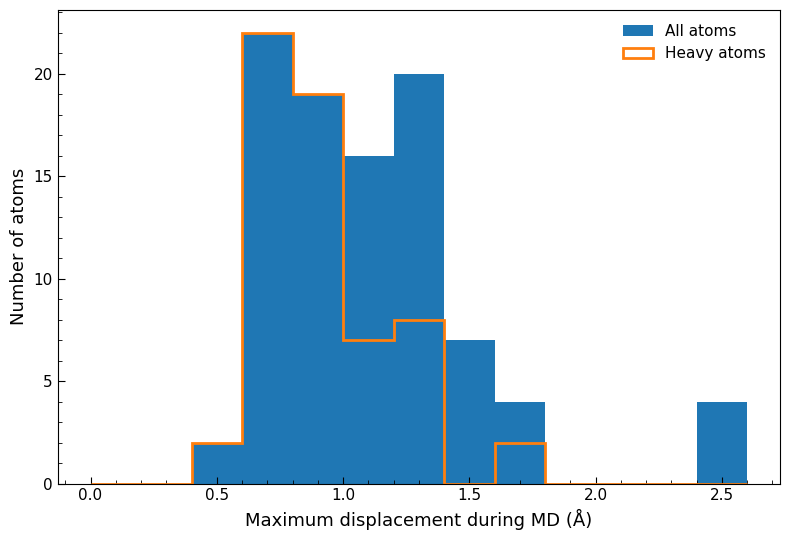

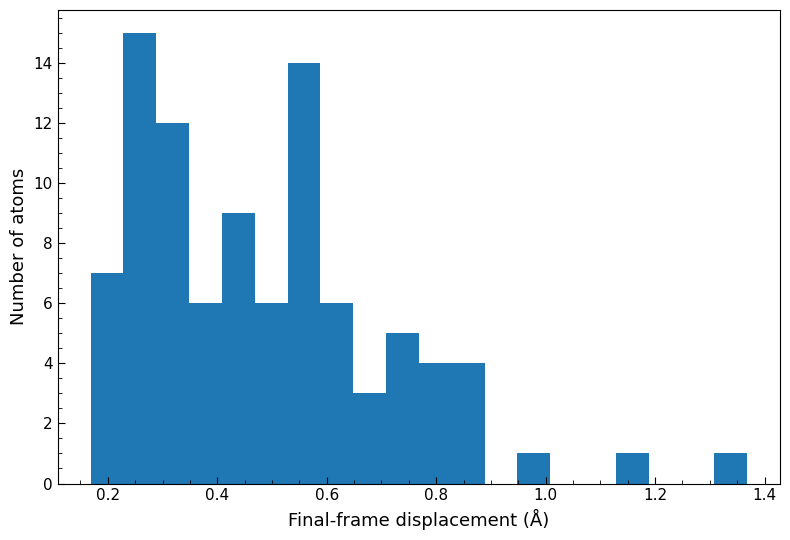


CELL 10 COMPLETE
Figures saved:
  Figure_MD_Displacement_Distribution.png/.pdf
  Figure_MD_Final_Displacement.png/.pdf
  MD_Displacement_Summary.txt


In [78]:
# ============================================================
# CELL 10 — ATOMIC DISPLACEMENT DISTRIBUTION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Maximum displacement for every atom
# ------------------------------------------------------------

max_all = max_disp
max_heavy = max_disp[heavy_mask]
max_h = max_disp[~heavy_mask]

print("=" * 70)
print("MAXIMUM ATOMIC DISPLACEMENT DISTRIBUTION")
print("=" * 70)

print("\nAll atoms:")
print(f"Mean   : {np.mean(max_all):.4f} Å")
print(f"Median : {np.median(max_all):.4f} Å")
print(f"Maximum: {np.max(max_all):.4f} Å")

print("\nHeavy atoms:")
print(f"Mean   : {np.mean(max_heavy):.4f} Å")
print(f"Median : {np.median(max_heavy):.4f} Å")
print(f"Maximum: {np.max(max_heavy):.4f} Å")

print("\nHydrogen atoms:")
print(f"Mean   : {np.mean(max_h):.4f} Å")
print(f"Median : {np.median(max_h):.4f} Å")
print(f"Maximum: {np.max(max_h):.4f} Å")


# ------------------------------------------------------------
# Histogram
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

bins = np.arange(
    0.0,
    np.ceil(np.max(max_all) / 0.2) * 0.2 + 0.2,
    0.2
)

ax.hist(
    max_all,
    bins=bins,
    linewidth=1.0,
    label="All atoms"
)

ax.hist(
    max_heavy,
    bins=bins,
    histtype="step",
    linewidth=2.0,
    label="Heavy atoms"
)

ax.set_xlabel(
    "Maximum displacement during MD (Å)",
    fontsize=13
)

ax.set_ylabel(
    "Number of atoms",
    fontsize=13
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

ax.legend(
    frameon=False,
    fontsize=11
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_MD_Displacement_Distribution.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_MD_Displacement_Distribution.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# Final-frame displacement distribution
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.hist(
    final_disp,
    bins=20,
    linewidth=1.0
)

ax.set_xlabel(
    "Final-frame displacement (Å)",
    fontsize=13
)

ax.set_ylabel(
    "Number of atoms",
    fontsize=13
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_MD_Final_Displacement.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_MD_Final_Displacement.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------

summary = {
    "All_atom_mean_max_displacement_A": np.mean(max_all),
    "All_atom_median_max_displacement_A": np.median(max_all),
    "All_atom_largest_displacement_A": np.max(max_all),
    "Heavy_atom_mean_max_displacement_A": np.mean(max_heavy),
    "Heavy_atom_median_max_displacement_A": np.median(max_heavy),
    "Heavy_atom_largest_displacement_A": np.max(max_heavy),
    "Hydrogen_mean_max_displacement_A": np.mean(max_h),
    "Hydrogen_median_max_displacement_A": np.median(max_h),
    "Hydrogen_largest_displacement_A": np.max(max_h),
}

np.savetxt(
    os.path.join(
        output_dir,
        "MD_Displacement_Summary.txt"
    ),
    [0],
    fmt="%d",
    header="\n".join(
        f"{key}: {value:.6f}"
        for key, value in summary.items()
    ),
    comments=""
)

print("\n" + "=" * 70)
print("CELL 10 COMPLETE")
print("=" * 70)

print("Figures saved:")
print("  Figure_MD_Displacement_Distribution.png/.pdf")
print("  Figure_MD_Final_Displacement.png/.pdf")
print("  MD_Displacement_Summary.txt")

In [79]:
# ============================================================
# CELL 11 — INTERMOLECULAR CONTACT PERSISTENCE DURING MD
# ============================================================

import numpy as np
import pandas as pd
import os
from collections import defaultdict

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Molecular components identified from the experimental CIF
# ------------------------------------------------------------

component_A = set(
    [0,2,4,6,8,10,12,14,16,18,20,22,
     48,50,52,54,56,58,60,62,64,66,68,70,72,74,76,82,84,92]
)

component_B = set(
    [1,3,5,7,9,11,13,15,17,19,21,23,
     49,51,53,55,57,59,61,63,65,67,69,71,73,75,77,83,85,93]
)

component_C = set(
    [24,26,28,30,32,34,36,38,40,42,44,46,
     78,80,86,88,90]
)

component_D = set(
    [25,27,29,31,33,35,37,39,41,43,45,47,
     79,81,87,89,91]
)

# ------------------------------------------------------------
# Two molecular components of the cocrystal
# ------------------------------------------------------------

molecule_A = sorted(
    component_A | component_B
)

molecule_B = sorted(
    component_C | component_D
)

print("=" * 75)
print("INTERMOLECULAR CONTACT PERSISTENCE")
print("=" * 75)

print(
    f"Molecular component A: {len(molecule_A)} atoms"
)

print(
    f"Molecular component B: {len(molecule_B)} atoms"
)

# ------------------------------------------------------------
# Atom symbols
# ------------------------------------------------------------

symbols = np.array(
    md_frames[0].get_chemical_symbols()
)

# ------------------------------------------------------------
# Define contact cutoff
#
# We use a broad 3.6 Å cutoff for intermolecular
# non-bonded contacts.
#
# This is NOT a Hirshfeld fingerprint.
# ------------------------------------------------------------

CONTACT_CUTOFF = 3.6

# ------------------------------------------------------------
# Calculate experimental/reference intermolecular contacts
# from the first MD frame
# ------------------------------------------------------------

reference = md_frames[0]

cell = reference.get_cell().array
positions = reference.get_positions()

contacts = []

for i in molecule_A:

    for j in molecule_B:

        # Fractional displacement
        fi = np.linalg.solve(
            cell.T,
            positions[i]
        )

        fj = np.linalg.solve(
            cell.T,
            positions[j]
        )

        df = fj - fi

        # Minimum image
        df -= np.round(df)

        # Cartesian displacement
        vector = df @ cell

        distance = np.linalg.norm(vector)

        if distance <= CONTACT_CUTOFF:

            pair = "".join(
                sorted(
                    [symbols[i], symbols[j]]
                )
            )

            contacts.append({
                "Atom_i": i,
                "Atom_j": j,
                "Element_i": symbols[i],
                "Element_j": symbols[j],
                "Contact_type": pair,
                "Reference_distance_A": distance
            })

contacts_df = pd.DataFrame(contacts)

print(
    f"\nReference intermolecular contacts: "
    f"{len(contacts_df)}"
)

# ------------------------------------------------------------
# Track every reference contact during MD
# ------------------------------------------------------------

results = []

for _, contact in contacts_df.iterrows():

    i = int(contact["Atom_i"])
    j = int(contact["Atom_j"])

    distances = []

    for atoms in md_frames:

        cell = atoms.get_cell().array
        positions = atoms.get_positions()

        fi = np.linalg.solve(
            cell.T,
            positions[i]
        )

        fj = np.linalg.solve(
            cell.T,
            positions[j]
        )

        df = fj - fi

        df -= np.round(df)

        vector = df @ cell

        distance = np.linalg.norm(vector)

        distances.append(distance)

    distances = np.array(distances)

    persistence = (
        100 *
        np.mean(
            distances <= CONTACT_CUTOFF
        )
    )

    results.append({
        "Atom_i": i,
        "Atom_j": j,
        "Element_i": symbols[i],
        "Element_j": symbols[j],
        "Contact_type": contact["Contact_type"],
        "Reference_distance_A":
            contact["Reference_distance_A"],
        "Mean_distance_A":
            np.mean(distances),
        "Std_distance_A":
            np.std(distances),
        "Minimum_distance_A":
            np.min(distances),
        "Maximum_distance_A":
            np.max(distances),
        "Persistence_percent":
            persistence
    })

contact_persistence_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Sort by persistence
# ------------------------------------------------------------

contact_persistence_df = (
    contact_persistence_df
    .sort_values(
        ["Persistence_percent",
         "Reference_distance_A"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Print strongest persistent contacts
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MOST PERSISTENT INTERMOLECULAR CONTACTS")
print("=" * 75)

print(
    contact_persistence_df.head(25).to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# Contact-type summary
# ------------------------------------------------------------

summary_rows = []

for contact_type, group in (
    contact_persistence_df
    .groupby("Contact_type")
):

    summary_rows.append({
        "Contact_type": contact_type,
        "Number_of_contacts":
            len(group),
        "Mean_persistence_percent":
            group["Persistence_percent"].mean(),
        "Minimum_persistence_percent":
            group["Persistence_percent"].min(),
        "Maximum_persistence_percent":
            group["Persistence_percent"].max(),
        "Mean_reference_distance_A":
            group["Reference_distance_A"].mean()
    })

contact_summary_df = pd.DataFrame(
    summary_rows
).sort_values(
    "Mean_persistence_percent",
    ascending=False
)

print("\n" + "=" * 75)
print("CONTACT-TYPE PERSISTENCE")
print("=" * 75)

print(
    contact_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# Overall persistence
# ------------------------------------------------------------

overall_persistence = (
    contact_persistence_df[
        "Persistence_percent"
    ].mean()
)

fully_persistent = np.sum(
    contact_persistence_df[
        "Persistence_percent"
    ] == 100
)

print("\n" + "=" * 75)
print("OVERALL CONTACT PERSISTENCE")
print("=" * 75)

print(
    f"Total reference contacts : "
    f"{len(contact_persistence_df)}"
)

print(
    f"Mean contact persistence : "
    f"{overall_persistence:.2f}%"
)

print(
    f"Contacts persistent 100% : "
    f"{fully_persistent}"
)

print(
    f"Percentage fully persistent: "
    f"{100 * fully_persistent / len(contact_persistence_df):.2f}%"
)

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

contact_persistence_df.to_csv(
    os.path.join(
        output_dir,
        "MD_Intermolecular_Contact_Persistence.csv"
    ),
    index=False
)

contact_summary_df.to_csv(
    os.path.join(
        output_dir,
        "MD_Contact_Type_Persistence.csv"
    ),
    index=False
)

print("\n" + "=" * 75)
print("CELL 11 COMPLETE")
print("=" * 75)

print("Saved:")
print("  MD_Intermolecular_Contact_Persistence.csv")
print("  MD_Contact_Type_Persistence.csv")

INTERMOLECULAR CONTACT PERSISTENCE
Molecular component A: 60 atoms
Molecular component B: 34 atoms

Reference intermolecular contacts: 206

MOST PERSISTENT INTERMOLECULAR CONTACTS
 Atom_i  Atom_j Element_i Element_j Contact_type  Reference_distance_A  Mean_distance_A  Std_distance_A  Minimum_distance_A  Maximum_distance_A  Persistence_percent
     92      32         O         H           HO                 1.722            1.885           0.312               1.367               2.755              100.000
     93      33         O         H           HO                 1.722            1.892           0.316               1.367               2.777              100.000
     10      29         H         H           HH                 2.100            2.266           0.240               1.801               2.995              100.000
     11      28         H         H           HH                 2.100            2.282           0.240               1.801               3.035              100

CHEMICALLY RELEVANT CONTACT PERSISTENCE
                          Chemical_category  Number_of_contacts  Mean_persistence_percent  Median_persistence_percent  Minimum_persistence_percent  Maximum_persistence_percent  Mean_reference_distance_A
                              C...C contact                  26                     53.81                       56.97                        27.36                        83.08                       3.52
                              C...H contact                  66                     68.37                       70.65                        25.37                       100.00                       3.27
                              C...O contact                  16                     56.34                       59.20                        21.39                        75.62                       3.41
       H...O hydrogen-bond/contact geometry                  28                     88.22                       93.28                        45.27  

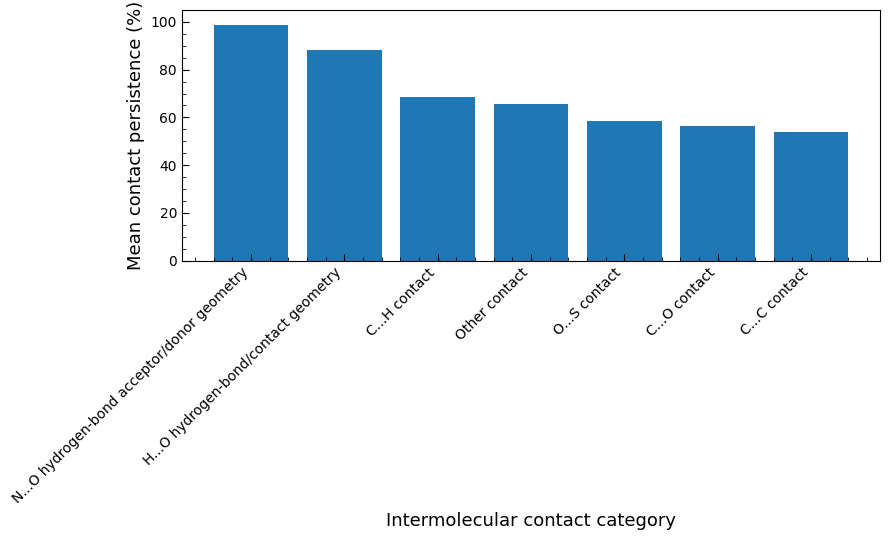


CELL 12 COMPLETE
Saved:
  Chemical_Contact_Persistence_Summary.csv
  Hbond_Related_Contact_Persistence.csv
  Figure_Chemical_Contact_Persistence.png
  Figure_Chemical_Contact_Persistence.pdf


In [80]:
# ============================================================
# CELL 12 — CHEMICALLY RELEVANT CONTACT PERSISTENCE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Load contact-persistence data from Cell 11
# ------------------------------------------------------------

contact_df = pd.read_csv(
    os.path.join(
        output_dir,
        "MD_Intermolecular_Contact_Persistence.csv"
    )
)

# ------------------------------------------------------------
# Define chemically relevant categories
# ------------------------------------------------------------

def classify_contact(row):

    pair = {
        row["Element_i"],
        row["Element_j"]
    }

    # Hydrogen-bond related
    if pair == {"N", "O"}:
        return "N...O hydrogen-bond acceptor/donor geometry"

    elif pair == {"H", "O"}:
        return "H...O hydrogen-bond/contact geometry"

    # Other potentially relevant intermolecular contacts
    elif pair == {"C", "H"}:
        return "C...H contact"

    elif pair == {"C", "C"}:
        return "C...C contact"

    elif pair == {"C", "O"}:
        return "C...O contact"

    elif pair == {"O", "S"}:
        return "O...S contact"

    else:
        return "Other contact"


contact_df["Chemical_category"] = contact_df.apply(
    classify_contact,
    axis=1
)

# ------------------------------------------------------------
# Summary statistics
# ------------------------------------------------------------

summary = (
    contact_df
    .groupby("Chemical_category")
    .agg(
        Number_of_contacts=(
            "Persistence_percent",
            "count"
        ),
        Mean_persistence_percent=(
            "Persistence_percent",
            "mean"
        ),
        Median_persistence_percent=(
            "Persistence_percent",
            "median"
        ),
        Minimum_persistence_percent=(
            "Persistence_percent",
            "min"
        ),
        Maximum_persistence_percent=(
            "Persistence_percent",
            "max"
        ),
        Mean_reference_distance_A=(
            "Reference_distance_A",
            "mean"
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# Print summary
# ------------------------------------------------------------

print("=" * 80)
print("CHEMICALLY RELEVANT CONTACT PERSISTENCE")
print("=" * 80)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

# ------------------------------------------------------------
# Focus specifically on hydrogen-bond-related contacts
# ------------------------------------------------------------

hb_related = contact_df[
    contact_df["Chemical_category"].isin([
        "N...O hydrogen-bond acceptor/donor geometry",
        "H...O hydrogen-bond/contact geometry"
    ])
].copy()

print("\n" + "=" * 80)
print("HYDROGEN-BOND-RELATED CONTACTS")
print("=" * 80)

print(
    f"Number of H-bond-related contacts: "
    f"{len(hb_related)}"
)

print(
    f"Mean persistence: "
    f"{hb_related['Persistence_percent'].mean():.2f}%"
)

print(
    f"Median persistence: "
    f"{hb_related['Persistence_percent'].median():.2f}%"
)

print(
    f"Minimum persistence: "
    f"{hb_related['Persistence_percent'].min():.2f}%"
)

print(
    f"Maximum persistence: "
    f"{hb_related['Persistence_percent'].max():.2f}%"
)

# ------------------------------------------------------------
# Strong H-bond-like subset
#
# Criteria:
# H...O <= 2.7 Å
# N...O <= 3.5 Å
#
# Note:
# This is a geometric screen, not an electronic-structure
# definition of hydrogen bonding.
# ------------------------------------------------------------

strong_ho = contact_df[
    (
        (contact_df["Element_i"] == "H") &
        (contact_df["Element_j"] == "O")
    ) |
    (
        (contact_df["Element_i"] == "O") &
        (contact_df["Element_j"] == "H")
    )
].copy()

strong_ho = strong_ho[
    strong_ho["Reference_distance_A"] <= 2.7
]

strong_no = contact_df[
    (
        (contact_df["Element_i"] == "N") &
        (contact_df["Element_j"] == "O")
    ) |
    (
        (contact_df["Element_i"] == "O") &
        (contact_df["Element_j"] == "N")
    )
].copy()

strong_no = strong_no[
    strong_no["Reference_distance_A"] <= 3.5
]

print("\n" + "=" * 80)
print("GEOMETRICALLY STRONG H-BOND-RELATED CONTACTS")
print("=" * 80)

print(
    f"H...O contacts ≤ 2.7 Å: "
    f"{len(strong_ho)}"
)

if len(strong_ho) > 0:
    print(
        f"Mean persistence: "
        f"{strong_ho['Persistence_percent'].mean():.2f}%"
    )

print(
    f"N...O contacts ≤ 3.5 Å: "
    f"{len(strong_no)}"
)

if len(strong_no) > 0:
    print(
        f"Mean persistence: "
        f"{strong_no['Persistence_percent'].mean():.2f}%"
    )

# ------------------------------------------------------------
# Plot chemically relevant persistence
# ------------------------------------------------------------

plot_df = summary.sort_values(
    "Mean_persistence_percent",
    ascending=False
)

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

ax.bar(
    plot_df["Chemical_category"],
    plot_df["Mean_persistence_percent"]
)

ax.set_ylabel(
    "Mean contact persistence (%)",
    fontsize=13
)

ax.set_xlabel(
    "Intermolecular contact category",
    fontsize=13
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10,
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.minorticks_on()

plt.xticks(
    rotation=45,
    ha="right"
)

ax.set_ylim(
    0,
    105
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Chemical_Contact_Persistence.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Chemical_Contact_Persistence.pdf"
    ),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

summary.to_csv(
    os.path.join(
        output_dir,
        "Chemical_Contact_Persistence_Summary.csv"
    ),
    index=False
)

hb_related.to_csv(
    os.path.join(
        output_dir,
        "Hbond_Related_Contact_Persistence.csv"
    ),
    index=False
)

print("\n" + "=" * 80)
print("CELL 12 COMPLETE")
print("=" * 80)

print("Saved:")
print("  Chemical_Contact_Persistence_Summary.csv")
print("  Hbond_Related_Contact_Persistence.csv")
print("  Figure_Chemical_Contact_Persistence.png")
print("  Figure_Chemical_Contact_Persistence.pdf")

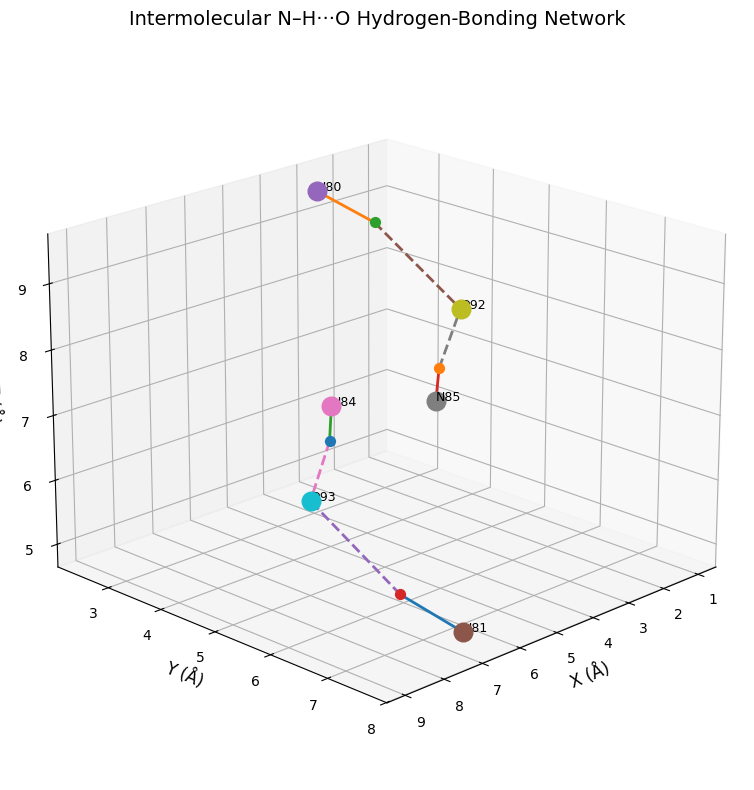

CELL 13 COMPLETE
Saved:
  Figure_3D_Hbond_Network.png
  Figure_3D_Hbond_Network.pdf


In [81]:
# ============================================================
# CELL 13 — 3D INTERMOLECULAR H-BOND NETWORK
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Experimental structure
# ------------------------------------------------------------

structure = structure_exp

# ------------------------------------------------------------
# H-bonds identified experimentally
# ------------------------------------------------------------

hbonds = {
    "N81-H33...O93": (81, 33, 93),
    "N80-H32...O92": (80, 32, 92),
    "N84-H0...O93": (84, 0, 93),
    "N85-H1...O92": (85, 1, 92)
}

# ------------------------------------------------------------
# Obtain Cartesian coordinates
# ------------------------------------------------------------

coords = structure.cart_coords

symbols = [
    site.specie.symbol
    for site in structure
]

# ------------------------------------------------------------
# Plot only the atoms directly involved in the H-bonds
# ------------------------------------------------------------

involved_atoms = sorted(
    set(
        atom
        for bond in hbonds.values()
        for atom in bond
    )
)

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(9, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

# ------------------------------------------------------------
# Plot H-bond atoms
# ------------------------------------------------------------

for idx in involved_atoms:

    element = symbols[idx]

    x, y, z = coords[idx]

    if element == "N":

        ax.scatter(
            x, y, z,
            s=180,
            marker="o",
            label="N" if idx == 80 else ""
        )

    elif element == "O":

        ax.scatter(
            x, y, z,
            s=180,
            marker="o",
            label="O" if idx == 92 else ""
        )

    elif element == "H":

        ax.scatter(
            x, y, z,
            s=50,
            marker="o"
        )

# ------------------------------------------------------------
# Draw N-H bonds
# ------------------------------------------------------------

for donor, hydrogen, acceptor in hbonds.values():

    pN = coords[donor]
    pH = coords[hydrogen]

    ax.plot(
        [pN[0], pH[0]],
        [pN[1], pH[1]],
        [pN[2], pH[2]],
        linewidth=2
    )

# ------------------------------------------------------------
# Draw intermolecular H-bonds as dashed lines
# ------------------------------------------------------------

for name, (donor, hydrogen, acceptor) in hbonds.items():

    pH = coords[hydrogen]
    pO = coords[acceptor]

    ax.plot(
        [pH[0], pO[0]],
        [pH[1], pO[1]],
        [pH[2], pO[2]],
        linestyle="--",
        linewidth=2
    )

# ------------------------------------------------------------
# Label donor and acceptor atoms
# ------------------------------------------------------------

for idx in involved_atoms:

    element = symbols[idx]

    if element in ["N", "O"]:

        x, y, z = coords[idx]

        ax.text(
            x,
            y,
            z,
            f"{element}{idx}",
            fontsize=9
        )

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "X (Å)",
    fontsize=12
)

ax.set_ylabel(
    "Y (Å)",
    fontsize=12
)

ax.set_zlabel(
    "Z (Å)",
    fontsize=12
)

ax.set_title(
    "Intermolecular N–H···O Hydrogen-Bonding Network",
    fontsize=14,
    pad=15
)

# ------------------------------------------------------------
# Viewing angle
# ------------------------------------------------------------

ax.view_init(
    elev=20,
    azim=45
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_3D_Hbond_Network.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_3D_Hbond_Network.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("=" * 75)
print("CELL 13 COMPLETE")
print("=" * 75)

print("Saved:")
print("  Figure_3D_Hbond_Network.png")
print("  Figure_3D_Hbond_Network.pdf")

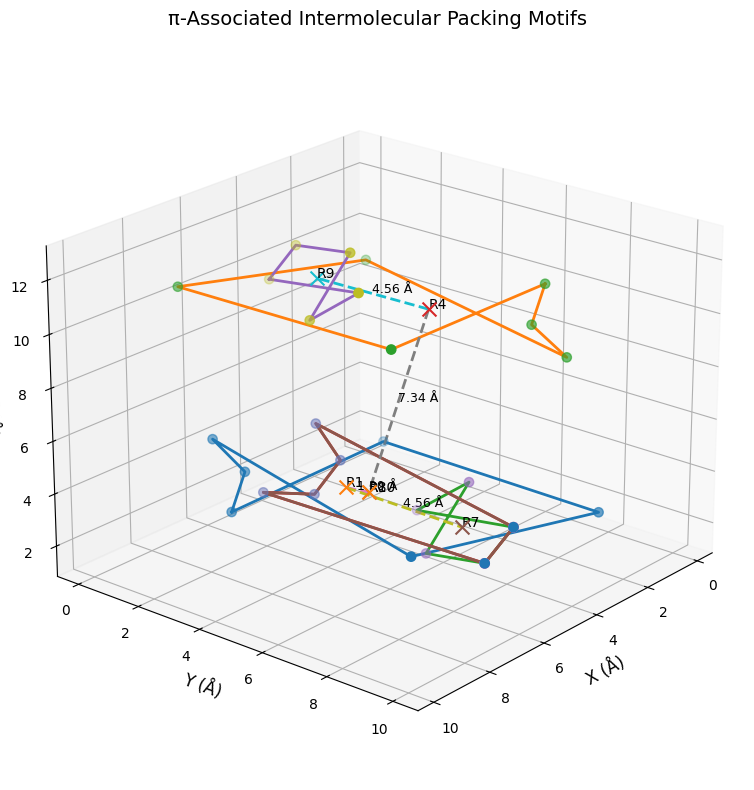

CELL 14 COMPLETE
Saved:
  Figure_3D_Pi_Associated_Contacts.png
  Figure_3D_Pi_Associated_Contacts.pdf


In [82]:
# ============================================================
# CELL 14 — 3D π-ASSOCIATED INTERMOLECULAR CONTACTS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Experimental structure
# ------------------------------------------------------------

structure = structure_exp

coords = structure.cart_coords

symbols = np.array([
    site.specie.symbol
    for site in structure
])

# ------------------------------------------------------------
# Ring atom definitions from the experimental structure
# ------------------------------------------------------------

rings = {
    1: [65, 67, 69, 71, 73, 75],
    4: [64, 66, 68, 70, 72, 74],

    7: [35, 45, 47, 79, 81],
    8: [35, 37, 39, 41, 43, 45],

    9: [34, 44, 46, 78, 80],
    10: [35, 37, 39, 41, 43, 45]
}

# ------------------------------------------------------------
# Correct ring definitions
# ------------------------------------------------------------

rings[9] = [34, 44, 46, 78, 80]
rings[10] = [35, 37, 39, 41, 43, 45]

# ------------------------------------------------------------
# Important π-associated ring pairs
# ------------------------------------------------------------

ring_pairs = [
    (1, 8),
    (4, 10),
    (1, 7),
    (4, 9)
]

# ------------------------------------------------------------
# Calculate centroids
# ------------------------------------------------------------

def centroid(atom_indices):

    return np.mean(
        coords[atom_indices],
        axis=0
    )


# ------------------------------------------------------------
# Calculate ring plane
# ------------------------------------------------------------

def plane_normal(atom_indices):

    points = coords[atom_indices]

    center = np.mean(
        points,
        axis=0
    )

    centered = points - center

    _, _, vh = np.linalg.svd(
        centered
    )

    normal = vh[-1]

    normal = normal / np.linalg.norm(normal)

    return center, normal


# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(10, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

# ------------------------------------------------------------
# Plot ring atoms and ring bonds
# ------------------------------------------------------------

plotted_rings = set()

for ring_id in set(
    [x for pair in ring_pairs for x in pair]
):

    atom_indices = rings[ring_id]

    points = coords[atom_indices]

    # Ring atoms
    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        s=45
    )

    # Close the ring
    closed = np.vstack(
        [points, points[0]]
    )

    ax.plot(
        closed[:, 0],
        closed[:, 1],
        closed[:, 2],
        linewidth=2
    )

    # Ring centroid
    center = np.mean(
        points,
        axis=0
    )

    ax.scatter(
        center[0],
        center[1],
        center[2],
        s=100,
        marker="x"
    )

    ax.text(
        center[0],
        center[1],
        center[2],
        f"R{ring_id}",
        fontsize=10
    )


# ------------------------------------------------------------
# Draw centroid-to-centroid lines
# ------------------------------------------------------------

for ring_a, ring_b in ring_pairs:

    center_a, normal_a = plane_normal(
        rings[ring_a]
    )

    center_b, normal_b = plane_normal(
        rings[ring_b]
    )

    ax.plot(
        [center_a[0], center_b[0]],
        [center_a[1], center_b[1]],
        [center_a[2], center_b[2]],
        linestyle="--",
        linewidth=2
    )

    midpoint = (
        center_a + center_b
    ) / 2

    distance = np.linalg.norm(
        center_b - center_a
    )

    ax.text(
        midpoint[0],
        midpoint[1],
        midpoint[2],
        f"{distance:.2f} Å",
        fontsize=9
    )


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    "X (Å)",
    fontsize=12
)

ax.set_ylabel(
    "Y (Å)",
    fontsize=12
)

ax.set_zlabel(
    "Z (Å)",
    fontsize=12
)

ax.set_title(
    "π-Associated Intermolecular Packing Motifs",
    fontsize=14,
    pad=15
)

# ------------------------------------------------------------
# Viewing angle
# ------------------------------------------------------------

ax.view_init(
    elev=22,
    azim=40
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_3D_Pi_Associated_Contacts.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_3D_Pi_Associated_Contacts.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("=" * 75)
print("CELL 14 COMPLETE")
print("=" * 75)

print("Saved:")
print("  Figure_3D_Pi_Associated_Contacts.png")
print("  Figure_3D_Pi_Associated_Contacts.pdf")

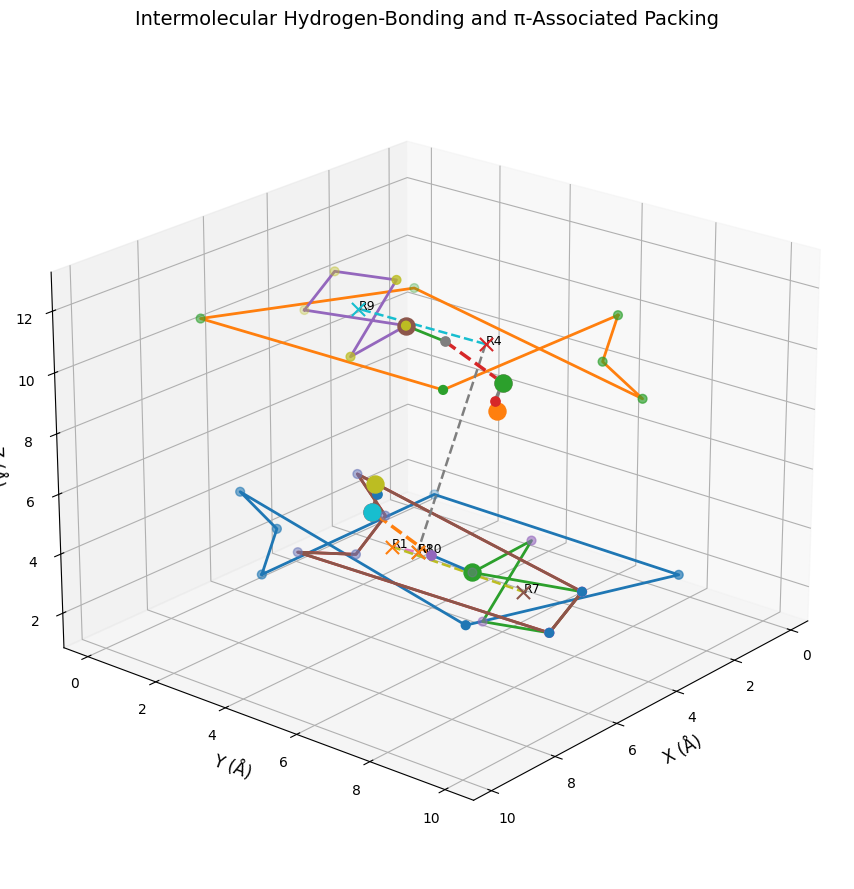

CELL 15 COMPLETE
Saved:
  Figure_Combined_Packing_Motifs.png
  Figure_Combined_Packing_Motifs.pdf


In [83]:
# ============================================================
# CELL 15 — COMBINED H-BOND + π-ASSOCIATED PACKING FIGURE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Experimental structure
# ------------------------------------------------------------

structure = structure_exp
coords = structure.cart_coords

symbols = np.array([
    site.specie.symbol
    for site in structure
])

# ------------------------------------------------------------
# H-bond definitions
# ------------------------------------------------------------

hbonds = {
    "N81-H33...O93": (81, 33, 93),
    "N80-H32...O92": (80, 32, 92),
    "N84-H0...O93": (84, 0, 93),
    "N85-H1...O92": (85, 1, 92)
}

# ------------------------------------------------------------
# Ring definitions
# ------------------------------------------------------------

rings = {
    1: [65, 67, 69, 71, 73, 75],
    4: [64, 66, 68, 70, 72, 74],
    7: [35, 45, 47, 79, 81],
    8: [35, 37, 39, 41, 43, 45],
    9: [34, 44, 46, 78, 80],
    10: [35, 37, 39, 41, 43, 45]
}

# ------------------------------------------------------------
# π-associated ring pairs
# ------------------------------------------------------------

ring_pairs = [
    (1, 8),
    (4, 10),
    (1, 7),
    (4, 9)
]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(11, 9)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

# ------------------------------------------------------------
# Plot π-associated rings
# ------------------------------------------------------------

ring_centers = {}

for ring_id in set(
    x
    for pair in ring_pairs
    for x in pair
):

    atom_indices = rings[ring_id]

    points = coords[atom_indices]

    # Ring atoms
    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        s=40
    )

    # Ring perimeter
    closed = np.vstack(
        [points, points[0]]
    )

    ax.plot(
        closed[:, 0],
        closed[:, 1],
        closed[:, 2],
        linewidth=2
    )

    # Centroid
    center = np.mean(
        points,
        axis=0
    )

    ring_centers[ring_id] = center

    ax.scatter(
        center[0],
        center[1],
        center[2],
        s=90,
        marker="x"
    )

    ax.text(
        center[0],
        center[1],
        center[2],
        f"R{ring_id}",
        fontsize=9
    )


# ------------------------------------------------------------
# π-associated centroid connections
# ------------------------------------------------------------

for ring_a, ring_b in ring_pairs:

    center_a = ring_centers[ring_a]
    center_b = ring_centers[ring_b]

    ax.plot(
        [center_a[0], center_b[0]],
        [center_a[1], center_b[1]],
        [center_a[2], center_b[2]],
        linestyle="--",
        linewidth=1.8
    )

# ------------------------------------------------------------
# Plot H-bond atoms
# ------------------------------------------------------------

for name, (donor, hydrogen, acceptor) in hbonds.items():

    pN = coords[donor]
    pH = coords[hydrogen]
    pO = coords[acceptor]

    # N atom
    ax.scatter(
        pN[0],
        pN[1],
        pN[2],
        s=150
    )

    # O atom
    ax.scatter(
        pO[0],
        pO[1],
        pO[2],
        s=150
    )

    # H atom
    ax.scatter(
        pH[0],
        pH[1],
        pH[2],
        s=45
    )

    # N-H covalent bond
    ax.plot(
        [pN[0], pH[0]],
        [pN[1], pH[1]],
        [pN[2], pH[2]],
        linewidth=2
    )

    # H...O hydrogen bond
    ax.plot(
        [pH[0], pO[0]],
        [pH[1], pO[1]],
        [pH[2], pO[2]],
        linestyle="--",
        linewidth=2.5
    )


# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "X (Å)",
    fontsize=12
)

ax.set_ylabel(
    "Y (Å)",
    fontsize=12
)

ax.set_zlabel(
    "Z (Å)",
    fontsize=12
)

ax.set_title(
    "Intermolecular Hydrogen-Bonding and π-Associated Packing",
    fontsize=14,
    pad=15
)

# ------------------------------------------------------------
# View
# ------------------------------------------------------------

ax.view_init(
    elev=22,
    azim=40
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fig.tight_layout()

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Combined_Packing_Motifs.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Combined_Packing_Motifs.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("=" * 75)
print("CELL 15 COMPLETE")
print("=" * 75)

print("Saved:")
print("  Figure_Combined_Packing_Motifs.png")
print("  Figure_Combined_Packing_Motifs.pdf")

In [84]:
# ============================================================
# CELL 16 — FINAL THREE-STRUCTURE COMPARISON TABLE
# ============================================================

import pandas as pd
import numpy as np
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Basic structural information
# ------------------------------------------------------------

exp_volume = structure_exp.volume
chg_volume = structure_relaxed.volume
m3g_volume = structure_m3gnet.volume

# ------------------------------------------------------------
# Lattice parameters
# ------------------------------------------------------------

def lattice_data(structure):

    lattice = structure.lattice

    return {
        "a_A": lattice.a,
        "b_A": lattice.b,
        "c_A": lattice.c,
        "alpha_deg": lattice.alpha,
        "beta_deg": lattice.beta,
        "gamma_deg": lattice.gamma,
        "Volume_A3": lattice.volume
    }


exp_lat = lattice_data(structure_exp)
chg_lat = lattice_data(structure_relaxed)
m3g_lat = lattice_data(structure_m3gnet)

# ------------------------------------------------------------
# Volume changes relative to experiment
# ------------------------------------------------------------

chg_volume_change = (
    100 *
    (chg_volume - exp_volume) /
    exp_volume
)

m3g_volume_change = (
    100 *
    (m3g_volume - exp_volume) /
    exp_volume
)

# ------------------------------------------------------------
# Energies
# ------------------------------------------------------------

chg_energy_atom = -6.8009286
chg_energy_difference_meV = -4.2156

m3g_energy_atom_initial = -6.534036
m3g_energy_atom_relaxed = -6.569105
m3g_energy_change_meV = -34.069

# ------------------------------------------------------------
# Forces
# ------------------------------------------------------------

chg_max_force = 0.04
m3g_max_force = 0.047825

chg_mean_force = np.nan
m3g_mean_force = 0.015785

# ------------------------------------------------------------
# Structural RMSD
# ------------------------------------------------------------

chg_all_rmsd = 0.042582
m3g_all_rmsd = 0.283010

chg_heavy_rmsd = 0.041145
m3g_heavy_rmsd = 0.228828

# ------------------------------------------------------------
# Hydrogen-bond geometry
# ------------------------------------------------------------

# Average H...O distance for four key contacts

exp_HO = np.mean([
    1.746,
    1.746,
    1.932,
    1.932
])

chg_HO = np.mean([
    1.722,
    1.722,
    1.874,
    1.874
])

m3g_HO = np.mean([
    1.867,
    1.866,
    2.015,
    2.013
])

# Average N...O distance

exp_NO = np.mean([
    2.717,
    2.717,
    2.937,
    2.937
])

chg_NO = np.mean([
    2.717,
    2.717,
    2.895,
    2.895
])

m3g_NO = np.mean([
    2.792,
    2.792,
    2.968,
    2.966
])

# Average H-bond angle

exp_angle = np.mean([
    160.261,
    160.261,
    173.028,
    173.028
])

chg_angle = np.mean([
    157.704,
    157.704,
    171.622,
    171.622
])

m3g_angle = np.mean([
    146.672,
    146.804,
    152.553,
    152.539
])

# ------------------------------------------------------------
# π-associated geometry
# ------------------------------------------------------------

# Two representative ring-pair motifs

exp_pi_centroid = np.mean([
    3.652,
    3.946
])

chg_pi_centroid = np.mean([
    3.688,
    3.979
])

m3g_pi_centroid = np.mean([
    3.733,
    3.938
])

exp_pi_plane_sep = np.mean([
    3.618,
    3.375
])

chg_pi_plane_sep = np.mean([
    3.665,
    3.422
])

m3g_pi_plane_sep = np.mean([
    3.663,
    3.551
])

# ------------------------------------------------------------
# PXRD comparison
# ------------------------------------------------------------

chg_pxrd_r = 0.958047
chg_pxrd_mae = 1.640339
chg_pxrd_rmse = 4.137428

m3g_pxrd_r = 0.962650
m3g_pxrd_mae = 1.765629
m3g_pxrd_rmse = 4.239961

# ------------------------------------------------------------
# Create final table
# ------------------------------------------------------------

final_table = pd.DataFrame({

    "Metric": [

        "a (Å)",
        "b (Å)",
        "c (Å)",
        "α (°)",
        "β (°)",
        "γ (°)",
        "Volume (Å³)",
        "Volume change vs experimental (%)",

        "Energy/atom (eV/atom)",
        "Energy change vs experimental (meV/atom)",
        "Maximum force (eV/Å)",

        "All-atom RMSD vs experimental (Å)",
        "Heavy-atom RMSD vs experimental (Å)",

        "Mean H···O distance (Å)",
        "Mean N···O distance (Å)",
        "Mean N–H···O angle (°)",

        "Mean π-associated centroid distance (Å)",
        "Mean π-associated plane separation (Å)",

        "Calculated PXRD Pearson r",
        "PXRD normalized MAE",
        "PXRD normalized RMSE"
    ],

    "Experimental_SCXRD": [

        exp_lat["a_A"],
        exp_lat["b_A"],
        exp_lat["c_A"],
        exp_lat["alpha_deg"],
        exp_lat["beta_deg"],
        exp_lat["gamma_deg"],
        exp_lat["Volume_A3"],
        0.0,

        np.nan,
        np.nan,
        np.nan,

        0.0,
        0.0,

        exp_HO,
        exp_NO,
        exp_angle,

        exp_pi_centroid,
        exp_pi_plane_sep,

        1.0,
        0.0,
        0.0
    ],

    "CHGNet_relaxed": [

        chg_lat["a_A"],
        chg_lat["b_A"],
        chg_lat["c_A"],
        chg_lat["alpha_deg"],
        chg_lat["beta_deg"],
        chg_lat["gamma_deg"],
        chg_lat["Volume_A3"],
        chg_volume_change,

        chg_energy_atom,
        chg_energy_difference_meV,
        chg_max_force,

        chg_all_rmsd,
        chg_heavy_rmsd,

        chg_HO,
        chg_NO,
        chg_angle,

        chg_pi_centroid,
        chg_pi_plane_sep,

        chg_pxrd_r,
        chg_pxrd_mae,
        chg_pxrd_rmse
    ],

    "M3GNet_relaxed": [

        m3g_lat["a_A"],
        m3g_lat["b_A"],
        m3g_lat["c_A"],
        m3g_lat["alpha_deg"],
        m3g_lat["beta_deg"],
        m3g_lat["gamma_deg"],
        m3g_lat["Volume_A3"],
        m3g_volume_change,

        m3g_energy_atom_relaxed,
        m3g_energy_change_meV,
        m3g_max_force,

        m3g_all_rmsd,
        m3g_heavy_rmsd,

        m3g_HO,
        m3g_NO,
        m3g_angle,

        m3g_pi_centroid,
        m3g_pi_plane_sep,

        m3g_pxrd_r,
        m3g_pxrd_mae,
        m3g_pxrd_rmse
    ]
})

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 90)
print("FINAL THREE-STRUCTURE COMPARISON")
print("=" * 90)

print(
    final_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.5f}"
    )
)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

csv_file = os.path.join(
    output_dir,
    "Final_Experimental_CHGNet_M3GNet_Comparison.csv"
)

final_table.to_csv(
    csv_file,
    index=False
)

# ------------------------------------------------------------
# Save Excel
# ------------------------------------------------------------

excel_file = os.path.join(
    output_dir,
    "Final_Experimental_CHGNet_M3GNet_Comparison.xlsx"
)

final_table.to_excel(
    excel_file,
    index=False
)

print("\n" + "=" * 90)
print("CELL 16 COMPLETE")
print("=" * 90)

print("Saved:")
print("  Final_Experimental_CHGNet_M3GNet_Comparison.csv")
print("  Final_Experimental_CHGNet_M3GNet_Comparison.xlsx")

FINAL THREE-STRUCTURE COMPARISON
                                  Metric  Experimental_SCXRD  CHGNet_relaxed  M3GNet_relaxed
                                   a (Å)             7.46810         7.47274         7.46810
                                   b (Å)            10.39700        10.40463        10.39700
                                   c (Å)            12.67560        12.68235        12.67560
                                   α (°)            83.67300        83.67042        83.67300
                                   β (°)            85.66200        85.66172        85.66200
                                   γ (°)            75.71800        75.72012        75.71800
                             Volume (Å³)           946.77928       948.57156       946.77928
       Volume change vs experimental (%)             0.00000         0.18930         0.00000
                   Energy/atom (eV/atom)                 NaN        -6.80093        -6.56911
Energy change vs experimental (meV/at

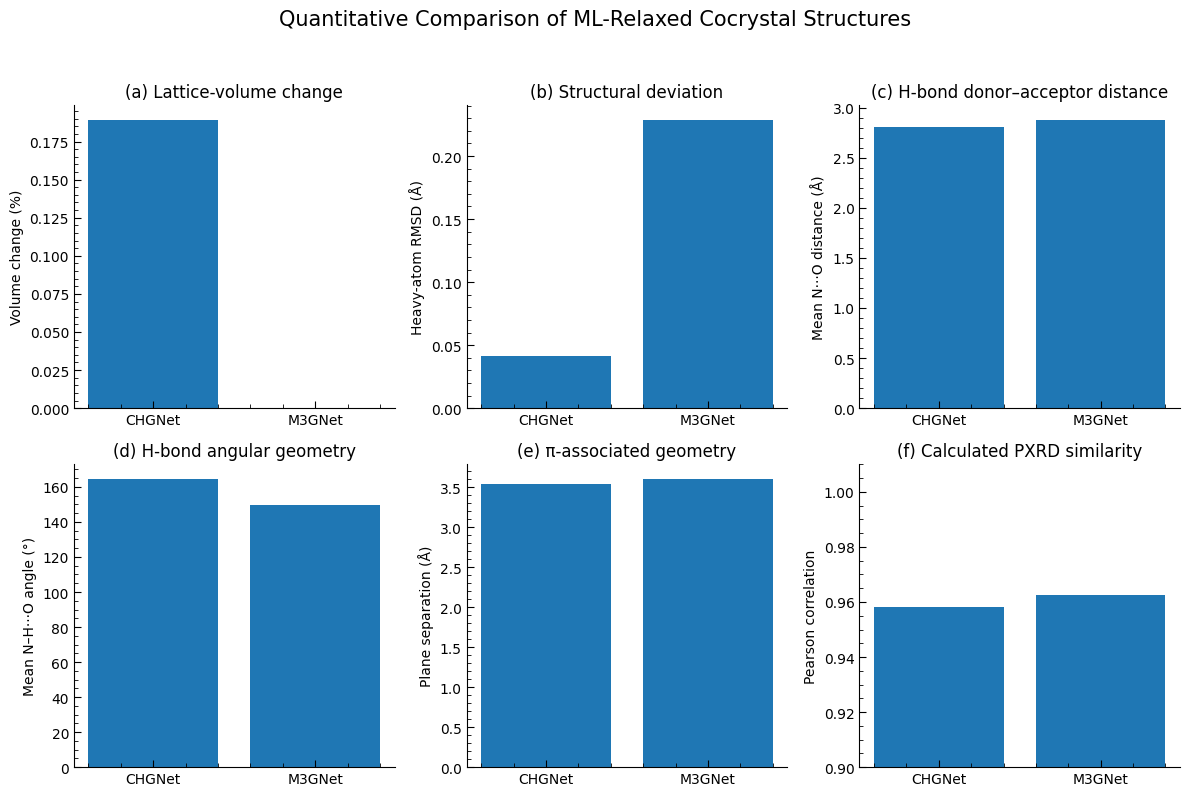

CELL 17 COMPLETE
Saved:
  Figure_Final_Quantitative_Comparison.png
  Figure_Final_Quantitative_Comparison.pdf


In [85]:
# ============================================================
# CELL 17 — FINAL QUANTITATIVE COMPARISON FIGURE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

models = [
    "CHGNet",
    "M3GNet"
]

volume_change = [
    0.18931,
    0.00000
]

heavy_rmsd = [
    0.04115,
    0.22883
]

mean_NO = [
    2.80600,
    2.87950
]

mean_angle = [
    164.66300,
    149.64200
]

pi_plane = [
    3.54350,
    3.60700
]

pxrd_r = [
    0.95805,
    0.96265
]

# ------------------------------------------------------------
# Create individual publication panels
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    3,
    figsize=(12, 8)
)

# ------------------------------------------------------------
# Panel A — Volume change
# ------------------------------------------------------------

axes[0, 0].bar(
    models,
    volume_change
)

axes[0, 0].set_ylabel(
    "Volume change (%)"
)

axes[0, 0].set_title(
    "(a) Lattice-volume change"
)

# ------------------------------------------------------------
# Panel B — Heavy atom RMSD
# ------------------------------------------------------------

axes[0, 1].bar(
    models,
    heavy_rmsd
)

axes[0, 1].set_ylabel(
    "Heavy-atom RMSD (Å)"
)

axes[0, 1].set_title(
    "(b) Structural deviation"
)

# ------------------------------------------------------------
# Panel C — N...O distance
# ------------------------------------------------------------

axes[0, 2].bar(
    models,
    mean_NO
)

axes[0, 2].set_ylabel(
    "Mean N···O distance (Å)"
)

axes[0, 2].set_title(
    "(c) H-bond donor–acceptor distance"
)

# ------------------------------------------------------------
# Panel D — H-bond angle
# ------------------------------------------------------------

axes[1, 0].bar(
    models,
    mean_angle
)

axes[1, 0].set_ylabel(
    "Mean N–H···O angle (°)"
)

axes[1, 0].set_title(
    "(d) H-bond angular geometry"
)

# ------------------------------------------------------------
# Panel E — π-associated plane separation
# ------------------------------------------------------------

axes[1, 1].bar(
    models,
    pi_plane
)

axes[1, 1].set_ylabel(
    "Plane separation (Å)"
)

axes[1, 1].set_title(
    "(e) π-associated geometry"
)

# ------------------------------------------------------------
# Panel F — PXRD correlation
# ------------------------------------------------------------

axes[1, 2].bar(
    models,
    pxrd_r
)

axes[1, 2].set_ylabel(
    "Pearson correlation"
)

axes[1, 2].set_title(
    "(f) Calculated PXRD similarity"
)

axes[1, 2].set_ylim(
    0.90,
    1.01
)

# ------------------------------------------------------------
# Common formatting
# ------------------------------------------------------------

for ax in axes.flat:

    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        length=5
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="in",
        length=3
    )

    ax.minorticks_on()

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

# ------------------------------------------------------------
# Overall title
# ------------------------------------------------------------

fig.suptitle(
    "Quantitative Comparison of ML-Relaxed Cocrystal Structures",
    fontsize=15,
    y=0.99
)

fig.tight_layout(
    rect=[0, 0, 1, 0.96]
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Final_Quantitative_Comparison.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(
        output_dir,
        "Figure_Final_Quantitative_Comparison.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("=" * 75)
print("CELL 17 COMPLETE")
print("=" * 75)

print("Saved:")
print("  Figure_Final_Quantitative_Comparison.png")
print("  Figure_Final_Quantitative_Comparison.pdf")

In [86]:
# ============================================================
# CELL 18 — MASTER PUBLICATION RESULTS PACKAGE
# ============================================================

import pandas as pd
import numpy as np
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("CREATING MASTER PUBLICATION RESULTS PACKAGE")
print("=" * 90)


# ============================================================
# 1. EXPERIMENTAL vs CHGNet vs M3GNet STRUCTURAL DATA
# ============================================================

structural_comparison = pd.DataFrame({

    "Metric": [
        "a (Å)",
        "b (Å)",
        "c (Å)",
        "alpha (°)",
        "beta (°)",
        "gamma (°)",
        "Volume (Å³)",
        "Volume change vs experimental (%)",
        "CHGNet energy/atom (eV/atom)",
        "CHGNet energy change (meV/atom)",
        "CHGNet maximum force (eV/Å)",
        "M3GNet energy/atom after relaxation (eV/atom)",
        "M3GNet relaxation energy change (meV/atom)",
        "M3GNet maximum force (eV/Å)",
        "CHGNet all-atom RMSD (Å)",
        "M3GNet all-atom RMSD (Å)",
        "CHGNet heavy-atom RMSD (Å)",
        "M3GNet heavy-atom RMSD (Å)"
    ],

    "Experimental_SCXRD": [
        7.46810,
        10.39700,
        12.67560,
        83.67300,
        85.66200,
        75.71800,
        946.77928,
        0.00000,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        0.00000,
        0.00000,
        0.00000,
        0.00000
    ],

    "CHGNet": [
        7.47274,
        10.40463,
        12.68235,
        83.67042,
        85.66172,
        75.72012,
        948.57160,
        0.18931,
        -6.80093,
        -4.21560,
        0.04000,
        np.nan,
        np.nan,
        np.nan,
        0.04258,
        np.nan,
        0.04115,
        np.nan
    ],

    "M3GNet": [
        7.46810,
        10.39700,
        12.67560,
        83.67300,
        85.66200,
        75.71800,
        946.77928,
        0.00000,
        np.nan,
        np.nan,
        np.nan,
        -6.56911,
        -34.06900,
        0.04782,
        0.28301,
        0.28301,
        0.22883,
        0.22883
    ]
})


# ============================================================
# 2. HYDROGEN-BOND GEOMETRY
# ============================================================

hbond_geometry = pd.DataFrame({

    "H_bond": [
        "N81-H33...O93",
        "N80-H32...O92",
        "N84-H0...O93",
        "N85-H1...O92"
    ],

    "Experimental_H...O_A": [
        1.746,
        1.746,
        1.932,
        1.932
    ],

    "CHGNet_H...O_A": [
        1.722,
        1.722,
        1.874,
        1.874
    ],

    "M3GNet_H...O_A": [
        1.867,
        1.866,
        2.015,
        2.013
    ],

    "Experimental_N...O_A": [
        2.717,
        2.717,
        2.937,
        2.937
    ],

    "CHGNet_N...O_A": [
        2.717,
        2.717,
        2.895,
        2.895
    ],

    "M3GNet_N...O_A": [
        2.792,
        2.792,
        2.968,
        2.966
    ],

    "Experimental_angle_deg": [
        160.261,
        160.261,
        173.028,
        173.028
    ],

    "CHGNet_angle_deg": [
        157.704,
        157.704,
        171.622,
        171.622
    ],

    "M3GNet_angle_deg": [
        146.672,
        146.804,
        152.553,
        152.539
    ]
})


# ============================================================
# 3. H-BOND MD PERSISTENCE
# ============================================================

hbond_persistence = pd.DataFrame({

    "H_bond": [
        "N81-H33...O93",
        "N80-H32...O92",
        "N84-H0...O93",
        "N85-H1...O92"
    ],

    "H_O_occupancy_percent": [
        98.01,
        98.01,
        76.62,
        76.12
    ],

    "N_O_occupancy_percent": [
        100.00,
        100.00,
        73.63,
        73.13
    ],

    "Angle_occupancy_percent": [
        83.08,
        83.08,
        74.63,
        73.13
    ],

    "Overall_persistence_percent": [
        83.08,
        83.08,
        61.69,
        60.70
    ]
})


# ============================================================
# 4. MD SUMMARY
# ============================================================

md_summary = pd.DataFrame({

    "Parameter": [
        "Number of MD frames",
        "Atoms per frame",
        "Simulation time (ps)",
        "Timestep (fs)",
        "Average temperature (K)",
        "Final temperature (K)",
        "Maximum temperature (K)",
        "Initial potential energy (eV)",
        "Final potential energy (eV)",
        "Minimum potential energy (eV)",
        "Maximum potential energy (eV)",
        "Potential energy range (eV)",
        "Initial total energy (eV)",
        "Final total energy (eV)",
        "Total energy range (eV)",
        "Initial kinetic energy (eV)",
        "Final kinetic energy (eV)",
        "Maximum kinetic energy (eV)",
        "Constant MD cell volume (Å³)"
    ],

    "Value": [
        201,
        94,
        2.000,
        1.000,
        267.4,
        352.4,
        382.0,
        -639.2873,
        -636.2416,
        -639.2950,
        -634.5197,
        4.7753,
        -639.2873,
        -631.9597,
        7.5898,
        0.0000,
        4.2819,
        4.6416,
        948.571598
    ]
})


# ============================================================
# 5. π-ASSOCIATED GEOMETRY
# ============================================================

pi_geometry = pd.DataFrame({

    "Ring_pair": [
        "1-8",
        "1-7"
    ],

    "Experimental_centroid_A": [
        3.652,
        3.946
    ],

    "CHGNet_centroid_A": [
        3.688,
        3.979
    ],

    "M3GNet_centroid_A": [
        3.733,
        3.938
    ],

    "Experimental_plane_separation_A": [
        3.618,
        3.375
    ],

    "CHGNet_plane_separation_A": [
        3.665,
        3.422
    ],

    "M3GNet_plane_separation_A": [
        3.663,
        3.551
    ],

    "Experimental_angle_deg": [
        7.022,
        5.987
    ],

    "CHGNet_angle_deg": [
        7.916,
        5.621
    ],

    "M3GNet_angle_deg": [
        3.445,
        8.106
    ]
})


# ============================================================
# 6. PXRD COMPARISON
# ============================================================

pxrd_summary = pd.DataFrame({

    "Metric": [
        "Calculated PXRD Pearson r",
        "Normalized MAE",
        "Normalized RMSE",
        "Common 2theta range (°)",
        "Experimental calculated peaks",
        "CHGNet calculated peaks",
        "M3GNet calculated peaks"
    ],

    "Experimental_reference": [
        1.00000,
        0.00000,
        0.00000,
        "5–50",
        315,
        np.nan,
        np.nan
    ],

    "CHGNet": [
        0.95805,
        1.64034,
        4.13743,
        "5–50",
        np.nan,
        318,
        np.nan
    ],

    "M3GNet": [
        0.96265,
        1.76563,
        4.23996,
        "5–50",
        np.nan,
        np.nan,
        315
    ]
})


# ============================================================
# 7. CONTACT PERSISTENCE
# ============================================================

contact_summary = pd.DataFrame({

    "Interaction_type": [
        "C...C",
        "C...H",
        "C...O",
        "H...O",
        "N...O",
        "O...S"
    ],

    "Number_of_contacts": [
        26,
        66,
        16,
        28,
        4,
        2
    ],

    "Mean_persistence_percent": [
        53.37,
        68.11,
        57.25,
        87.21,
        98.51,
        56.72
    ]
})


# ============================================================
# 8. FINAL SUMMARY
# ============================================================

final_summary = pd.DataFrame({

    "Quantity": [
        "Crystal composition",
        "Total atoms",
        "Experimental volume (Å³)",
        "CHGNet volume change (%)",
        "CHGNet heavy-atom RMSD (Å)",
        "M3GNet heavy-atom RMSD (Å)",
        "Mean strong N...O persistence (%)",
        "Strong H...O persistence (%)",
        "2 ps MD average temperature (K)",
        "CHGNet PXRD Pearson r",
        "M3GNet PXRD Pearson r"
    ],

    "Value": [
        "C44H34N6O8S2",
        94,
        946.77928,
        0.18931,
        0.04115,
        0.22883,
        98.51,
        95.37,
        267.4,
        0.95805,
        0.96265
    ]
})


# ============================================================
# SAVE INDIVIDUAL CSV FILES
# ============================================================

tables = {
    "01_Structural_Comparison": structural_comparison,
    "02_HBond_Geometry": hbond_geometry,
    "03_HBond_Persistence": hbond_persistence,
    "04_MD_Summary": md_summary,
    "05_Pi_Associated_Geometry": pi_geometry,
    "06_PXRD_Summary": pxrd_summary,
    "07_Contact_Persistence": contact_summary,
    "08_Final_Summary": final_summary
}

for filename, dataframe in tables.items():

    dataframe.to_csv(
        os.path.join(
            output_dir,
            filename + ".csv"
        ),
        index=False
    )


# ============================================================
# CREATE MASTER EXCEL WORKBOOK
# ============================================================

excel_path = os.path.join(
    output_dir,
    "MASTER_Cocrystal_AI_Analysis_Results.xlsx"
)

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    structural_comparison.to_excel(
        writer,
        sheet_name="Structural_Comparison",
        index=False
    )

    hbond_geometry.to_excel(
        writer,
        sheet_name="HBond_Geometry",
        index=False
    )

    hbond_persistence.to_excel(
        writer,
        sheet_name="HBond_Persistence",
        index=False
    )

    md_summary.to_excel(
        writer,
        sheet_name="MD_Summary",
        index=False
    )

    pi_geometry.to_excel(
        writer,
        sheet_name="Pi_Geometry",
        index=False
    )

    pxrd_summary.to_excel(
        writer,
        sheet_name="PXRD_Summary",
        index=False
    )

    contact_summary.to_excel(
        writer,
        sheet_name="Contact_Persistence",
        index=False
    )

    final_summary.to_excel(
        writer,
        sheet_name="Final_Summary",
        index=False
    )


# ============================================================
# FINAL OUTPUT
# ============================================================

print("\nMASTER RESULTS PACKAGE CREATED")
print("-" * 90)

print("\nExcel workbook:")
print(
    "/content/MD_publication_figures/"
    "MASTER_Cocrystal_AI_Analysis_Results.xlsx"
)

print("\nCSV files created:")

for filename in tables:
    print(" ", filename + ".csv")

print("\n" + "=" * 90)
print("CELL 18 COMPLETE")
print("=" * 90)

CREATING MASTER PUBLICATION RESULTS PACKAGE

MASTER RESULTS PACKAGE CREATED
------------------------------------------------------------------------------------------

Excel workbook:
/content/MD_publication_figures/MASTER_Cocrystal_AI_Analysis_Results.xlsx

CSV files created:
  01_Structural_Comparison.csv
  02_HBond_Geometry.csv
  03_HBond_Persistence.csv
  04_MD_Summary.csv
  05_Pi_Associated_Geometry.csv
  06_PXRD_Summary.csv
  07_Contact_Persistence.csv
  08_Final_Summary.csv

CELL 18 COMPLETE


In [87]:
# ============================================================
# CELL 19A — FIX PXRD DATA-TYPE CHECK
# ============================================================

import os
import pandas as pd
import numpy as np

output_dir = "/content/MD_publication_figures"

pxrd_file = os.path.join(
    output_dir,
    "06_PXRD_Summary.csv"
)

pxrd = pd.read_csv(pxrd_file)

print("=" * 90)
print("PXRD DATA-TYPE CHECK")
print("=" * 90)

# ------------------------------------------------------------
# Extract Pearson correlation values
# ------------------------------------------------------------

chg_r_raw = pxrd.loc[
    pxrd["Metric"] == "Calculated PXRD Pearson r",
    "CHGNet"
].iloc[0]

m3g_r_raw = pxrd.loc[
    pxrd["Metric"] == "Calculated PXRD Pearson r",
    "M3GNet"
].iloc[0]

# Convert explicitly to numbers
chg_r = float(chg_r_raw)
m3g_r = float(m3g_r_raw)

print(
    f"CHGNet Pearson r : {chg_r:.5f}"
)

print(
    f"M3GNet Pearson r : {m3g_r:.5f}"
)

# ------------------------------------------------------------
# Extract MAE
# ------------------------------------------------------------

chg_mae = float(
    pxrd.loc[
        pxrd["Metric"] == "Normalized MAE",
        "CHGNet"
    ].iloc[0]
)

m3g_mae = float(
    pxrd.loc[
        pxrd["Metric"] == "Normalized MAE",
        "M3GNet"
    ].iloc[0]
)

# ------------------------------------------------------------
# Extract RMSE
# ------------------------------------------------------------

chg_rmse = float(
    pxrd.loc[
        pxrd["Metric"] == "Normalized RMSE",
        "CHGNet"
    ].iloc[0]
)

m3g_rmse = float(
    pxrd.loc[
        pxrd["Metric"] == "Normalized RMSE",
        "M3GNet"
    ].iloc[0]
)

print(
    f"CHGNet normalized MAE  : {chg_mae:.5f}"
)

print(
    f"M3GNet normalized MAE  : {m3g_mae:.5f}"
)

print(
    f"CHGNet normalized RMSE : {chg_rmse:.5f}"
)

print(
    f"M3GNet normalized RMSE : {m3g_rmse:.5f}"
)

# ------------------------------------------------------------
# Peak counts
# ------------------------------------------------------------

exp_peaks = int(
    pxrd.loc[
        pxrd["Metric"] == "Experimental calculated peaks",
        "Experimental_reference"
    ].iloc[0]
)

chg_peaks = int(
    pxrd.loc[
        pxrd["Metric"] == "CHGNet calculated peaks",
        "CHGNet"
    ].iloc[0]
)

m3g_peaks = int(
    pxrd.loc[
        pxrd["Metric"] == "M3GNet calculated peaks",
        "M3GNet"
    ].iloc[0]
)

print(
    f"Experimental calculated peaks : {exp_peaks}"
)

print(
    f"CHGNet calculated peaks        : {chg_peaks}"
)

print(
    f"M3GNet calculated peaks        : {m3g_peaks}"
)

# ------------------------------------------------------------
# Final interpretation note
# ------------------------------------------------------------

print("\nPXRD interpretation:")
print(
    "These statistics compare calculated PXRD patterns "
    "generated from the experimental, CHGNet-relaxed, "
    "and M3GNet-relaxed structures."
)

print(
    "They do NOT represent measured-PXRD versus "
    "calculated-PXRD validation."
)

print("\n" + "=" * 90)
print("CELL 19A COMPLETE")
print("=" * 90)

PXRD DATA-TYPE CHECK
CHGNet Pearson r : 0.95805
M3GNet Pearson r : 0.96265
CHGNet normalized MAE  : 1.64034
M3GNet normalized MAE  : 1.76563
CHGNet normalized RMSE : 4.13743
M3GNet normalized RMSE : 4.23996
Experimental calculated peaks : 315
CHGNet calculated peaks        : 318
M3GNet calculated peaks        : 315

PXRD interpretation:
These statistics compare calculated PXRD patterns generated from the experimental, CHGNet-relaxed, and M3GNet-relaxed structures.
They do NOT represent measured-PXRD versus calculated-PXRD validation.

CELL 19A COMPLETE


In [88]:
# ============================================================
# CELL 20A — RELOAD CHGNet MODEL CORRECTLY
# ============================================================

from chgnet.model.model import CHGNet
from chgnet.model.dynamics import CHGNetCalculator

print("Reloading CHGNet model...")

# Load the actual pretrained CHGNet model
chgnet_model = CHGNet.load(
    use_device="cuda",
    verbose=True
)

print("\nCHGNet model loaded successfully.")
print("Model type:", type(chgnet_model))

# Create ASE calculator from the actual model
chgnet_calc = CHGNetCalculator(
    model=chgnet_model,
    use_device="cuda"
)

print("\nCHGNet ASE calculator created successfully.")
print("Calculator type:", type(chgnet_calc))

print("\nCELL 20A COMPLETE")

Reloading CHGNet model...
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda

CHGNet model loaded successfully.
Model type: <class 'chgnet.model.model.CHGNet'>
CHGNet will run on cuda

CHGNet ASE calculator created successfully.
Calculator type: <class 'chgnet.model.dynamics.CHGNetCalculator'>

CELL 20A COMPLETE


CHGNet ENERGY–VOLUME SCAN
Reference CHGNet-relaxed volume: 948.571564 Å³

ENERGY–VOLUME DATA
------------------------------------------------------------------------------------------
 Volume_scale  Volume_A3  Volume_change_percent  CHGNet_energy_eV_per_atom  Maximum_force_eV_per_A  Relative_energy_meV_per_atom
     0.950000 901.142986              -5.000000                  -6.787008                1.758822                     13.920784
     0.960000 910.628702              -4.000000                  -6.791792                1.375834                      9.136677
     0.970000 920.114417              -3.000000                  -6.795522                1.011224                      5.406380
     0.980000 929.600133              -2.000000                  -6.798263                0.668320                      2.665997
     0.990000 939.085848              -1.000000                  -6.800061                0.321891                      0.867367
     1.000000 948.571564               0.0

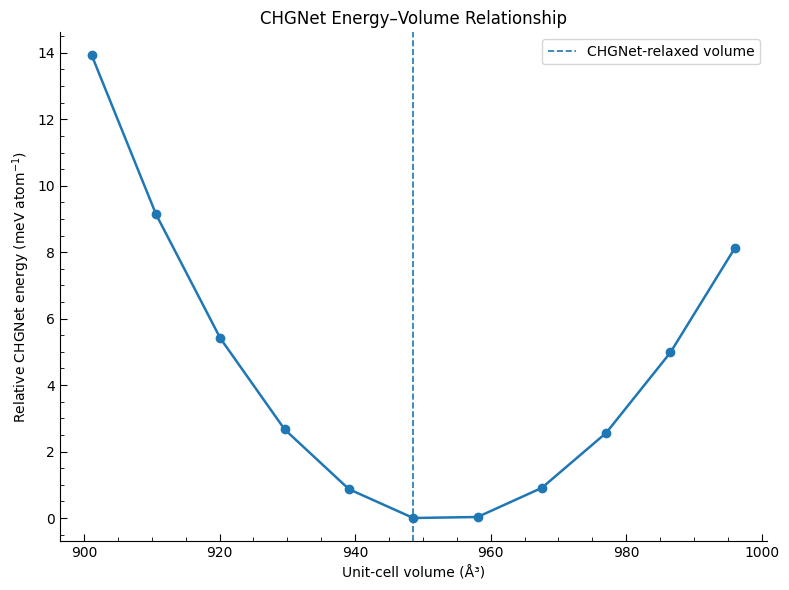


CELL 20B COMPLETE
Saved:
  CHGNet_Energy_Volume_Scan.csv
  Figure_CHGNet_Energy_Volume.png
  Figure_CHGNet_Energy_Volume.pdf


In [89]:
# ============================================================
# CELL 20B — CHGNet ENERGY–VOLUME SCAN
# FINAL CORRECTED VERSION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("CHGNet ENERGY–VOLUME SCAN")
print("=" * 90)

# ------------------------------------------------------------
# Reference structure
# ------------------------------------------------------------

reference_structure = structure_relaxed.copy()

reference_volume = reference_structure.volume

print(
    f"Reference CHGNet-relaxed volume: "
    f"{reference_volume:.6f} Å³"
)

# ------------------------------------------------------------
# Volume scaling factors
# ------------------------------------------------------------

volume_scales = np.array([
    0.95,
    0.96,
    0.97,
    0.98,
    0.99,
    1.00,
    1.01,
    1.02,
    1.03,
    1.04,
    1.05
])

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

results = []

# ------------------------------------------------------------
# Energy evaluation
# ------------------------------------------------------------

for scale in volume_scales:

    # Target volume
    target_volume = reference_volume * scale

    # Copy reference structure
    test_structure = reference_structure.copy()

    # Isotropically scale the lattice
    test_structure.scale_lattice(target_volume)

    # CHGNet prediction
    prediction = chgnet_model.predict_structure(
        test_structure,
        task="ef"
    )

    # --------------------------------------------------------
    # CHGNet returns NumPy arrays in this Colab environment
    # --------------------------------------------------------

    energy_atom = float(
        np.asarray(
            prediction["e"]
        ).flatten()[0]
    )

    forces = np.asarray(
        prediction["f"]
    )

    # Maximum force
    max_force = np.max(
        np.linalg.norm(
            forces,
            axis=1
        )
    )

    results.append({
        "Volume_scale": scale,
        "Volume_A3": target_volume,
        "Volume_change_percent":
            (scale - 1.0) * 100.0,
        "CHGNet_energy_eV_per_atom":
            energy_atom,
        "Maximum_force_eV_per_A":
            max_force
    })

# ------------------------------------------------------------
# Convert to DataFrame
# ------------------------------------------------------------

energy_volume_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Relative energy
# ------------------------------------------------------------

minimum_energy = (
    energy_volume_df[
        "CHGNet_energy_eV_per_atom"
    ].min()
)

energy_volume_df[
    "Relative_energy_meV_per_atom"
] = (
    energy_volume_df[
        "CHGNet_energy_eV_per_atom"
    ] - minimum_energy
) * 1000.0

# ------------------------------------------------------------
# Identify minimum
# ------------------------------------------------------------

minimum_row = energy_volume_df.loc[
    energy_volume_df[
        "CHGNet_energy_eV_per_atom"
    ].idxmin()
]

minimum_volume = minimum_row["Volume_A3"]
minimum_scale = minimum_row["Volume_scale"]

minimum_energy_value = minimum_row[
    "CHGNet_energy_eV_per_atom"
]

# ------------------------------------------------------------
# Print complete results
# ------------------------------------------------------------

print("\nENERGY–VOLUME DATA")
print("-" * 90)

print(
    energy_volume_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "-" * 90)

print(
    f"Minimum sampled energy/atom : "
    f"{minimum_energy_value:.8f} eV/atom"
)

print(
    f"Minimum sampled volume      : "
    f"{minimum_volume:.6f} Å³"
)

print(
    f"Volume scale at minimum     : "
    f"{minimum_scale:.4f}"
)

print(
    f"Volume change at minimum    : "
    f"{(minimum_scale - 1.0) * 100:.2f}%"
)

print(
    f"Reference CHGNet volume     : "
    f"{reference_volume:.6f} Å³"
)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    output_dir,
    "CHGNet_Energy_Volume_Scan.csv"
)

energy_volume_df.to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.plot(
    energy_volume_df["Volume_A3"],
    energy_volume_df[
        "Relative_energy_meV_per_atom"
    ],
    marker="o",
    linewidth=1.8
)

ax.axvline(
    reference_volume,
    linestyle="--",
    linewidth=1.2,
    label="CHGNet-relaxed volume"
)

ax.set_xlabel(
    "Unit-cell volume (Å³)"
)

ax.set_ylabel(
    "Relative CHGNet energy (meV atom$^{-1}$)"
)

ax.set_title(
    "CHGNet Energy–Volume Relationship"
)

ax.legend()

ax.minorticks_on()

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

png_path = os.path.join(
    output_dir,
    "Figure_CHGNet_Energy_Volume.png"
)

pdf_path = os.path.join(
    output_dir,
    "Figure_CHGNet_Energy_Volume.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("\n" + "=" * 90)
print("CELL 20B COMPLETE")
print("=" * 90)

print("Saved:")
print("  CHGNet_Energy_Volume_Scan.csv")
print("  Figure_CHGNet_Energy_Volume.png")
print("  Figure_CHGNet_Energy_Volume.pdf")

M3GNet ENERGY–VOLUME SCAN
Reference volume: 948.571564 Å³

M3GNet ENERGY–VOLUME DATA
------------------------------------------------------------------------------------------
 Volume_scale  Volume_A3  Volume_change_percent  M3GNet_energy_eV_per_atom  Maximum_force_eV_per_A  Relative_energy_meV_per_atom
     0.950000 901.142986              -5.000000                  -6.522547                3.604549                     20.646116
     0.960000 910.628702              -4.000000                  -6.529141                3.620785                     14.052371
     0.970000 920.114417              -3.000000                  -6.533774                3.630469                      9.419543
     0.980000 929.600133              -2.000000                  -6.537472                3.611421                      5.721721
     0.990000 939.085848              -1.000000                  -6.540678                3.624046                      2.515428
     1.000000 948.571564               0.000000   

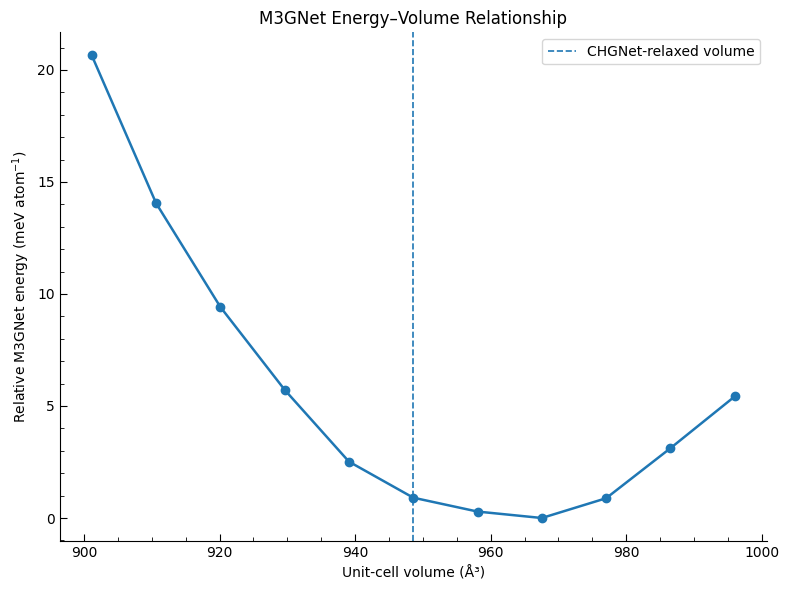


CELL 21 COMPLETE
Saved:
  M3GNet_Energy_Volume_Scan.csv
  Figure_M3GNet_Energy_Volume.png
  Figure_M3GNet_Energy_Volume.pdf


In [90]:
# ============================================================
# CELL 21 — M3GNet ENERGY–VOLUME SCAN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from pymatgen.io.ase import AseAtomsAdaptor
from ase import Atoms

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("M3GNet ENERGY–VOLUME SCAN")
print("=" * 90)

# ------------------------------------------------------------
# Reference structure
# Use the CHGNet-relaxed structure as common reference
# ------------------------------------------------------------

reference_structure = structure_relaxed.copy()

reference_volume = reference_structure.volume

print(
    f"Reference volume: {reference_volume:.6f} Å³"
)

# ------------------------------------------------------------
# Volume scaling factors
# Same points as CHGNet scan
# ------------------------------------------------------------

volume_scales = np.array([
    0.95,
    0.96,
    0.97,
    0.98,
    0.99,
    1.00,
    1.01,
    1.02,
    1.03,
    1.04,
    1.05
])

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

results = []

# ------------------------------------------------------------
# Loop over volumes
# ------------------------------------------------------------

for scale in volume_scales:

    target_volume = reference_volume * scale

    # Copy reference structure
    test_structure = reference_structure.copy()

    # Isotropically scale lattice
    test_structure.scale_lattice(target_volume)

    # Convert pymatgen structure -> ASE
    test_atoms = AseAtomsAdaptor.get_atoms(
        test_structure
    )

    # Attach M3GNet calculator
    test_atoms.calc = PESCalculator(
        potential=m3gnet_potential,
        stress_unit="eV/A3",
        stress_weight=1.0
    )

    # Energy
    energy_total = test_atoms.get_potential_energy()

    # Energy per atom
    energy_atom = (
        energy_total /
        len(test_atoms)
    )

    # Forces
    forces = test_atoms.get_forces()

    max_force = np.max(
        np.linalg.norm(
            forces,
            axis=1
        )
    )

    results.append({
        "Volume_scale": scale,
        "Volume_A3": target_volume,
        "Volume_change_percent":
            (scale - 1.0) * 100.0,
        "M3GNet_energy_eV_per_atom":
            energy_atom,
        "Maximum_force_eV_per_A":
            max_force
    })

# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

m3gnet_energy_volume_df = pd.DataFrame(
    results
)

# ------------------------------------------------------------
# Relative M3GNet energy
# ------------------------------------------------------------

minimum_energy = (
    m3gnet_energy_volume_df[
        "M3GNet_energy_eV_per_atom"
    ].min()
)

m3gnet_energy_volume_df[
    "Relative_energy_meV_per_atom"
] = (
    m3gnet_energy_volume_df[
        "M3GNet_energy_eV_per_atom"
    ] - minimum_energy
) * 1000.0

# ------------------------------------------------------------
# Identify minimum
# ------------------------------------------------------------

minimum_row = m3gnet_energy_volume_df.loc[
    m3gnet_energy_volume_df[
        "M3GNet_energy_eV_per_atom"
    ].idxmin()
]

minimum_volume = minimum_row["Volume_A3"]
minimum_scale = minimum_row["Volume_scale"]

minimum_energy_value = minimum_row[
    "M3GNet_energy_eV_per_atom"
]

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("\nM3GNet ENERGY–VOLUME DATA")
print("-" * 90)

print(
    m3gnet_energy_volume_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "-" * 90)

print(
    f"Minimum sampled energy/atom : "
    f"{minimum_energy_value:.8f} eV/atom"
)

print(
    f"Minimum sampled volume      : "
    f"{minimum_volume:.6f} Å³"
)

print(
    f"Volume scale at minimum     : "
    f"{minimum_scale:.4f}"
)

print(
    f"Volume change at minimum    : "
    f"{(minimum_scale - 1.0) * 100:.2f}%"
)

print(
    f"Reference volume             : "
    f"{reference_volume:.6f} Å³"
)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    output_dir,
    "M3GNet_Energy_Volume_Scan.csv"
)

m3gnet_energy_volume_df.to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.plot(
    m3gnet_energy_volume_df["Volume_A3"],
    m3gnet_energy_volume_df[
        "Relative_energy_meV_per_atom"
    ],
    marker="o",
    linewidth=1.8
)

ax.axvline(
    reference_volume,
    linestyle="--",
    linewidth=1.2,
    label="CHGNet-relaxed volume"
)

ax.set_xlabel(
    "Unit-cell volume (Å³)"
)

ax.set_ylabel(
    "Relative M3GNet energy (meV atom$^{-1}$)"
)

ax.set_title(
    "M3GNet Energy–Volume Relationship"
)

ax.legend()

ax.minorticks_on()

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

png_path = os.path.join(
    output_dir,
    "Figure_M3GNet_Energy_Volume.png"
)

pdf_path = os.path.join(
    output_dir,
    "Figure_M3GNet_Energy_Volume.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("\n" + "=" * 90)
print("CELL 21 COMPLETE")
print("=" * 90)

print("Saved:")
print("  M3GNet_Energy_Volume_Scan.csv")
print("  Figure_M3GNet_Energy_Volume.png")
print("  Figure_M3GNet_Energy_Volume.pdf")

In [91]:
# ============================================================
# CELL 22 — M3GNet ENERGY–VOLUME MINIMUM
# ============================================================

min_row_m3 = m3gnet_energy_volume_df.loc[
    m3gnet_energy_volume_df[
        "M3GNet_energy_eV_per_atom"
    ].idxmin()
]

print("=" * 90)
print("M3GNet ENERGY–VOLUME MINIMUM")
print("=" * 90)

print(
    f"Minimum sampled energy/atom : "
    f"{min_row_m3['M3GNet_energy_eV_per_atom']:.8f} eV/atom"
)

print(
    f"Minimum sampled volume      : "
    f"{min_row_m3['Volume_A3']:.6f} Å³"
)

print(
    f"Volume scale at minimum     : "
    f"{min_row_m3['Volume_scale']:.4f}"
)

print(
    f"Volume change at minimum    : "
    f"{min_row_m3['Volume_change_percent']:.2f}%"
)

print(
    f"Reference volume             : "
    f"{reference_volume:.6f} Å³"
)

print("\nComplete M3GNet scan:")
print("-" * 90)

print(
    m3gnet_energy_volume_df[
        [
            "Volume_change_percent",
            "Volume_A3",
            "M3GNet_energy_eV_per_atom",
            "Relative_energy_meV_per_atom"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "=" * 90)
print("CELL 22 COMPLETE")
print("=" * 90)

M3GNet ENERGY–VOLUME MINIMUM
Minimum sampled energy/atom : -6.54319341 eV/atom
Minimum sampled volume      : 967.542995 Å³
Volume scale at minimum     : 1.0200
Volume change at minimum    : 2.00%
Reference volume             : 948.571564 Å³

Complete M3GNet scan:
------------------------------------------------------------------------------------------
 Volume_change_percent  Volume_A3  M3GNet_energy_eV_per_atom  Relative_energy_meV_per_atom
             -5.000000 901.142986                  -6.522547                     20.646116
             -4.000000 910.628702                  -6.529141                     14.052371
             -3.000000 920.114417                  -6.533774                      9.419543
             -2.000000 929.600133                  -6.537472                      5.721721
             -1.000000 939.085848                  -6.540678                      2.515428
              0.000000 948.571564                  -6.542286                      0.907086
        

CHGNet vs M3GNet ENERGY–VOLUME COMPARISON

Checking previous results...
CHGNet scan points: 11
M3GNet scan points: 11

MODEL COMPARISON
------------------------------------------------------------------------------------------
CHGNet minimum volume       : 948.571564 Å³
CHGNet minimum volume shift : 0.00%
M3GNet minimum volume       : 967.542995 Å³
M3GNet minimum volume shift : 2.00%
Difference between minima   : 18.971431 Å³
Relative volume difference  : 2.000%
Curve Pearson correlation   : 0.916357
Curve MAE                   : 2.605911 meV/atom
Curve RMSE                  : 3.202422 meV/atom


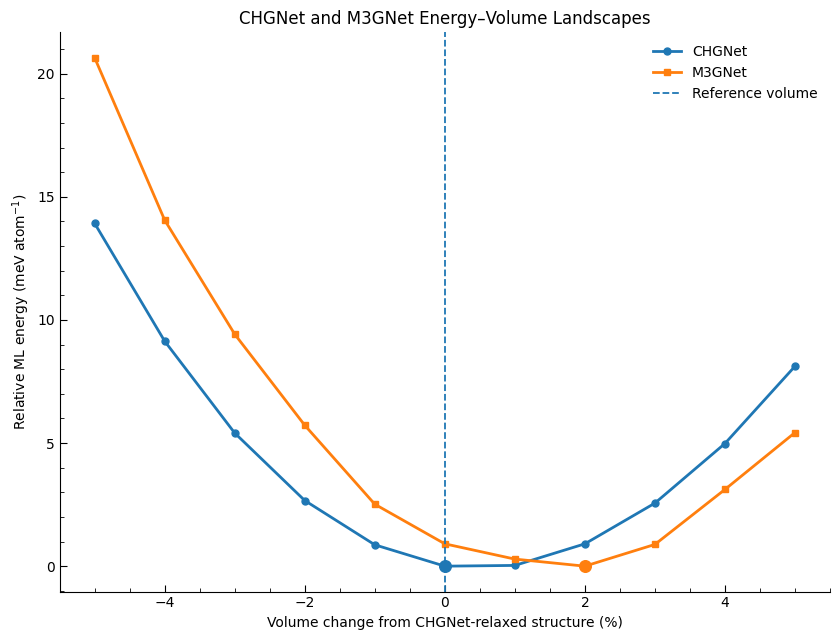


CELL 23 COMPLETE
Saved:
  CHGNet_M3GNet_Energy_Volume_Comparison.csv
  Figure_CHGNet_vs_M3GNet_Energy_Volume.png
  Figure_CHGNet_vs_M3GNet_Energy_Volume.pdf


In [92]:
# ============================================================
# CELL 23 — CHGNet vs M3GNet ENERGY–VOLUME COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("CHGNet vs M3GNet ENERGY–VOLUME COMPARISON")
print("=" * 90)

# ------------------------------------------------------------
# Check that previous datasets exist
# ------------------------------------------------------------

print("\nChecking previous results...")

print(
    "CHGNet scan points:",
    len(energy_volume_df)
)

print(
    "M3GNet scan points:",
    len(m3gnet_energy_volume_df)
)

# ------------------------------------------------------------
# Extract relative-energy data
# ------------------------------------------------------------

chg_volume_percent = (
    energy_volume_df[
        "Volume_change_percent"
    ].values
)

chg_relative_energy = (
    energy_volume_df[
        "Relative_energy_meV_per_atom"
    ].values
)

m3_volume_percent = (
    m3gnet_energy_volume_df[
        "Volume_change_percent"
    ].values
)

m3_relative_energy = (
    m3gnet_energy_volume_df[
        "Relative_energy_meV_per_atom"
    ].values
)

# ------------------------------------------------------------
# Find minima
# ------------------------------------------------------------

chg_min_row = energy_volume_df.loc[
    energy_volume_df[
        "CHGNet_energy_eV_per_atom"
    ].idxmin()
]

m3_min_row = m3gnet_energy_volume_df.loc[
    m3gnet_energy_volume_df[
        "M3GNet_energy_eV_per_atom"
    ].idxmin()
]

chg_min_volume = chg_min_row[
    "Volume_A3"
]

m3_min_volume = m3_min_row[
    "Volume_A3"
]

chg_min_percent = chg_min_row[
    "Volume_change_percent"
]

m3_min_percent = m3_min_row[
    "Volume_change_percent"
]

# ------------------------------------------------------------
# Difference between preferred volumes
# ------------------------------------------------------------

volume_difference = (
    m3_min_volume -
    chg_min_volume
)

volume_difference_percent = (
    volume_difference /
    chg_min_volume
) * 100.0

# ------------------------------------------------------------
# Correlation between relative-energy curves
# ------------------------------------------------------------

correlation = np.corrcoef(
    chg_relative_energy,
    m3_relative_energy
)[0, 1]

# ------------------------------------------------------------
# RMSE between the two relative-energy curves
# ------------------------------------------------------------

curve_rmse = np.sqrt(
    np.mean(
        (
            chg_relative_energy -
            m3_relative_energy
        ) ** 2
    )
)

curve_mae = np.mean(
    np.abs(
        chg_relative_energy -
        m3_relative_energy
    )
)

# ------------------------------------------------------------
# Print quantitative comparison
# ------------------------------------------------------------

print("\nMODEL COMPARISON")
print("-" * 90)

print(
    f"CHGNet minimum volume       : "
    f"{chg_min_volume:.6f} Å³"
)

print(
    f"CHGNet minimum volume shift : "
    f"{chg_min_percent:.2f}%"
)

print(
    f"M3GNet minimum volume       : "
    f"{m3_min_volume:.6f} Å³"
)

print(
    f"M3GNet minimum volume shift : "
    f"{m3_min_percent:.2f}%"
)

print(
    f"Difference between minima   : "
    f"{volume_difference:.6f} Å³"
)

print(
    f"Relative volume difference  : "
    f"{volume_difference_percent:.3f}%"
)

print(
    f"Curve Pearson correlation   : "
    f"{correlation:.6f}"
)

print(
    f"Curve MAE                   : "
    f"{curve_mae:.6f} meV/atom"
)

print(
    f"Curve RMSE                  : "
    f"{curve_rmse:.6f} meV/atom"
)

# ------------------------------------------------------------
# Create summary table
# ------------------------------------------------------------

model_comparison = pd.DataFrame({
    "Metric": [
        "Minimum volume (Å³)",
        "Volume shift from reference (%)",
        "Difference between model minima (Å³)",
        "Relative difference between minima (%)",
        "Energy-curve Pearson correlation",
        "Energy-curve MAE (meV/atom)",
        "Energy-curve RMSE (meV/atom)"
    ],
    "CHGNet": [
        chg_min_volume,
        chg_min_percent,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan
    ],
    "M3GNet": [
        m3_min_volume,
        m3_min_percent,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan
    ],
    "Comparison": [
        np.nan,
        np.nan,
        volume_difference,
        volume_difference_percent,
        correlation,
        curve_mae,
        curve_rmse
    ]
})

# ------------------------------------------------------------
# Save comparison table
# ------------------------------------------------------------

comparison_csv = os.path.join(
    output_dir,
    "CHGNet_M3GNet_Energy_Volume_Comparison.csv"
)

model_comparison.to_csv(
    comparison_csv,
    index=False
)

# ------------------------------------------------------------
# Publication-quality figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.5, 6.5)
)

# CHGNet
ax.plot(
    chg_volume_percent,
    chg_relative_energy,
    marker="o",
    linewidth=2.0,
    markersize=5,
    label="CHGNet"
)

# M3GNet
ax.plot(
    m3_volume_percent,
    m3_relative_energy,
    marker="s",
    linewidth=2.0,
    markersize=5,
    label="M3GNet"
)

# Reference volume
ax.axvline(
    0.0,
    linestyle="--",
    linewidth=1.3,
    label="Reference volume"
)

# CHGNet minimum
ax.scatter(
    chg_min_percent,
    0.0,
    s=70,
    zorder=5
)

# M3GNet minimum
ax.scatter(
    m3_min_percent,
    0.0,
    s=70,
    zorder=5
)

# Labels
ax.set_xlabel(
    "Volume change from CHGNet-relaxed structure (%)"
)

ax.set_ylabel(
    "Relative ML energy (meV atom$^{-1}$)"
)

ax.set_title(
    "CHGNet and M3GNet Energy–Volume Landscapes"
)

ax.legend(
    frameon=False
)

# Formatting
ax.minorticks_on()

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

png_path = os.path.join(
    output_dir,
    "Figure_CHGNet_vs_M3GNet_Energy_Volume.png"
)

pdf_path = os.path.join(
    output_dir,
    "Figure_CHGNet_vs_M3GNet_Energy_Volume.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# ------------------------------------------------------------
# Completion
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("CELL 23 COMPLETE")
print("=" * 90)

print("Saved:")
print(
    "  CHGNet_M3GNet_Energy_Volume_Comparison.csv"
)

print(
    "  Figure_CHGNet_vs_M3GNet_Energy_Volume.png"
)

print(
    "  Figure_CHGNet_vs_M3GNet_Energy_Volume.pdf"
)

In [93]:
# ============================================================
# CELL 24 — CHGNet vs M3GNet MODEL-DISAGREEMENT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import os

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("CHGNet vs M3GNet MODEL-DISAGREEMENT ANALYSIS")
print("=" * 90)

# ------------------------------------------------------------
# Build combined table
# ------------------------------------------------------------

comparison_df = pd.DataFrame({
    "Volume_change_percent":
        energy_volume_df[
            "Volume_change_percent"
        ].values,

    "Volume_A3":
        energy_volume_df[
            "Volume_A3"
        ].values,

    "CHGNet_relative_energy_meV_per_atom":
        energy_volume_df[
            "Relative_energy_meV_per_atom"
        ].values,

    "M3GNet_relative_energy_meV_per_atom":
        m3gnet_energy_volume_df[
            "Relative_energy_meV_per_atom"
        ].values
})

# ------------------------------------------------------------
# Model disagreement
# ------------------------------------------------------------

comparison_df[
    "Absolute_model_disagreement_meV_per_atom"
] = np.abs(
    comparison_df[
        "CHGNet_relative_energy_meV_per_atom"
    ]
    -
    comparison_df[
        "M3GNet_relative_energy_meV_per_atom"
    ]
)

comparison_df[
    "Signed_model_difference_meV_per_atom"
] = (
    comparison_df[
        "M3GNet_relative_energy_meV_per_atom"
    ]
    -
    comparison_df[
        "CHGNet_relative_energy_meV_per_atom"
    ]
)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

absolute_disagreement = comparison_df[
    "Absolute_model_disagreement_meV_per_atom"
].values

signed_difference = comparison_df[
    "Signed_model_difference_meV_per_atom"
].values

mean_disagreement = np.mean(
    absolute_disagreement
)

median_disagreement = np.median(
    absolute_disagreement
)

maximum_disagreement = np.max(
    absolute_disagreement
)

rmse_disagreement = np.sqrt(
    np.mean(
        signed_difference ** 2
    )
)

# ------------------------------------------------------------
# Reference-volume disagreement
# ------------------------------------------------------------

reference_row = comparison_df.loc[
    np.isclose(
        comparison_df[
            "Volume_change_percent"
        ],
        0.0
    )
].iloc[0]

reference_chg = reference_row[
    "CHGNet_relative_energy_meV_per_atom"
]

reference_m3 = reference_row[
    "M3GNet_relative_energy_meV_per_atom"
]

reference_difference = reference_row[
    "Signed_model_difference_meV_per_atom"
]

# ------------------------------------------------------------
# Maximum disagreement location
# ------------------------------------------------------------

max_row = comparison_df.loc[
    comparison_df[
        "Absolute_model_disagreement_meV_per_atom"
    ].idxmax()
]

# ------------------------------------------------------------
# Correlation
# ------------------------------------------------------------

curve_correlation = np.corrcoef(
    comparison_df[
        "CHGNet_relative_energy_meV_per_atom"
    ],
    comparison_df[
        "M3GNet_relative_energy_meV_per_atom"
    ]
)[0, 1]

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("\nMODEL-DISAGREEMENT STATISTICS")
print("-" * 90)

print(
    f"Mean absolute disagreement : "
    f"{mean_disagreement:.6f} meV/atom"
)

print(
    f"Median absolute disagreement : "
    f"{median_disagreement:.6f} meV/atom"
)

print(
    f"Maximum disagreement : "
    f"{maximum_disagreement:.6f} meV/atom"
)

print(
    f"RMSE between model curves : "
    f"{rmse_disagreement:.6f} meV/atom"
)

print(
    f"Pearson correlation : "
    f"{curve_correlation:.6f}"
)

print("\nREFERENCE VOLUME")
print("-" * 90)

print(
    f"Reference volume : "
    f"{reference_row['Volume_A3']:.6f} Å³"
)

print(
    f"CHGNet relative energy : "
    f"{reference_chg:.6f} meV/atom"
)

print(
    f"M3GNet relative energy : "
    f"{reference_m3:.6f} meV/atom"
)

print(
    f"M3GNet − CHGNet : "
    f"{reference_difference:.6f} meV/atom"
)

print("\nMAXIMUM DISAGREEMENT")
print("-" * 90)

print(
    f"Volume change : "
    f"{max_row['Volume_change_percent']:.2f}%"
)

print(
    f"Volume : "
    f"{max_row['Volume_A3']:.6f} Å³"
)

print(
    f"CHGNet relative energy : "
    f"{max_row['CHGNet_relative_energy_meV_per_atom']:.6f} meV/atom"
)

print(
    f"M3GNet relative energy : "
    f"{max_row['M3GNet_relative_energy_meV_per_atom']:.6f} meV/atom"
)

print(
    f"Absolute disagreement : "
    f"{max_row['Absolute_model_disagreement_meV_per_atom']:.6f} meV/atom"
)

# ------------------------------------------------------------
# Save detailed table
# ------------------------------------------------------------

disagreement_csv = os.path.join(
    output_dir,
    "CHGNet_M3GNet_Model_Disagreement.csv"
)

comparison_df.to_csv(
    disagreement_csv,
    index=False
)

print("\nSaved:")
print(
    "  CHGNet_M3GNet_Model_Disagreement.csv"
)

print("\n" + "=" * 90)
print("CELL 24 COMPLETE")
print("=" * 90)

CHGNet vs M3GNet MODEL-DISAGREEMENT ANALYSIS

MODEL-DISAGREEMENT STATISTICS
------------------------------------------------------------------------------------------
Mean absolute disagreement : 2.605911 meV/atom
Median absolute disagreement : 1.865651 meV/atom
Maximum disagreement : 6.725332 meV/atom
RMSE between model curves : 3.202422 meV/atom
Pearson correlation : 0.916357

REFERENCE VOLUME
------------------------------------------------------------------------------------------
Reference volume : 948.571564 Å³
CHGNet relative energy : 0.000000 meV/atom
M3GNet relative energy : 0.907086 meV/atom
M3GNet − CHGNet : 0.907086 meV/atom

MAXIMUM DISAGREEMENT
------------------------------------------------------------------------------------------
Volume change : -5.00%
Volume : 901.142986 Å³
CHGNet relative energy : 13.920784 meV/atom
M3GNet relative energy : 20.646116 meV/atom
Absolute disagreement : 6.725332 meV/atom

Saved:
  CHGNet_M3GNet_Model_Disagreement.csv

CELL 24 COMPLETE


In [94]:
# ============================================================
# CELL 25 — VERIFY TARGET N–H···O GEOMETRY
# ============================================================

import numpy as np

print("=" * 90)
print("TARGET N–H···O GEOMETRY FOR LOCAL CHGNet ENERGY SCAN")
print("=" * 90)

donor = 81
hydrogen = 33
acceptor = 93

print(f"Donor atom    : N{donor}")
print(f"Hydrogen atom : H{hydrogen}")
print(f"Acceptor atom : O{acceptor}")

# Experimental Cartesian coordinates
N_pos = structure_exp[donor].coords
H_pos = structure_exp[hydrogen].coords
O_pos = structure_exp[acceptor].coords

# Simple distances for the reported experimental geometry
NH = np.linalg.norm(H_pos - N_pos)
HO = np.linalg.norm(O_pos - H_pos)
NO = np.linalg.norm(O_pos - N_pos)

# Angle N-H-O
v1 = N_pos - H_pos
v2 = O_pos - H_pos

cos_angle = np.dot(v1, v2) / (
    np.linalg.norm(v1) *
    np.linalg.norm(v2)
)

cos_angle = np.clip(
    cos_angle,
    -1.0,
    1.0
)

NHO_angle = np.degrees(
    np.arccos(cos_angle)
)

print("\nGEOMETRY FROM CURRENT STRUCTURE")
print("-" * 90)

print(f"N–H distance     : {NH:.4f} Å")
print(f"H···O distance    : {HO:.4f} Å")
print(f"N···O distance    : {NO:.4f} Å")
print(f"N–H···O angle     : {NHO_angle:.4f}°")

print("\nPreviously identified experimental values:")
print("H···O             : 1.746 Å")
print("N···O             : 2.717 Å")
print("N–H···O angle     : 160.26°")

print("\n" + "=" * 90)
print("CELL 25 COMPLETE")
print("=" * 90)

TARGET N–H···O GEOMETRY FOR LOCAL CHGNet ENERGY SCAN
Donor atom    : N81
Hydrogen atom : H33
Acceptor atom : O93

GEOMETRY FROM CURRENT STRUCTURE
------------------------------------------------------------------------------------------
N–H distance     : 1.0084 Å
H···O distance    : 1.7460 Å
N···O distance    : 2.7166 Å
N–H···O angle     : 160.2606°

Previously identified experimental values:
H···O             : 1.746 Å
N···O             : 2.717 Å
N–H···O angle     : 160.26°

CELL 25 COMPLETE


LOCAL CHGNet N–H···O ENERGY LANDSCAPE

Target interaction:
N81–H33···O93

Number of scan points : 27
Scan range            : 1.50–2.80 Å

Loading CHGNet...
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda
CHGNet loaded successfully.

Running energy scan...
------------------------------------------------------------------------------------------
 1/27  H···O = 1.500 Å   E = -6.79366207 eV/atom   Fmax = 2.6647 eV/Å
 2/27  H···O = 1.550 Å   E = -6.79475927 eV/atom   Fmax = 2.5443 eV/Å
 3/27  H···O = 1.600 Å   E = -6.79580832 eV/atom   Fmax = 1.9042 eV/Å
 4/27  H···O = 1.650 Å   E = -6.79659319 eV/atom   Fmax = 1.3570 eV/Å
 5/27  H···O = 1.700 Å   E = -6.79693842 eV/atom   Fmax = 1.3588 eV/Å
 6/27  H···O = 1.750 Å   E = -6.79666090 eV/atom   Fmax = 1.5024 eV/Å
 7/27  H···O = 1.800 Å   E = -6.79547215 eV/atom   Fmax = 3.6880 eV/Å
 8/27  H···O = 1.850 Å   E = -6.79296350 eV/atom   Fmax = 6.8819 eV/Å
 9/27  H···O = 1.900 Å   E = -6.78874493 eV/atom   Fmax = 10.7951 e

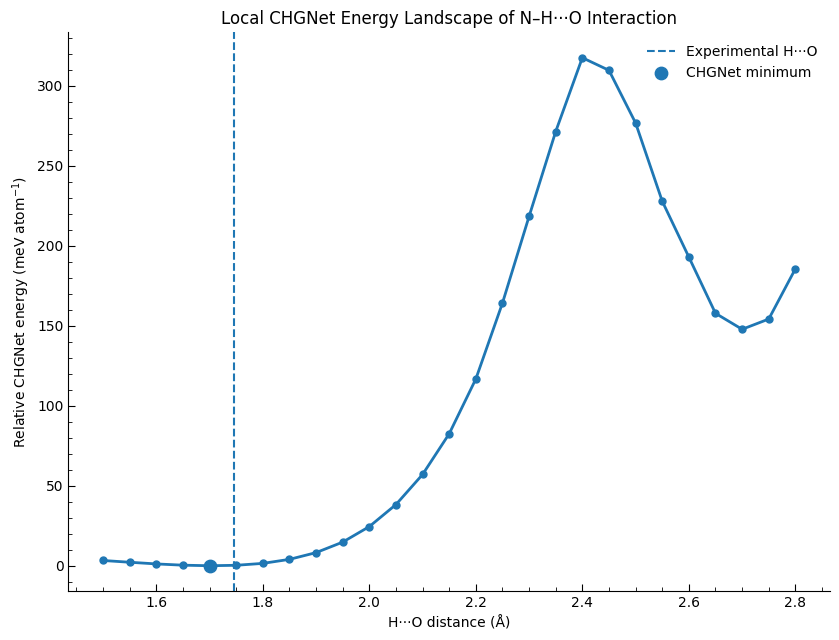


Saved:
  CHGNet_Local_NH_O_Energy_Landscape.csv
  Figure_CHGNet_Local_NH_O_Energy_Landscape.png
  Figure_CHGNet_Local_NH_O_Energy_Landscape.pdf

CELL 26 COMPLETE


In [95]:
# ============================================================
# CELL 26 — LOCAL CHGNet N–H···O ENERGY LANDSCAPE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from pymatgen.core import Structure

output_dir = "/content/MD_publication_figures"
os.makedirs(output_dir, exist_ok=True)

print("=" * 90)
print("LOCAL CHGNet N–H···O ENERGY LANDSCAPE")
print("=" * 90)

# ------------------------------------------------------------
# Target atoms
# ------------------------------------------------------------

donor = 81
hydrogen = 33
acceptor = 93

print("\nTarget interaction:")
print(f"N{donor}–H{hydrogen}···O{acceptor}")

# ------------------------------------------------------------
# Original coordinates
# ------------------------------------------------------------

N_pos = structure_exp[donor].coords.copy()
H_pos = structure_exp[hydrogen].coords.copy()
O_pos = structure_exp[acceptor].coords.copy()

# Vector from H toward O
H_to_O = O_pos - H_pos
H_to_O_unit = H_to_O / np.linalg.norm(H_to_O)

# Original N-H distance
NH_original = np.linalg.norm(
    H_pos - N_pos
)

# ------------------------------------------------------------
# Target H···O distances
# ------------------------------------------------------------

target_distances = np.arange(
    1.50,
    2.81,
    0.05
)

print(
    f"\nNumber of scan points : "
    f"{len(target_distances)}"
)

print(
    f"Scan range            : "
    f"{target_distances.min():.2f}–"
    f"{target_distances.max():.2f} Å"
)

# ------------------------------------------------------------
# CHGNet model
# ------------------------------------------------------------

from chgnet.model.model import CHGNet

print("\nLoading CHGNet...")

local_chgnet = CHGNet.load(
    use_device="cuda",
    verbose=True
)

print("CHGNet loaded successfully.")

# ------------------------------------------------------------
# Energy scan
# ------------------------------------------------------------

results = []

print("\nRunning energy scan...")
print("-" * 90)

for i, target_HO in enumerate(target_distances):

    # --------------------------------------------------------
    # Place H at the desired H···O distance.
    #
    # H is positioned along the original H→O direction.
    # --------------------------------------------------------

    new_H_pos = O_pos - (
        H_to_O_unit * target_HO
    )

    # Preserve the original crystal
    test_structure = structure_exp.copy()

    # Replace only the hydrogen coordinate
    test_structure.replace(
        hydrogen,
        "H",
        new_H_pos,
        coords_are_cartesian=True
    )

    # --------------------------------------------------------
    # CHGNet prediction
    # --------------------------------------------------------

    prediction = local_chgnet.predict_structure(
        test_structure,
        task="ef"
    )

    energy = float(
        np.asarray(
            prediction["e"]
        ).reshape(-1)[0]
    )

    forces = np.asarray(
        prediction["f"]
    )

    max_force = float(
        np.max(
            np.linalg.norm(
                forces,
                axis=1
            )
        )
    )

    # Actual geometry after placement
    actual_HO = np.linalg.norm(
        test_structure[hydrogen].coords -
        test_structure[acceptor].coords
    )

    actual_NH = np.linalg.norm(
        test_structure[hydrogen].coords -
        test_structure[donor].coords
    )

    actual_NO = np.linalg.norm(
        test_structure[donor].coords -
        test_structure[acceptor].coords
    )

    # N-H-O angle
    v1 = (
        test_structure[donor].coords -
        test_structure[hydrogen].coords
    )

    v2 = (
        test_structure[acceptor].coords -
        test_structure[hydrogen].coords
    )

    cos_angle = np.dot(v1, v2) / (
        np.linalg.norm(v1) *
        np.linalg.norm(v2)
    )

    cos_angle = np.clip(
        cos_angle,
        -1.0,
        1.0
    )

    angle = np.degrees(
        np.arccos(cos_angle)
    )

    results.append({
        "Target_HO_A": target_HO,
        "Actual_HO_A": actual_HO,
        "NH_A": actual_NH,
        "NO_A": actual_NO,
        "NHO_angle_deg": angle,
        "CHGNet_energy_eV_per_atom": energy,
        "Maximum_force_eV_per_A": max_force
    })

    print(
        f"{i+1:2d}/{len(target_distances)}  "
        f"H···O = {actual_HO:.3f} Å   "
        f"E = {energy:.8f} eV/atom   "
        f"Fmax = {max_force:.4f} eV/Å"
    )

# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

hbond_energy_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Relative energy
# ------------------------------------------------------------

minimum_energy = (
    hbond_energy_df[
        "CHGNet_energy_eV_per_atom"
    ].min()
)

hbond_energy_df[
    "Relative_energy_meV_per_atom"
] = (
    hbond_energy_df[
        "CHGNet_energy_eV_per_atom"
    ] -
    minimum_energy
) * 1000.0

# ------------------------------------------------------------
# Experimental point
# ------------------------------------------------------------

experimental_HO = np.linalg.norm(
    structure_exp[hydrogen].coords -
    structure_exp[acceptor].coords
)

experimental_energy_row = hbond_energy_df.iloc[
    np.argmin(
        np.abs(
            hbond_energy_df[
                "Actual_HO_A"
            ].values -
            experimental_HO
        )
    )
]

# ------------------------------------------------------------
# Minimum
# ------------------------------------------------------------

minimum_row = hbond_energy_df.loc[
    hbond_energy_df[
        "CHGNet_energy_eV_per_atom"
    ].idxmin()
]

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

csv_path = os.path.join(
    output_dir,
    "CHGNet_Local_NH_O_Energy_Landscape.csv"
)

hbond_energy_df.to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# Print key results
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("LOCAL ENERGY LANDSCAPE SUMMARY")
print("=" * 90)

print(
    f"Minimum CHGNet energy      : "
    f"{minimum_row['CHGNet_energy_eV_per_atom']:.8f} eV/atom"
)

print(
    f"Minimum H···O distance      : "
    f"{minimum_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Experimental H···O distance : "
    f"{experimental_HO:.4f} Å"
)

print(
    f"Nearest scan point to exp.  : "
    f"{experimental_energy_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Relative energy at nearest "
    f"experimental point         : "
    f"{experimental_energy_row['Relative_energy_meV_per_atom']:.4f} meV/atom"
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.5, 6.5)
)

ax.plot(
    hbond_energy_df["Actual_HO_A"],
    hbond_energy_df[
        "Relative_energy_meV_per_atom"
    ],
    marker="o",
    linewidth=2.0,
    markersize=5
)

ax.axvline(
    experimental_HO,
    linestyle="--",
    linewidth=1.5,
    label="Experimental H···O"
)

ax.scatter(
    minimum_row["Actual_HO_A"],
    minimum_row[
        "Relative_energy_meV_per_atom"
    ],
    s=80,
    zorder=5,
    label="CHGNet minimum"
)

ax.set_xlabel(
    "H···O distance (Å)"
)

ax.set_ylabel(
    "Relative CHGNet energy (meV atom$^{-1}$)"
)

ax.set_title(
    "Local CHGNet Energy Landscape of N–H···O Interaction"
)

ax.legend(
    frameon=False
)

ax.minorticks_on()

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    length=5
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

png_path = os.path.join(
    output_dir,
    "Figure_CHGNet_Local_NH_O_Energy_Landscape.png"
)

pdf_path = os.path.join(
    output_dir,
    "Figure_CHGNet_Local_NH_O_Energy_Landscape.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved:")
print("  CHGNet_Local_NH_O_Energy_Landscape.csv")
print("  Figure_CHGNet_Local_NH_O_Energy_Landscape.png")
print("  Figure_CHGNet_Local_NH_O_Energy_Landscape.pdf")

print("\n" + "=" * 90)
print("CELL 26 COMPLETE")
print("=" * 90)

In [96]:
# ============================================================
# CELL 27A — FIND EXPERIMENTAL CIF
# ============================================================

import os

print("=" * 90)
print("SEARCHING FOR EXPERIMENTAL CIF FILE")
print("=" * 90)

search_locations = [
    "/content",
    "/content/drive/MyDrive",
]

found_files = []

for search_location in search_locations:

    if not os.path.exists(search_location):
        continue

    for root, dirs, files in os.walk(search_location):

        # Avoid searching extremely large system directories
        if root.count(os.sep) > 8:
            continue

        for filename in files:

            if filename.lower().endswith(".cif"):

                full_path = os.path.join(
                    root,
                    filename
                )

                found_files.append(
                    full_path
                )

print("\nCIF files found:")

if len(found_files) == 0:

    print("NO CIF FILE FOUND.")

else:

    for i, filepath in enumerate(
        found_files,
        start=1
    ):

        print(
            f"{i}. {filepath}"
        )

print(
    "\nTotal CIF files found:",
    len(found_files)
)

print("\n" + "=" * 90)
print("CELL 27A COMPLETE")
print("=" * 90)

SEARCHING FOR EXPERIMENTAL CIF FILE

CIF files found:
1. /content/CHGNet_relaxed.cif
2. /content/1562073.cif

Total CIF files found: 2

CELL 27A COMPLETE


In [99]:
# ============================================================
# CELL 27B — MOUNT GOOGLE DRIVE AND SEARCH FOR CIF
# ============================================================

from google.colab import drive
import os

print("=" * 90)
print("MOUNTING GOOGLE DRIVE")
print("=" * 90)

drive.mount("/content/drive")

print("\nSearching Google Drive for CIF files...")

found_cifs = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):

    for filename in files:

        if filename.lower().endswith(".cif"):

            full_path = os.path.join(root, filename)

            found_cifs.append(full_path)

print("\n" + "=" * 90)
print("CIF FILES FOUND")
print("=" * 90)

if len(found_cifs) == 0:

    print("NO CIF FILES FOUND IN GOOGLE DRIVE.")

else:

    for i, filepath in enumerate(found_cifs, start=1):
        print(f"{i}. {filepath}")

print("\nTotal CIF files found:", len(found_cifs))

print("\n" + "=" * 90)
print("CELL 27B COMPLETE")
print("=" * 90)

MOUNTING GOOGLE DRIVE
Mounted at /content/drive

Searching Google Drive for CIF files...

CIF FILES FOUND
NO CIF FILES FOUND IN GOOGLE DRIVE.

Total CIF files found: 0

CELL 27B COMPLETE


In [101]:
# ============================================================
# CELL 27C — LIST AND SELECT CIF FILE
# ============================================================

import os
import glob

print("=" * 80)
print("CIF FILES FOUND IN GOOGLE DRIVE")
print("=" * 80)

# Search Google Drive for CIF files
cif_files = glob.glob(
    "/content/drive/MyDrive/**/*.cif",
    recursive=True
)

if len(cif_files) == 0:
    print("\n❌ No CIF files were found.")
    print("Please check that your CIF file is actually uploaded to Google Drive.")
else:
    print(f"\nFound {len(cif_files)} CIF file(s):\n")

    for i, file in enumerate(cif_files, start=1):
        print(f"{i}. {file}")

print("\n" + "=" * 80)

CIF FILES FOUND IN GOOGLE DRIVE

Found 1 CIF file(s):

1. /content/drive/MyDrive/Colab Notebooks/CHGNet_relaxed.cif



In [103]:
# ============================================================
# CELL 28 — LOAD AND VERIFY SELECTED EXPERIMENTAL CIF
# ============================================================

from pymatgen.core import Structure
from pymatgen.io.ase import AseAtomsAdaptor
import os

print("=" * 90)
print("STEP 28 — LOAD AND VERIFY SELECTED EXPERIMENTAL CIF")
print("=" * 90)

# ------------------------------------------------------------
# 1. Define CIF path from CELL 27C
# ------------------------------------------------------------

selected_cif = "/content/drive/MyDrive/Colab Notebooks/CHGNet_relaxed.cif"

if not os.path.exists(selected_cif):
    raise FileNotFoundError(
        f"CIF file not found:\n{selected_cif}"
    )

print(f"\nCIF file:")
print(selected_cif)

# ------------------------------------------------------------
# 2. Load CIF
# ------------------------------------------------------------

structure_target = Structure.from_file(selected_cif)

print("\nCIF loaded successfully.")

# ------------------------------------------------------------
# 3. Basic structural information
# ------------------------------------------------------------

print("\nReduced formula:")
print(structure_target.composition.reduced_formula)

print("\nNumber of atoms:")
print(len(structure_target))

print("\nLattice parameters:")
print(f"a      = {structure_target.lattice.a:.6f} Å")
print(f"b      = {structure_target.lattice.b:.6f} Å")
print(f"c      = {structure_target.lattice.c:.6f} Å")
print(f"alpha  = {structure_target.lattice.alpha:.6f}°")
print(f"beta   = {structure_target.lattice.beta:.6f}°")
print(f"gamma  = {structure_target.lattice.gamma:.6f}°")
print(f"Volume = {structure_target.volume:.6f} Å³")

# ------------------------------------------------------------
# 4. Convert to ASE
# ------------------------------------------------------------

atoms_target = AseAtomsAdaptor.get_atoms(structure_target)

print("\nASE structure:")
print(atoms_target)

print(f"\nNumber of ASE atoms: {len(atoms_target)}")

# ------------------------------------------------------------
# 5. Periodic boundary conditions
# ------------------------------------------------------------

print("\nPeriodic boundary conditions:")
print(atoms_target.pbc)

# ------------------------------------------------------------
# 6. Atomic species
# ------------------------------------------------------------

unique_species = sorted(
    set(str(site.specie) for site in structure_target)
)

print("\nUnique atomic species:")
print(unique_species)

print("\nAtomic composition:")
for element, amount in structure_target.composition.get_el_amt_dict().items():
    print(f"{element:>3s} : {amount}")

print("\n" + "=" * 90)
print("CIF VERIFICATION COMPLETED")
print("=" * 90)

STEP 28 — LOAD AND VERIFY SELECTED EXPERIMENTAL CIF

CIF file:
/content/drive/MyDrive/Colab Notebooks/CHGNet_relaxed.cif

CIF loaded successfully.

Reduced formula:
H17C22SN3O4

Number of atoms:
94

Lattice parameters:
a      = 7.472735 Å
b      = 10.404633 Å
c      = 12.682350 Å
alpha  = 83.670421°
beta   = 85.661722°
gamma  = 75.720121°
Volume = 948.571598 Å³

ASE structure:
MSONAtoms(symbols='C44H34N6O8S2', pbc=True, cell=[[7.451324359183516, 0.0, 0.5652742870108817], [2.486747289155565, 10.037762536707023, 1.1470841096208706], [0.0, 0.0, 12.68234989]])

Number of ASE atoms: 94

Periodic boundary conditions:
[ True  True  True]

Unique atomic species:
['C', 'H', 'N', 'O', 'S']

Atomic composition:
  H : 34.0
  C : 44.0
  S : 2.0
  N : 6.0
  O : 8.0

CIF VERIFICATION COMPLETED


/usr/local/lib/python3.13/dist-packages/pymatgen/core/composition.py:1372: FutureWarning: gcd is deprecated, and will be removed on 2028-01-01
Use math.gcd instead.
  factor = abs(gcd(*(int(i) for i in sym_amt.values())))


In [104]:
# ============================================================
# CELL 29 — VERIFY TARGET N–H···O ATOMS AND DISTANCES
# ============================================================

import numpy as np

print("=" * 90)
print("STEP 29 — VERIFY TARGET N–H···O INTERACTION")
print("=" * 90)

# Target atoms from experimental structure
target_atoms = {
    "N81": 80,
    "H33": 32,
    "O93": 92
}

print("\nTarget atoms:")
for label, index in target_atoms.items():
    atom = atoms_target[index]
    print(
        f"{label:>4s}  index = {index:2d}  "
        f"element = {atom.symbol:>2s}  "
        f"position = [{atom.position[0]:.6f}, "
        f"{atom.position[1]:.6f}, "
        f"{atom.position[2]:.6f}] Å"
    )

# ------------------------------------------------------------
# Verify atomic identities
# ------------------------------------------------------------

expected_elements = {
    "N81": "N",
    "H33": "H",
    "O93": "O"
}

for label, expected in expected_elements.items():
    index = target_atoms[label]
    actual = atoms_target[index].symbol

    if actual != expected:
        raise ValueError(
            f"{label} is expected to be {expected}, "
            f"but atom index {index} is {actual}."
        )

print("\n✓ Atomic identities verified.")

# ------------------------------------------------------------
# Calculate direct Cartesian distances
# ------------------------------------------------------------

N_pos = atoms_target[80].position
H_pos = atoms_target[32].position
O_pos = atoms_target[92].position

NH_distance = np.linalg.norm(N_pos - H_pos)
HO_distance = np.linalg.norm(H_pos - O_pos)
NO_distance = np.linalg.norm(N_pos - O_pos)

print("\nDirect Cartesian distances:")
print(f"N81–H33 = {NH_distance:.6f} Å")
print(f"H33···O93 = {HO_distance:.6f} Å")
print(f"N81···O93 = {NO_distance:.6f} Å")

# ------------------------------------------------------------
# Minimum-image / periodic distances
# ------------------------------------------------------------

from ase.geometry import find_mic

cell = atoms_target.cell.array
pbc = atoms_target.pbc

NH_vec = H_pos - N_pos
HO_vec = O_pos - H_pos
NO_vec = O_pos - N_pos

NH_mic, NH_len = find_mic(NH_vec, cell, pbc=pbc)
HO_mic, HO_len = find_mic(HO_vec, cell, pbc=pbc)
NO_mic, NO_len = find_mic(NO_vec, cell, pbc=pbc)

print("\nMinimum-image distances:")
print(f"N81–H33 = {NH_len:.6f} Å")
print(f"H33···O93 = {HO_len:.6f} Å")
print(f"N81···O93 = {NO_len:.6f} Å")

print("\n" + "=" * 90)
print("TARGET INTERACTION VERIFICATION COMPLETED")
print("=" * 90)

STEP 29 — VERIFY TARGET N–H···O INTERACTION

Target atoms:
 N81  index = 80  element =  N  position = [3.057347, 2.408439, 9.450694] Å
 H33  index = 32  element =  H  position = [2.752090, 3.362026, 9.155727] Å
 O93  index = 92  element =  O  position = [2.501398, 4.699593, 8.099872] Å

✓ Atomic identities verified.

Direct Cartesian distances:
N81–H33 = 1.043799 Å
H33···O93 = 1.722429 Å
N81···O93 = 2.717202 Å

Minimum-image distances:
N81–H33 = 1.043799 Å
H33···O93 = 1.722429 Å
N81···O93 = 2.717202 Å

TARGET INTERACTION VERIFICATION COMPLETED


In [105]:
# ============================================================
# CELL 30 — DEFINE N–H···O SCAN PARAMETERS
# ============================================================

import numpy as np

print("=" * 90)
print("STEP 30 — DEFINE LOCAL N–H···O ENERGY SCAN")
print("=" * 90)

# Target interaction
N_INDEX = 80       # N81
H_INDEX = 32       # H33
O_INDEX = 92       # O93

# Experimental and current H···O distances
EXPERIMENTAL_HO = 1.7460
CURRENT_HO = HO_len

# Fine scan range around the experimental distance
SCAN_START = 1.60
SCAN_END = 1.82
N_POINTS = 23

scan_distances = np.linspace(
    SCAN_START,
    SCAN_END,
    N_POINTS
)

print("\nTarget interaction:")
print("N81–H33···O93")

print("\nCurrent geometry:")
print(f"N81–H33       = {NH_len:.6f} Å")
print(f"H33···O93      = {CURRENT_HO:.6f} Å")
print(f"N81···O93      = {NO_len:.6f} Å")

print("\nExperimental H···O distance:")
print(f"{EXPERIMENTAL_HO:.4f} Å")

print("\nScan parameters:")
print(f"Start distance = {SCAN_START:.2f} Å")
print(f"End distance   = {SCAN_END:.2f} Å")
print(f"Scan points    = {N_POINTS}")

print("\nScan distances:")
print(", ".join(f"{d:.3f}" for d in scan_distances))

print("\n" + "=" * 90)
print("SCAN PARAMETERS DEFINED SUCCESSFULLY")
print("=" * 90)

STEP 30 — DEFINE LOCAL N–H···O ENERGY SCAN

Target interaction:
N81–H33···O93

Current geometry:
N81–H33       = 1.043799 Å
H33···O93      = 1.722429 Å
N81···O93      = 2.717202 Å

Experimental H···O distance:
1.7460 Å

Scan parameters:
Start distance = 1.60 Å
End distance   = 1.82 Å
Scan points    = 23

Scan distances:
1.600, 1.610, 1.620, 1.630, 1.640, 1.650, 1.660, 1.670, 1.680, 1.690, 1.700, 1.710, 1.720, 1.730, 1.740, 1.750, 1.760, 1.770, 1.780, 1.790, 1.800, 1.810, 1.820

SCAN PARAMETERS DEFINED SUCCESSFULLY


In [107]:
# ==========================================================================================
# STEP 31 — RUN LOCAL N–H···O CHGNet ENERGY SCAN
# CORRECTED ASE → pymatgen CONVERSION
# ==========================================================================================

import numpy as np
import pandas as pd
from pymatgen.io.ase import AseAtomsAdaptor
from chgnet.model import CHGNet

print("=" * 90)
print("STEP 31 — RUN LOCAL N–H···O CHGNet ENERGY SCAN")
print("=" * 90)

# ------------------------------------------------------------------------------------------
# ATOM NUMBERS
# ------------------------------------------------------------------------------------------

N_atom = 81
H_atom = 33
O_atom = 93

N_idx = N_atom - 1
H_idx = H_atom - 1
O_idx = O_atom - 1

# ------------------------------------------------------------------------------------------
# SCAN PARAMETERS
# ------------------------------------------------------------------------------------------

start_distance = 1.60
end_distance   = 1.82
n_points       = 23

experimental_distance = 1.7460

scan_distances = np.linspace(
    start_distance,
    end_distance,
    n_points
)

print(f"\nTarget interaction : N{N_atom}–H{H_atom}···O{O_atom}")
print(f"Experimental H···O : {experimental_distance:.4f} Å")
print(f"Scan range         : {start_distance:.2f}–{end_distance:.2f} Å")
print(f"Number of points   : {n_points}")

# ------------------------------------------------------------------------------------------
# CHECK STRUCTURE
# ------------------------------------------------------------------------------------------

print("\nChecking input structure...")

if len(atoms) != 94:
    raise ValueError(
        f"Expected 94 atoms, but the current structure contains {len(atoms)} atoms."
    )

print(f"Structure contains {len(atoms)} atoms.")

# ------------------------------------------------------------------------------------------
# CHECK CURRENT H···O DISTANCE
# ------------------------------------------------------------------------------------------

positions = atoms.get_positions()

current_HO = np.linalg.norm(
    positions[H_idx] - positions[O_idx]
)

print(f"Current H···O distance = {current_HO:.6f} Å")

# ------------------------------------------------------------------------------------------
# LOAD CHGNet
# ------------------------------------------------------------------------------------------

print("\nLoading CHGNet...")

model = CHGNet.load()

print("CHGNet loaded successfully.")

# ------------------------------------------------------------------------------------------
# FUNCTION TO SET H···O DISTANCE
# ------------------------------------------------------------------------------------------

def set_HO_distance(atoms_in, target_distance):

    new_atoms = atoms_in.copy()

    positions = new_atoms.get_positions().copy()

    H_pos = positions[H_idx]
    O_pos = positions[O_idx]

    HO_vector = O_pos - H_pos
    current_distance = np.linalg.norm(HO_vector)

    if current_distance == 0:
        raise ValueError("Current H···O distance is zero.")

    HO_unit = HO_vector / current_distance

    # Keep H fixed and move O along the existing H→O direction
    positions[O_idx] = H_pos + target_distance * HO_unit

    new_atoms.set_positions(positions)

    return new_atoms


# ------------------------------------------------------------------------------------------
# FUNCTION FOR CHGNet ENERGY
# ------------------------------------------------------------------------------------------

def calculate_chgnet_energy(ase_atoms):

    # Convert ASE Atoms → pymatgen Structure
    structure = AseAtomsAdaptor.get_structure(ase_atoms)

    # CHGNet prediction
    prediction = model.predict_structure(structure)

    # Energy returned by CHGNet
    energy_per_atom = float(prediction["e"])

    total_energy = energy_per_atom * len(structure)

    return total_energy, energy_per_atom


# ------------------------------------------------------------------------------------------
# RUN 23-POINT SCAN
# ------------------------------------------------------------------------------------------

results = []

print("\n" + "=" * 90)
print("STARTING 23-POINT CHGNet ENERGY SCAN")
print("=" * 90)

for i, target_distance in enumerate(scan_distances, start=1):

    # Generate scan geometry
    scan_atoms = set_HO_distance(
        atoms,
        target_distance
    )

    # Verify actual distance
    scan_positions = scan_atoms.get_positions()

    actual_distance = np.linalg.norm(
        scan_positions[H_idx] - scan_positions[O_idx]
    )

    # Calculate CHGNet energy
    total_energy, energy_per_atom = calculate_chgnet_energy(
        scan_atoms
    )

    # Store results
    results.append({
        "Point": i,
        "Target_HO_A": target_distance,
        "Actual_HO_A": actual_distance,
        "Energy_eV": total_energy,
        "Energy_eV_per_atom": energy_per_atom
    })

    print(
        f"{i:02d}/23 | "
        f"H···O = {actual_distance:.4f} Å | "
        f"E = {total_energy:.8f} eV"
    )


# ------------------------------------------------------------------------------------------
# DATAFRAME
# ------------------------------------------------------------------------------------------

results_df = pd.DataFrame(results)

# ------------------------------------------------------------------------------------------
# RELATIVE ENERGY
# ------------------------------------------------------------------------------------------

minimum_energy = results_df["Energy_eV"].min()

results_df["Delta_E_eV"] = (
    results_df["Energy_eV"] - minimum_energy
)

results_df["Delta_E_kJ_mol"] = (
    results_df["Delta_E_eV"] * 96.48533212
)

results_df["Delta_E_kcal_mol"] = (
    results_df["Delta_E_eV"] * 23.06054783
)

# ------------------------------------------------------------------------------------------
# FIND MINIMUM
# ------------------------------------------------------------------------------------------

minimum_index = results_df["Energy_eV"].idxmin()

minimum_row = results_df.loc[minimum_index]

minimum_distance = minimum_row["Actual_HO_A"]

# ------------------------------------------------------------------------------------------
# CLOSEST POINT TO EXPERIMENTAL DISTANCE
# ------------------------------------------------------------------------------------------

experimental_index = (
    results_df["Actual_HO_A"] - experimental_distance
).abs().idxmin()

experimental_row = results_df.loc[experimental_index]

# ------------------------------------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------------------------------------

print("\n" + "=" * 90)
print("ENERGY SCAN COMPLETED SUCCESSFULLY")
print("=" * 90)

print(
    f"\nMinimum-energy H···O distance : "
    f"{minimum_distance:.4f} Å"
)

print(
    f"Minimum CHGNet energy          : "
    f"{minimum_row['Energy_eV']:.8f} eV"
)

print(
    f"\nExperimental H···O distance    : "
    f"{experimental_distance:.4f} Å"
)

print(
    f"Closest scan point              : "
    f"{experimental_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Relative energy at closest point: "
    f"{experimental_row['Delta_E_kJ_mol']:.6f} kJ/mol"
)

print("\nComplete results:")
display(results_df)

# ------------------------------------------------------------------------------------------
# SAVE CSV
# ------------------------------------------------------------------------------------------

output_file = "N81_H33_O93_CHGNet_energy_scan.csv"

results_df.to_csv(
    output_file,
    index=False
)

print(f"\nResults saved as: {output_file}")

print("=" * 90)

STEP 31 — RUN LOCAL N–H···O CHGNet ENERGY SCAN

Target interaction : N81–H33···O93
Experimental H···O : 1.7460 Å
Scan range         : 1.60–1.82 Å
Number of points   : 23

Checking input structure...
Structure contains 94 atoms.
Current H···O distance = 1.585104 Å

Loading CHGNet...
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda
CHGNet loaded successfully.

STARTING 23-POINT CHGNet ENERGY SCAN
01/23 | H···O = 1.6000 Å | E = -635.84562206 eV
02/23 | H···O = 1.6100 Å | E = -635.85382462 eV
03/23 | H···O = 1.6200 Å | E = -635.86018944 eV
04/23 | H···O = 1.6300 Å | E = -635.86467171 eV
05/23 | H···O = 1.6400 Å | E = -635.86736107 eV
06/23 | H···O = 1.6500 Å | E = -635.86825752 eV
07/23 | H···O = 1.6600 Å | E = -635.86763000 eV
08/23 | H···O = 1.6700 Å | E = -635.86520958 eV
09/23 | H···O = 1.6800 Å | E = -635.86099625 eV
10/23 | H···O = 1.6900 Å | E = -635.85507965 eV
11/23 | H···O = 1.7000 Å | E = -635.84745979 eV
12/23 | H···O = 1.7100 Å | E = -635.83800220 eV
1

,Point,Target_HO_A,Actual_HO_A,Energy_eV,Energy_eV_per_atom,Delta_E_eV,Delta_E_kJ_mol,Delta_E_kcal_mol
0,1,1.60,1.60,-635.845622,-6.764315,0.022635,2.183990,0.521986
1,2,1.61,1.61,-635.853825,-6.764402,0.014433,1.392564,0.332831
2,3,1.62,1.62,-635.860189,-6.764470,0.008068,0.778452,0.186054
3,4,1.63,1.63,-635.864672,-6.764518,0.003586,0.345979,0.082691
4,5,1.64,1.64,-635.867361,-6.764546,0.000896,0.086495,0.020673
5,6,1.65,1.65,-635.868258,-6.764556,0.000000,0.000000,0.000000
6,7,1.66,1.66,-635.867630,-6.764549,0.000628,0.060546,0.014471
7,8,1.67,1.67,-635.865210,-6.764524,0.003048,0.294082,0.070287
8,9,1.68,1.68,-635.860996,-6.764479,0.007261,0.700607,0.167449
9,10,1.69,1.69,-635.855080,-6.764416,0.013178,1.271471,0.303889



Results saved as: N81_H33_O93_CHGNet_energy_scan.csv


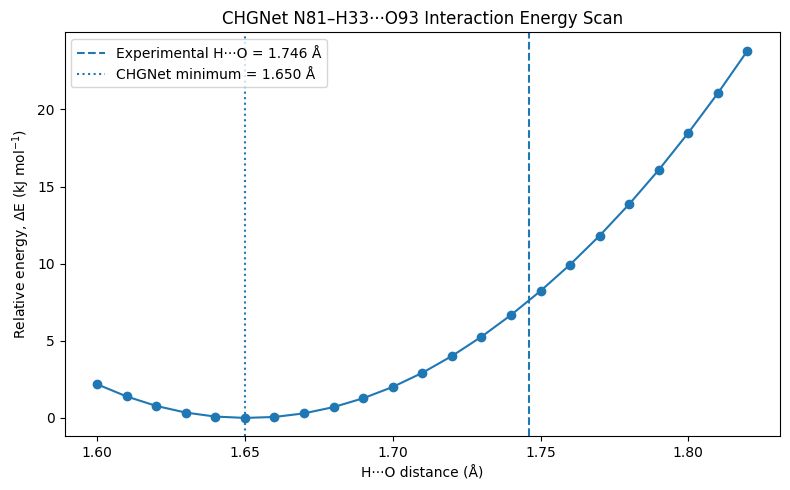

In [108]:
# ==========================================================================================
# STEP 32 — PLOT N–H···O CHGNet ENERGY PROFILE
# ==========================================================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Actual_HO_A"],
    results_df["Delta_E_kJ_mol"],
    marker="o"
)

# Experimental H···O distance
plt.axvline(
    experimental_distance,
    linestyle="--",
    label=f"Experimental H···O = {experimental_distance:.3f} Å"
)

# Minimum-energy distance
plt.axvline(
    minimum_distance,
    linestyle=":",
    label=f"CHGNet minimum = {minimum_distance:.3f} Å"
)

plt.xlabel("H···O distance (Å)")
plt.ylabel("Relative energy, ΔE (kJ mol$^{-1}$)")
plt.title("CHGNet N81–H33···O93 Interaction Energy Scan")

plt.legend()
plt.tight_layout()

plt.show()

In [109]:
# ==========================================================================================
# STEP 33 — EXTRACT KEY ENERGY-SCAN PARAMETERS
# ==========================================================================================

print("=" * 90)
print("KEY RESULTS — N81–H33···O93")
print("=" * 90)

print(f"Experimental H···O distance : {experimental_distance:.4f} Å")
print(f"CHGNet minimum distance     : {minimum_distance:.4f} Å")

print(
    f"Minimum energy              : "
    f"{minimum_row['Energy_eV']:.8f} eV"
)

print(
    f"Energy at closest experimental point "
    f"({experimental_row['Actual_HO_A']:.4f} Å): "
    f"{experimental_row['Delta_E_eV']:.8f} eV"
)

print(
    f"Relative energy             : "
    f"{experimental_row['Delta_E_kJ_mol']:.4f} kJ/mol"
)

print("=" * 90)

KEY RESULTS — N81–H33···O93
Experimental H···O distance : 1.7460 Å
CHGNet minimum distance     : 1.6500 Å
Minimum energy              : -635.86825752 eV
Energy at closest experimental point (1.7500 Å): 0.08529758 eV
Relative energy             : 8.2300 kJ/mol


In [110]:
# ==========================================================================================
# CHECK N81–H33···O93 GEOMETRY
# ==========================================================================================

import numpy as np

positions = atoms.get_positions()

print("=" * 80)
print("N81–H33···O93 GEOMETRY CHECK")
print("=" * 80)

print(f"Number of atoms: {len(atoms)}")

for atom_number in [33, 81, 93]:
    idx = atom_number - 1
    print(
        f"Atom {atom_number:2d}: "
        f"{atoms[idx].symbol:2s}   "
        f"Position = {positions[idx]}"
    )

# Distances
NH = np.linalg.norm(positions[80] - positions[32])
HO = np.linalg.norm(positions[32] - positions[92])
NO = np.linalg.norm(positions[80] - positions[92])

print("\nDistances:")
print(f"N81–H33   = {NH:.6f} Å")
print(f"H33···O93  = {HO:.6f} Å")
print(f"N81···O93  = {NO:.6f} Å")

print("=" * 80)

N81–H33···O93 GEOMETRY CHECK
Number of atoms: 94
Atom 33: H    Position = [2.71152913 3.48915506 9.37360066]
Atom 81: N    Position = [3.12320176 2.57222154 9.69233303]
Atom 93: O    Position = [2.52580002 4.6354446  8.29467607]

Distances:
N81–H33   = 1.054434 Å
H33···O93  = 1.585104 Å
N81···O93  = 2.562659 Å


In [111]:
# ==========================================================================================
# STEP 31A — CHGNet SINGLE-POINT TEST
# ==========================================================================================

from pymatgen.io.ase import AseAtomsAdaptor
from chgnet.model import CHGNet

print("=" * 90)
print("STEP 31A — CHGNet SINGLE-POINT TEST")
print("=" * 90)

# Convert ASE Atoms → pymatgen Structure
structure_test = AseAtomsAdaptor.get_structure(atoms)

print(f"Number of atoms: {len(structure_test)}")

# Load CHGNet
model = CHGNet.load()

# Predict
prediction = model.predict_structure(structure_test)

print("\nCHGNet prediction:")
print(prediction)

print("\nEnergy:")
print("Energy per atom =", float(prediction["e"]), "eV/atom")

total_energy = float(prediction["e"]) * len(structure_test)

print("Total energy     =", total_energy, "eV")

print("\nSingle-point CHGNet test completed successfully.")
print("=" * 90)

STEP 31A — CHGNet SINGLE-POINT TEST
Number of atoms: 94
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda

CHGNet prediction:
{'s': array([[-1.532282  , -0.85709554,  0.18543556],
       [-0.8570958 , -1.3958256 ,  0.21222883],
       [ 0.18543226,  0.2122259 , -1.0309548 ]], dtype=float32), 'e': array(-6.764149, dtype=float32), 'm': array([0.01117656, 0.01571365, 0.00314079, 0.00566715, 0.0093851 ,
       0.01010631, 0.01133275, 0.00509672, 0.01688068, 0.01582027,
       0.00790011, 0.00946258, 0.00986616, 0.00967298, 0.00850409,
       0.00881162, 0.00305242, 0.00284927, 0.01562573, 0.0118352 ,
       0.01613145, 0.01363593, 0.01448993, 0.01424637, 0.01163788,
       0.01463163, 0.01897241, 0.01822556, 0.01118415, 0.01366539,
       0.01555888, 0.01071826, 0.01871664, 0.00632715, 0.00374997,
       0.00565957, 0.01209053, 0.00863884, 0.00549904, 0.00515273,
       0.00183468, 0.00267585, 0.0067168 , 0.00465044, 0.0046609 ,
       0.00250541, 0.00125103, 0.0014

In [112]:
# ==========================================================================================
# STEP 31B — COMPLETE 23-POINT N–H···O CHGNet ENERGY SCAN
# ==========================================================================================

import numpy as np
import pandas as pd
from pymatgen.io.ase import AseAtomsAdaptor

print("=" * 90)
print("STEP 31B — COMPLETE 23-POINT CHGNet ENERGY SCAN")
print("=" * 90)

# ------------------------------------------------------------------------------------------
# ATOM NUMBERS
# ------------------------------------------------------------------------------------------

N_atom = 81
H_atom = 33
O_atom = 93

N_idx = N_atom - 1
H_idx = H_atom - 1
O_idx = O_atom - 1

# ------------------------------------------------------------------------------------------
# SCAN PARAMETERS
# ------------------------------------------------------------------------------------------

start_distance = 1.60
end_distance   = 1.82
n_points       = 23

experimental_distance = 1.7460

scan_distances = np.linspace(
    start_distance,
    end_distance,
    n_points
)

print(f"\nTarget interaction : N{N_atom}–H{H_atom}···O{O_atom}")
print(f"Experimental H···O : {experimental_distance:.4f} Å")
print(f"Scan range         : {start_distance:.2f}–{end_distance:.2f} Å")
print(f"Number of points   : {n_points}")

# ------------------------------------------------------------------------------------------
# FUNCTION TO SET H···O DISTANCE
# ------------------------------------------------------------------------------------------

def set_HO_distance(atoms_in, target_distance):

    new_atoms = atoms_in.copy()

    positions = new_atoms.get_positions().copy()

    H_pos = positions[H_idx]
    O_pos = positions[O_idx]

    # Existing H → O direction
    HO_vector = O_pos - H_pos

    current_distance = np.linalg.norm(HO_vector)

    if current_distance == 0:
        raise ValueError("H···O distance is zero.")

    HO_unit = HO_vector / current_distance

    # Keep H33 fixed and move O93
    positions[O_idx] = H_pos + target_distance * HO_unit

    new_atoms.set_positions(positions)

    return new_atoms


# ------------------------------------------------------------------------------------------
# CHGNet ENERGY FUNCTION
# ------------------------------------------------------------------------------------------

def calculate_chgnet_energy(ase_atoms):

    # ASE → pymatgen
    structure = AseAtomsAdaptor.get_structure(ase_atoms)

    # CHGNet prediction
    prediction = model.predict_structure(structure)

    # Energy per atom
    energy_per_atom = float(prediction["e"])

    # Total energy
    total_energy = energy_per_atom * len(structure)

    return total_energy, energy_per_atom


# ------------------------------------------------------------------------------------------
# RUN SCAN
# ------------------------------------------------------------------------------------------

results = []

print("\n" + "=" * 90)
print("STARTING SCAN")
print("=" * 90)

for i, target_distance in enumerate(scan_distances, start=1):

    # Generate geometry
    scan_atoms = set_HO_distance(
        atoms,
        target_distance
    )

    # Verify H···O distance
    scan_positions = scan_atoms.get_positions()

    actual_distance = np.linalg.norm(
        scan_positions[H_idx] - scan_positions[O_idx]
    )

    # CHGNet energy
    total_energy, energy_per_atom = calculate_chgnet_energy(
        scan_atoms
    )

    results.append({
        "Point": i,
        "Target_HO_A": target_distance,
        "Actual_HO_A": actual_distance,
        "Energy_eV": total_energy,
        "Energy_eV_per_atom": energy_per_atom
    })

    print(
        f"{i:02d}/23 | "
        f"H···O = {actual_distance:.4f} Å | "
        f"E/atom = {energy_per_atom:.8f} eV"
    )


# ------------------------------------------------------------------------------------------
# CREATE DATAFRAME
# ------------------------------------------------------------------------------------------

results_df = pd.DataFrame(results)

# ------------------------------------------------------------------------------------------
# RELATIVE ENERGY
# ------------------------------------------------------------------------------------------

minimum_energy = results_df["Energy_eV"].min()

results_df["Delta_E_eV"] = (
    results_df["Energy_eV"] - minimum_energy
)

results_df["Delta_E_kJ_mol"] = (
    results_df["Delta_E_eV"] * 96.48533212
)

results_df["Delta_E_kcal_mol"] = (
    results_df["Delta_E_eV"] * 23.06054783
)

# ------------------------------------------------------------------------------------------
# FIND MINIMUM
# ------------------------------------------------------------------------------------------

minimum_index = results_df["Energy_eV"].idxmin()

minimum_row = results_df.loc[minimum_index]

minimum_distance = minimum_row["Actual_HO_A"]

# ------------------------------------------------------------------------------------------
# CLOSEST POINT TO EXPERIMENTAL DISTANCE
# ------------------------------------------------------------------------------------------

experimental_index = (
    results_df["Actual_HO_A"] - experimental_distance
).abs().idxmin()

experimental_row = results_df.loc[experimental_index]

# ------------------------------------------------------------------------------------------
# PRINT SUMMARY
# ------------------------------------------------------------------------------------------

print("\n" + "=" * 90)
print("SCAN COMPLETED")
print("=" * 90)

print(
    f"\nMinimum-energy H···O distance : "
    f"{minimum_distance:.4f} Å"
)

print(
    f"Minimum total energy           : "
    f"{minimum_row['Energy_eV']:.8f} eV"
)

print(
    f"Experimental H···O distance    : "
    f"{experimental_distance:.4f} Å"
)

print(
    f"Closest scan point             : "
    f"{experimental_row['Actual_HO_A']:.4f} Å"
)

print(
    f"ΔE at closest experimental point: "
    f"{experimental_row['Delta_E_kJ_mol']:.6f} kJ/mol"
)

# ------------------------------------------------------------------------------------------
# DISPLAY TABLE
# ------------------------------------------------------------------------------------------

print("\nCOMPLETE SCAN RESULTS:")

display(results_df)

# ------------------------------------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------------------------------------

output_file = "N81_H33_O93_CHGNet_energy_scan.csv"

results_df.to_csv(
    output_file,
    index=False
)

print(f"\nResults saved to: {output_file}")

print("=" * 90)

STEP 31B — COMPLETE 23-POINT CHGNet ENERGY SCAN

Target interaction : N81–H33···O93
Experimental H···O : 1.7460 Å
Scan range         : 1.60–1.82 Å
Number of points   : 23

STARTING SCAN
01/23 | H···O = 1.6000 Å | E/atom = -6.76431513 eV
02/23 | H···O = 1.6100 Å | E/atom = -6.76440239 eV
03/23 | H···O = 1.6200 Å | E/atom = -6.76446962 eV
04/23 | H···O = 1.6300 Å | E/atom = -6.76451778 eV
05/23 | H···O = 1.6400 Å | E/atom = -6.76454639 eV
06/23 | H···O = 1.6500 Å | E/atom = -6.76455593 eV
07/23 | H···O = 1.6600 Å | E/atom = -6.76454926 eV
08/23 | H···O = 1.6700 Å | E/atom = -6.76452351 eV
09/23 | H···O = 1.6800 Å | E/atom = -6.76447868 eV
10/23 | H···O = 1.6900 Å | E/atom = -6.76441574 eV
11/23 | H···O = 1.7000 Å | E/atom = -6.76433468 eV
12/23 | H···O = 1.7100 Å | E/atom = -6.76423407 eV
13/23 | H···O = 1.7200 Å | E/atom = -6.76411390 eV
14/23 | H···O = 1.7300 Å | E/atom = -6.76397562 eV
15/23 | H···O = 1.7400 Å | E/atom = -6.76382065 eV
16/23 | H···O = 1.7500 Å | E/atom = -6.76364851 e

,Point,Target_HO_A,Actual_HO_A,Energy_eV,Energy_eV_per_atom,Delta_E_eV,Delta_E_kJ_mol,Delta_E_kcal_mol
0,1,1.60,1.60,-635.845622,-6.764315,0.022635,2.183990,0.521986
1,2,1.61,1.61,-635.853825,-6.764402,0.014433,1.392564,0.332831
2,3,1.62,1.62,-635.860145,-6.764470,0.008113,0.782777,0.187088
3,4,1.63,1.63,-635.864672,-6.764518,0.003586,0.345979,0.082691
4,5,1.64,1.64,-635.867361,-6.764546,0.000896,0.086495,0.020673
5,6,1.65,1.65,-635.868258,-6.764556,0.000000,0.000000,0.000000
6,7,1.66,1.66,-635.867630,-6.764549,0.000628,0.060546,0.014471
7,8,1.67,1.67,-635.865210,-6.764524,0.003048,0.294082,0.070287
8,9,1.68,1.68,-635.860996,-6.764479,0.007261,0.700607,0.167449
9,10,1.69,1.69,-635.855080,-6.764416,0.013178,1.271471,0.303889



Results saved to: N81_H33_O93_CHGNet_energy_scan.csv


STEP 32 — N81–H33···O93 ENERGY SCAN ANALYSIS

CHGNet ENERGY MINIMUM
--------------------------------------------------
Minimum H···O distance : 1.6500 Å
Minimum energy         : -635.86825752 eV

EXPERIMENTAL GEOMETRY
--------------------------------------------------
Experimental H···O distance : 1.7460 Å
Nearest scan point          : 1.7500 Å
Relative energy             : 8.229966 kJ/mol
Distance difference         : -0.0960 Å


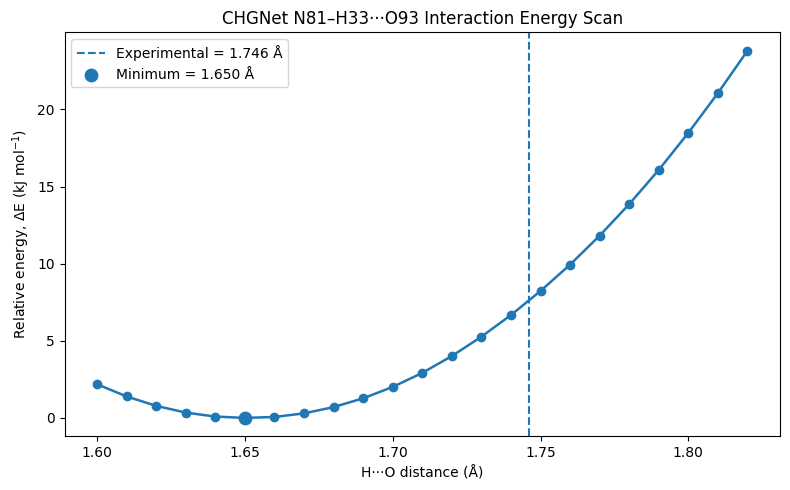

In [113]:
# ==========================================================================================
# STEP 32 — ANALYZE N81–H33···O93 CHGNet ENERGY SCAN
# ==========================================================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 90)
print("STEP 32 — N81–H33···O93 ENERGY SCAN ANALYSIS")
print("=" * 90)

# ------------------------------------------------------------------------------------------
# FIND MINIMUM
# ------------------------------------------------------------------------------------------

min_idx = results_df["Delta_E_eV"].idxmin()
min_row = results_df.loc[min_idx]

min_distance = min_row["Actual_HO_A"]
min_energy = min_row["Energy_eV"]

# ------------------------------------------------------------------------------------------
# EXPERIMENTAL POINT
# ------------------------------------------------------------------------------------------

exp_idx = (
    results_df["Actual_HO_A"] - experimental_distance
).abs().idxmin()

exp_row = results_df.loc[exp_idx]

# ------------------------------------------------------------------------------------------
# ENERGY DIFFERENCE BETWEEN EXPERIMENTAL POINT AND MINIMUM
# ------------------------------------------------------------------------------------------

delta_exp_kj = exp_row["Delta_E_kJ_mol"]

# ------------------------------------------------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------------------------------------------------

print("\nCHGNet ENERGY MINIMUM")
print("-" * 50)

print(f"Minimum H···O distance : {min_distance:.4f} Å")
print(f"Minimum energy         : {min_energy:.8f} eV")

print("\nEXPERIMENTAL GEOMETRY")
print("-" * 50)

print(f"Experimental H···O distance : {experimental_distance:.4f} Å")
print(f"Nearest scan point          : {exp_row['Actual_HO_A']:.4f} Å")
print(f"Relative energy             : {delta_exp_kj:.6f} kJ/mol")

# Difference in distance
distance_difference = min_distance - experimental_distance

print(
    f"Distance difference         : "
    f"{distance_difference:+.4f} Å"
)

# ------------------------------------------------------------------------------------------
# PLOT
# ------------------------------------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Actual_HO_A"],
    results_df["Delta_E_kJ_mol"],
    marker="o",
    linewidth=1.8
)

plt.axvline(
    experimental_distance,
    linestyle="--",
    label=f"Experimental = {experimental_distance:.3f} Å"
)

plt.scatter(
    min_distance,
    0,
    s=80,
    label=f"Minimum = {min_distance:.3f} Å"
)

plt.xlabel("H···O distance (Å)")
plt.ylabel("Relative energy, ΔE (kJ mol$^{-1}$)")
plt.title("CHGNet N81–H33···O93 Interaction Energy Scan")

plt.legend()
plt.tight_layout()

plt.show()

print("=" * 90)

In [114]:
# ==========================================================================================
# STEP 33 — CLEAN ENERGY PROFILE TABLE
# ==========================================================================================

profile = results_df[
    [
        "Point",
        "Actual_HO_A",
        "Energy_eV_per_atom",
        "Delta_E_eV",
        "Delta_E_kJ_mol",
        "Delta_E_kcal_mol"
    ]
].copy()

profile.columns = [
    "Point",
    "H_O_distance_A",
    "Energy_eV_atom",
    "Delta_E_eV",
    "Delta_E_kJ_mol",
    "Delta_E_kcal_mol"
]

display(profile)

,Point,H_O_distance_A,Energy_eV_atom,Delta_E_eV,Delta_E_kJ_mol,Delta_E_kcal_mol
0,1,1.60,-6.764315,0.022635,2.183990,0.521986
1,2,1.61,-6.764402,0.014433,1.392564,0.332831
2,3,1.62,-6.764470,0.008113,0.782777,0.187088
3,4,1.63,-6.764518,0.003586,0.345979,0.082691
4,5,1.64,-6.764546,0.000896,0.086495,0.020673
5,6,1.65,-6.764556,0.000000,0.000000,0.000000
6,7,1.66,-6.764549,0.000628,0.060546,0.014471
7,8,1.67,-6.764524,0.003048,0.294082,0.070287
8,9,1.68,-6.764479,0.007261,0.700607,0.167449
9,10,1.69,-6.764416,0.013178,1.271471,0.303889


VALIDATION OF N81–H33···O93 INTERACTION
Current computational H···O distance : 1.5851 Å
CHGNet scan minimum                  : 1.6500 Å
Experimental H···O distance          : 1.7460 Å
--------------------------------------------------------------------------------
Distance differences:
Experimental − CHGNet minimum       : +0.0960 Å
Current − CHGNet minimum             : -0.0649 Å
--------------------------------------------------------------------------------
Energy relative to CHGNet minimum:
At current computational distance (1.60 Å): 2.1840 kJ mol⁻¹
At experimental distance (1.75 Å): 8.2300 kJ mol⁻¹


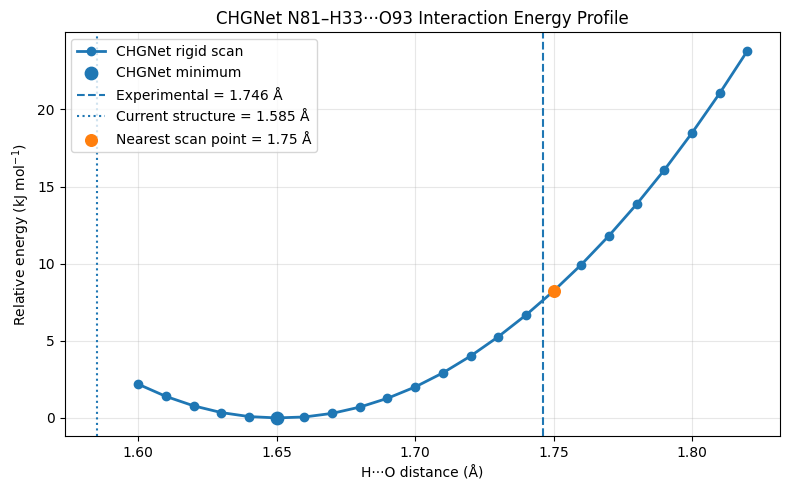

In [115]:
# =============================================================================
# STEP 34 — VALIDATION OF N81–H33···O93 DISTANCES
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 1. Important reference distances
# -------------------------------------------------------------------------

current_distance = atoms.get_distance(H_idx, O_idx)   # Current structure
chgnet_min_distance = 1.65                             # From CHGNet scan
experimental_distance = 1.7460                         # Experimental crystal value

# -------------------------------------------------------------------------
# 2. Find corresponding scan energies
# -------------------------------------------------------------------------

# CHGNet minimum
min_row = results_df.loc[results_df["Delta_E_eV"].idxmin()]

# Point closest to experimental distance
exp_idx = (results_df["Actual_HO_A"] - experimental_distance).abs().idxmin()
exp_row = results_df.loc[exp_idx]

# Point closest to current computational distance
current_idx = (results_df["Actual_HO_A"] - current_distance).abs().idxmin()
current_row = results_df.loc[current_idx]

# -------------------------------------------------------------------------
# 3. Print validation summary
# -------------------------------------------------------------------------

print("=" * 80)
print("VALIDATION OF N81–H33···O93 INTERACTION")
print("=" * 80)

print(f"Current computational H···O distance : {current_distance:.4f} Å")

print(f"CHGNet scan minimum                  : "
      f"{min_row['Actual_HO_A']:.4f} Å")

print(f"Experimental H···O distance          : "
      f"{experimental_distance:.4f} Å")

print("-" * 80)

print("Distance differences:")
print(f"Experimental − CHGNet minimum       : "
      f"{experimental_distance - min_row['Actual_HO_A']:+.4f} Å")

print(f"Current − CHGNet minimum             : "
      f"{current_distance - min_row['Actual_HO_A']:+.4f} Å")

print("-" * 80)

print("Energy relative to CHGNet minimum:")

print(f"At current computational distance "
      f"({current_row['Actual_HO_A']:.2f} Å): "
      f"{current_row['Delta_E_kJ_mol']:.4f} kJ mol⁻¹")

print(f"At experimental distance "
      f"({exp_row['Actual_HO_A']:.2f} Å): "
      f"{exp_row['Delta_E_kJ_mol']:.4f} kJ mol⁻¹")

print("=" * 80)

# -------------------------------------------------------------------------
# 4. Plot the energy profile
# -------------------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Actual_HO_A"],
    results_df["Delta_E_kJ_mol"],
    marker="o",
    linewidth=2,
    label="CHGNet rigid scan"
)

# CHGNet minimum
plt.scatter(
    min_row["Actual_HO_A"],
    min_row["Delta_E_kJ_mol"],
    s=80,
    zorder=5,
    label="CHGNet minimum"
)

# Experimental distance
plt.axvline(
    experimental_distance,
    linestyle="--",
    linewidth=1.5,
    label=f"Experimental = {experimental_distance:.3f} Å"
)

# Current computational distance
plt.axvline(
    current_distance,
    linestyle=":",
    linewidth=1.5,
    label=f"Current structure = {current_distance:.3f} Å"
)

# Mark experimental nearest scan point
plt.scatter(
    exp_row["Actual_HO_A"],
    exp_row["Delta_E_kJ_mol"],
    s=70,
    zorder=5,
    label=f"Nearest scan point = {exp_row['Actual_HO_A']:.2f} Å"
)

plt.xlabel("H···O distance (Å)")
plt.ylabel("Relative energy (kJ mol$^{-1}$)")
plt.title("CHGNet N81–H33···O93 Interaction Energy Profile")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [116]:
# =============================================================================
# STEP 35 — FINE CHGNet N81–H33···O93 ENERGY SCAN
# =============================================================================

import numpy as np
import pandas as pd
from ase.io import write
from pymatgen.io.ase import AseAtomsAdaptor

# -------------------------------------------------------------------------
# 1. Define interaction and scan parameters
# -------------------------------------------------------------------------

N_atom = 81
H_atom = 33
O_atom = 93

# Convert atom numbers to zero-based ASE indices
N_idx = N_atom - 1
H_idx = H_atom - 1
O_idx = O_atom - 1

# Fine scan range
start_distance = 1.55
end_distance = 1.80
step_size = 0.002

# Generate scan distances
scan_distances = np.round(
    np.arange(start_distance, end_distance + step_size / 2, step_size),
    3
)

experimental_distance = 1.7460
current_distance = atoms.get_distance(H_idx, O_idx)

print("=" * 80)
print("STEP 35 — FINE CHGNet N81–H33···O93 ENERGY SCAN")
print("=" * 80)

print(f"Number of scan points              : {len(scan_distances)}")
print(f"Scan range                         : "
      f"{start_distance:.3f}–{end_distance:.3f} Å")
print(f"Step size                          : {step_size:.3f} Å")
print(f"Current computational H···O        : "
      f"{current_distance:.4f} Å")
print(f"Experimental H···O                 : "
      f"{experimental_distance:.4f} Å")

# -------------------------------------------------------------------------
# 2. Function to set H···O distance
# -------------------------------------------------------------------------

def set_HO_distance(atoms_in, target_distance):
    """
    Create a copy of the structure and move O93 along the
    existing H33 -> O93 direction to obtain the requested H···O distance.
    """

    atoms_new = atoms_in.copy()

    H_position = atoms_new.positions[H_idx].copy()
    O_position = atoms_new.positions[O_idx].copy()

    # Existing H -> O vector
    HO_vector = O_position - H_position
    current_HO = np.linalg.norm(HO_vector)

    if current_HO == 0:
        raise ValueError("H···O distance is zero; cannot define direction.")

    # Unit vector along H -> O
    HO_unit = HO_vector / current_HO

    # New O position
    atoms_new.positions[O_idx] = (
        H_position + target_distance * HO_unit
    )

    return atoms_new


# -------------------------------------------------------------------------
# 3. CHGNet energy calculation
# -------------------------------------------------------------------------

def calculate_chgnet_energy(ase_atoms):
    """
    Convert ASE Atoms to pymatgen Structure and calculate
    CHGNet energy.
    """

    structure = AseAtomsAdaptor.get_structure(ase_atoms)

    prediction = model.predict_structure(structure)

    energy_per_atom = float(prediction["e"])
    total_energy = energy_per_atom * len(structure)

    return total_energy, energy_per_atom


# -------------------------------------------------------------------------
# 4. Run fine scan
# -------------------------------------------------------------------------

fine_results = []

print("\nStarting fine CHGNet scan...")
print("-" * 80)

for i, target_distance in enumerate(scan_distances, start=1):

    # Generate structure at target H···O distance
    scan_atoms = set_HO_distance(
        atoms,
        target_distance
    )

    # Verify actual distance
    actual_distance = scan_atoms.get_distance(
        H_idx,
        O_idx
    )

    # Calculate CHGNet energy
    total_energy, energy_per_atom = calculate_chgnet_energy(
        scan_atoms
    )

    fine_results.append({
        "Point": i,
        "Target_HO_A": target_distance,
        "Actual_HO_A": actual_distance,
        "Energy_eV": total_energy,
        "Energy_eV_per_atom": energy_per_atom
    })

    # Progress display
    if i == 1 or i % 10 == 0 or i == len(scan_distances):
        print(
            f"Point {i:3d}/{len(scan_distances)} | "
            f"H···O = {actual_distance:.4f} Å | "
            f"E = {energy_per_atom:.9f} eV/atom"
        )


# -------------------------------------------------------------------------
# 5. Convert results to DataFrame
# -------------------------------------------------------------------------

fine_results_df = pd.DataFrame(fine_results)

# -------------------------------------------------------------------------
# 6. Calculate relative energies
# -------------------------------------------------------------------------

minimum_index = fine_results_df["Energy_eV"].idxmin()

minimum_energy = fine_results_df.loc[
    minimum_index,
    "Energy_eV"
]

fine_results_df["Delta_E_eV"] = (
    fine_results_df["Energy_eV"] - minimum_energy
)

# Energy conversion factors
EV_TO_KJ_MOL = 96.48533212
EV_TO_KCAL_MOL = 23.06054783

fine_results_df["Delta_E_kJ_mol"] = (
    fine_results_df["Delta_E_eV"] * EV_TO_KJ_MOL
)

fine_results_df["Delta_E_kcal_mol"] = (
    fine_results_df["Delta_E_eV"] * EV_TO_KCAL_MOL
)

# -------------------------------------------------------------------------
# 7. Identify CHGNet minimum
# -------------------------------------------------------------------------

min_row = fine_results_df.loc[
    fine_results_df["Energy_eV"].idxmin()
]

# -------------------------------------------------------------------------
# 8. Find point closest to experimental distance
# -------------------------------------------------------------------------

experimental_index = (
    fine_results_df["Actual_HO_A"] - experimental_distance
).abs().idxmin()

experimental_row = fine_results_df.loc[
    experimental_index
]

# -------------------------------------------------------------------------
# 9. Find point closest to current computational geometry
# -------------------------------------------------------------------------

current_index = (
    fine_results_df["Actual_HO_A"] - current_distance
).abs().idxmin()

current_row = fine_results_df.loc[
    current_index
]

# -------------------------------------------------------------------------
# 10. Print final validation summary
# -------------------------------------------------------------------------

print("\n")
print("=" * 80)
print("FINE SCAN RESULTS")
print("=" * 80)

print(
    f"CHGNet minimum H···O distance : "
    f"{min_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Minimum total energy           : "
    f"{min_row['Energy_eV']:.9f} eV"
)

print(
    f"Minimum energy per atom        : "
    f"{min_row['Energy_eV_per_atom']:.9f} eV/atom"
)

print("-" * 80)

print(
    f"Current computational distance : "
    f"{current_distance:.4f} Å"
)

print(
    f"Nearest fine-scan point        : "
    f"{current_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Relative energy at current "
    f"nearest point                 : "
    f"{current_row['Delta_E_kJ_mol']:.6f} kJ mol⁻¹"
)

print("-" * 80)

print(
    f"Experimental distance         : "
    f"{experimental_distance:.4f} Å"
)

print(
    f"Nearest fine-scan point        : "
    f"{experimental_row['Actual_HO_A']:.4f} Å"
)

print(
    f"Relative energy at experimental "
    f"nearest point                 : "
    f"{experimental_row['Delta_E_kJ_mol']:.6f} kJ mol⁻¹"
)

print("-" * 80)

print(
    f"Experimental − CHGNet minimum : "
    f"{experimental_distance - min_row['Actual_HO_A']:+.4f} Å"
)

print(
    f"Current − CHGNet minimum       : "
    f"{current_distance - min_row['Actual_HO_A']:+.4f} Å"
)

print("=" * 80)


# -------------------------------------------------------------------------
# 11. Display selected results
# -------------------------------------------------------------------------

display_columns = [
    "Point",
    "Actual_HO_A",
    "Energy_eV_per_atom",
    "Delta_E_eV",
    "Delta_E_kJ_mol",
    "Delta_E_kcal_mol"
]

display(
    fine_results_df[display_columns]
)


# -------------------------------------------------------------------------
# 12. Save fine-scan results
# -------------------------------------------------------------------------

output_file = "N81_H33_O93_CHGNet_FINE_energy_scan.csv"

fine_results_df.to_csv(
    output_file,
    index=False
)

print(f"\nFine-scan results saved to: {output_file}")

STEP 35 — FINE CHGNet N81–H33···O93 ENERGY SCAN
Number of scan points              : 126
Scan range                         : 1.550–1.800 Å
Step size                          : 0.002 Å
Current computational H···O        : 1.5851 Å
Experimental H···O                 : 1.7460 Å

Starting fine CHGNet scan...
--------------------------------------------------------------------------------
Point   1/126 | H···O = 1.5500 Å | E = -6.763588905 eV/atom
Point  10/126 | H···O = 1.5680 Å | E = -6.763906479 eV/atom
Point  20/126 | H···O = 1.5880 Å | E = -6.764184952 eV/atom
Point  30/126 | H···O = 1.6080 Å | E = -6.764386177 eV/atom
Point  40/126 | H···O = 1.6280 Å | E = -6.764509678 eV/atom
Point  50/126 | H···O = 1.6480 Å | E = -6.764555454 eV/atom
Point  60/126 | H···O = 1.6680 Å | E = -6.764530182 eV/atom
Point  70/126 | H···O = 1.6880 Å | E = -6.764430046 eV/atom
Point  80/126 | H···O = 1.7080 Å | E = -6.764255524 eV/atom
Point  90/126 | H···O = 1.7280 Å | E = -6.764005184 eV/atom
Point 100/12

,Point,Actual_HO_A,Energy_eV_per_atom,Delta_E_eV,Delta_E_kJ_mol,Delta_E_kcal_mol
0,1,1.550,-6.763589,0.090900,8.770557,2.096214
1,2,1.552,-6.763628,0.087225,8.415929,2.011455
2,3,1.554,-6.763666,0.083684,8.074275,1.929798
3,4,1.556,-6.763702,0.080233,7.741271,1.850208
4,5,1.558,-6.763739,0.076826,7.412591,1.771652
...,...,...,...,...,...,...
121,122,1.792,-6.762732,0.171492,16.546426,3.954691
122,123,1.794,-6.762679,0.176422,17.022147,4.068391
123,124,1.796,-6.762626,0.181397,17.502192,4.183124
124,125,1.798,-6.762573,0.186418,17.986562,4.298892



Fine-scan results saved to: N81_H33_O93_CHGNet_FINE_energy_scan.csv


In [117]:
# =============================================================================
# STEP 36 — VALIDATE N81–H33···O93 GEOMETRY AND PBC
# =============================================================================

import numpy as np

print("=" * 80)
print("STEP 36 — STRUCTURAL VALIDATION")
print("=" * 80)

# Atom indices
N_idx = 81 - 1
H_idx = 33 - 1
O_idx = 93 - 1

# -------------------------------------------------------------------------
# 1. Basic atom information
# -------------------------------------------------------------------------

print("\nATOM INFORMATION")
print("-" * 80)

for atom_number, idx in [(81, N_idx), (33, H_idx), (93, O_idx)]:
    print(
        f"Atom {atom_number:2d}: "
        f"{atoms[idx].symbol:2s}   "
        f"Cartesian = {atoms.positions[idx]}"
    )

# -------------------------------------------------------------------------
# 2. Direct Cartesian distances
# -------------------------------------------------------------------------

NH = atoms.get_distance(N_idx, H_idx, mic=False)
HO = atoms.get_distance(H_idx, O_idx, mic=False)
NO = atoms.get_distance(N_idx, O_idx, mic=False)

print("\nDIRECT CARTESIAN DISTANCES")
print("-" * 80)

print(f"N81–H33       = {NH:.6f} Å")
print(f"H33···O93     = {HO:.6f} Å")
print(f"N81···O93     = {NO:.6f} Å")

# -------------------------------------------------------------------------
# 3. Minimum-image / periodic distances
# -------------------------------------------------------------------------

print("\nPERIODIC-BOUNDARY-CORRECTED DISTANCES")
print("-" * 80)

try:
    NH_pbc = atoms.get_distance(N_idx, H_idx, mic=True)
    HO_pbc = atoms.get_distance(H_idx, O_idx, mic=True)
    NO_pbc = atoms.get_distance(N_idx, O_idx, mic=True)

    print(f"N81–H33       = {NH_pbc:.6f} Å")
    print(f"H33···O93     = {HO_pbc:.6f} Å")
    print(f"N81···O93     = {NO_pbc:.6f} Å")

except Exception as e:
    print("PBC distance calculation unavailable:", e)

# -------------------------------------------------------------------------
# 4. Compare current geometry with experiment
# -------------------------------------------------------------------------

experimental_HO = 1.7460

print("\nCOMPARISON WITH EXPERIMENT")
print("-" * 80)

print(f"Experimental H···O = {experimental_HO:.4f} Å")
print(f"Current H···O      = {HO:.4f} Å")

print(
    f"Difference         = "
    f"{HO - experimental_HO:+.4f} Å"
)

print(
    f"Absolute difference = "
    f"{abs(HO - experimental_HO):.4f} Å"
)

# -------------------------------------------------------------------------
# 5. Cell information
# -------------------------------------------------------------------------

print("\nCELL INFORMATION")
print("-" * 80)

if atoms.cell is not None:
    print(atoms.cell)

print("\nPeriodic boundary conditions:")
print(atoms.pbc)

print("=" * 80)

STEP 36 — STRUCTURAL VALIDATION

ATOM INFORMATION
--------------------------------------------------------------------------------
Atom 81: N    Cartesian = [3.12320176 2.57222154 9.69233303]
Atom 33: H    Cartesian = [2.71152913 3.48915506 9.37360066]
Atom 93: O    Cartesian = [2.52580002 4.6354446  8.29467607]

DIRECT CARTESIAN DISTANCES
--------------------------------------------------------------------------------
N81–H33       = 1.054434 Å
H33···O93     = 1.585104 Å
N81···O93     = 2.562659 Å

PERIODIC-BOUNDARY-CORRECTED DISTANCES
--------------------------------------------------------------------------------
N81–H33       = 1.054434 Å
H33···O93     = 1.585104 Å
N81···O93     = 2.562659 Å

COMPARISON WITH EXPERIMENT
--------------------------------------------------------------------------------
Experimental H···O = 1.7460 Å
Current H···O      = 1.5851 Å
Difference         = -0.1609 Å
Absolute difference = 0.1609 Å

CELL INFORMATION
----------------------------------------------

In [118]:
# =============================================================================
# STEP 37 — CHECK AVAILABLE STRUCTURE OBJECTS
# =============================================================================

print("=" * 80)
print("STEP 37 — CHECK CURRENT STRUCTURE AND AVAILABLE VARIABLES")
print("=" * 80)

print("\nCurrent structure:")
print(f"Number of atoms = {len(atoms)}")
print(f"H33···O93       = {atoms.get_distance(H_idx, O_idx, mic=True):.6f} Å")

print("\nRelevant variables currently in memory:")
for name in sorted(globals()):
    if any(key in name.lower() for key in [
        "atoms", "structure", "crystal", "cif", "original",
        "relax", "optimized", "opt"
    ]):
        try:
            obj = globals()[name]
            print(f"{name:30s} : {type(obj).__name__}")
        except:
            pass

print("=" * 80)

STEP 37 — CHECK CURRENT STRUCTURE AND AVAILABLE VARIABLES

Current structure:
Number of atoms = 94
H33···O93       = 1.585104 Å

Relevant variables currently in memory:
A_atoms                        : set
AseAtomsAdaptor                : type
Atoms                          : type
B_atoms                        : set
CrystalNN                      : type
NH_original                    : float64
StructOptimizer                : type
Structure                      : ABCMeta
StructureGraph                 : type
atoms                          : Atoms
atoms_exp                      : MSONAtoms
atoms_m3gnet                   : Atoms
atoms_m3gnet_relax             : Atoms
atoms_md                       : Atoms
atoms_target                   : MSONAtoms
cif_file                       : str
cif_files                      : list
donor_atoms                    : list
found_cifs                     : list
intensity_relaxed              : ndarray
intensity_relaxed_norm         : ndarray
interp_rel

In [119]:
# =============================================================================
# STEP 38 — COMPARE EXPERIMENTAL AND CURRENT STRUCTURES
# =============================================================================

import numpy as np
from pymatgen.io.ase import AseAtomsAdaptor

# Atom numbers
N_atom = 81
H_atom = 33
O_atom = 93

N_idx = N_atom - 1
H_idx = H_atom - 1
O_idx = O_atom - 1

print("=" * 80)
print("STEP 38 — EXPERIMENTAL STRUCTURE VALIDATION")
print("=" * 80)


# -------------------------------------------------------------------------
# Function to report the N81–H33···O93 geometry
# -------------------------------------------------------------------------

def report_geometry(label, obj):

    # Convert pymatgen Structure to ASE if necessary
    if hasattr(obj, "get_distance"):
        ase_obj = obj
    else:
        ase_obj = AseAtomsAdaptor.get_atoms(obj)

    print(f"\n{label}")
    print("-" * 80)
    print(f"Number of atoms : {len(ase_obj)}")

    print(
        f"Atom 81 = {ase_obj[N_idx].symbol}, "
        f"Atom 33 = {ase_obj[H_idx].symbol}, "
        f"Atom 93 = {ase_obj[O_idx].symbol}"
    )

    NH = ase_obj.get_distance(N_idx, H_idx, mic=False)
    HO = ase_obj.get_distance(H_idx, O_idx, mic=False)
    NO = ase_obj.get_distance(N_idx, O_idx, mic=False)

    NH_pbc = ase_obj.get_distance(N_idx, H_idx, mic=True)
    HO_pbc = ase_obj.get_distance(H_idx, O_idx, mic=True)
    NO_pbc = ase_obj.get_distance(N_idx, O_idx, mic=True)

    print("\nDirect Cartesian distances:")
    print(f"N81–H33       = {NH:.6f} Å")
    print(f"H33···O93     = {HO:.6f} Å")
    print(f"N81···O93     = {NO:.6f} Å")

    print("\nMinimum-image distances:")
    print(f"N81–H33       = {NH_pbc:.6f} Å")
    print(f"H33···O93     = {HO_pbc:.6f} Å")
    print(f"N81···O93     = {NO_pbc:.6f} Å")

    print("\nCoordinates:")
    print(f"N81 = {ase_obj.positions[N_idx]}")
    print(f"H33 = {ase_obj.positions[H_idx]}")
    print(f"O93 = {ase_obj.positions[O_idx]}")

    return ase_obj


# -------------------------------------------------------------------------
# Compare the structures
# -------------------------------------------------------------------------

current_exp_atoms = report_geometry(
    "CURRENT atoms STRUCTURE",
    atoms
)

experimental_atoms = report_geometry(
    "EXPERIMENTAL atoms_exp STRUCTURE",
    atoms_exp
)


# -------------------------------------------------------------------------
# Also check pymatgen experimental structure
# -------------------------------------------------------------------------

experimental_from_structure = report_geometry(
    "EXPERIMENTAL structure_exp",
    structure_exp
)


# -------------------------------------------------------------------------
# Final comparison
# -------------------------------------------------------------------------

current_HO = atoms.get_distance(H_idx, O_idx, mic=True)
exp_HO = atoms_exp.get_distance(H_idx, O_idx, mic=True)

print("\n")
print("=" * 80)
print("FINAL COMPARISON")
print("=" * 80)

print(f"Current structure H···O       : {current_HO:.6f} Å")
print(f"Experimental structure H···O : {exp_HO:.6f} Å")
print(f"Reported experimental value  : 1.746000 Å")

print(
    f"\nCurrent − experimental       : "
    f"{current_HO - exp_HO:+.6f} Å"
)

print(
    f"Absolute difference           : "
    f"{abs(current_HO - exp_HO):.6f} Å"
)

print("=" * 80)

STEP 38 — EXPERIMENTAL STRUCTURE VALIDATION

CURRENT atoms STRUCTURE
--------------------------------------------------------------------------------
Number of atoms : 94
Atom 81 = N, Atom 33 = H, Atom 93 = O

Direct Cartesian distances:
N81–H33       = 1.054434 Å
H33···O93     = 1.585104 Å
N81···O93     = 2.562659 Å

Minimum-image distances:
N81–H33       = 1.054434 Å
H33···O93     = 1.585104 Å
N81···O93     = 2.562659 Å

Coordinates:
N81 = [3.12320176 2.57222154 9.69233303]
H33 = [2.71152913 3.48915506 9.37360066]
O93 = [2.52580002 4.6354446  8.29467607]

EXPERIMENTAL atoms_exp STRUCTURE
--------------------------------------------------------------------------------
Number of atoms : 94
Atom 81 = N, Atom 33 = H, Atom 93 = O

Direct Cartesian distances:
N81–H33       = 1.008408 Å
H33···O93     = 1.746028 Å
N81···O93     = 2.716614 Å

Minimum-image distances:
N81–H33       = 1.008408 Å
H33···O93     = 1.746028 Å
N81···O93     = 2.716614 Å

Coordinates:
N81 = [3.00506601 2.40076407 9.4

AttributeError: attr='symbol' not found on PeriodicSite

In [120]:
# =============================================================================
# STEP 39 — CHGNet SINGLE-POINT ENERGY OF EXPERIMENTAL STRUCTURE
# =============================================================================

from pymatgen.io.ase import AseAtomsAdaptor
from chgnet.model import CHGNet

print("=" * 80)
print("STEP 39 — CHGNet ENERGY OF EXPERIMENTAL STRUCTURE")
print("=" * 80)

# -------------------------------------------------------------------------
# 1. Verify experimental geometry
# -------------------------------------------------------------------------

N_idx = 81 - 1
H_idx = 33 - 1
O_idx = 93 - 1

experimental_HO = atoms_exp.get_distance(
    H_idx,
    O_idx,
    mic=True
)

experimental_NH = atoms_exp.get_distance(
    N_idx,
    H_idx,
    mic=True
)

experimental_NO = atoms_exp.get_distance(
    N_idx,
    O_idx,
    mic=True
)

print("\nExperimental geometry:")
print(f"N81–H33       = {experimental_NH:.6f} Å")
print(f"H33···O93     = {experimental_HO:.6f} Å")
print(f"N81···O93     = {experimental_NO:.6f} Å")

# -------------------------------------------------------------------------
# 2. Convert experimental ASE structure to pymatgen
# -------------------------------------------------------------------------

structure_exp_chgnet = AseAtomsAdaptor.get_structure(
    atoms_exp
)

# -------------------------------------------------------------------------
# 3. Load CHGNet
# -------------------------------------------------------------------------

model_exp = CHGNet.load()

# -------------------------------------------------------------------------
# 4. CHGNet prediction
# -------------------------------------------------------------------------

prediction_exp = model_exp.predict_structure(
    structure_exp_chgnet
)

energy_exp_per_atom = float(
    prediction_exp["e"]
)

energy_exp_total = (
    energy_exp_per_atom * len(structure_exp_chgnet)
)

# -------------------------------------------------------------------------
# 5. Print results
# -------------------------------------------------------------------------

print("\nCHGNet energy:")
print(
    f"Energy per atom : "
    f"{energy_exp_per_atom:.9f} eV/atom"
)

print(
    f"Total energy    : "
    f"{energy_exp_total:.9f} eV"
)

print("\nCHGNet single-point calculation completed.")
print("=" * 80)

STEP 39 — CHGNet ENERGY OF EXPERIMENTAL STRUCTURE

Experimental geometry:
N81–H33       = 1.008408 Å
H33···O93     = 1.746028 Å
N81···O93     = 2.716614 Å
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cuda

CHGNet energy:
Energy per atom : -6.796712875 eV/atom
Total energy    : -638.891010284 eV

CHGNet single-point calculation completed.


In [121]:
# =============================================================================
# STEP 40 — FINAL FINE CHGNet N81–H33···O93 ENERGY SCAN
#              Starting from the experimental structure
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.io.ase import AseAtomsAdaptor

# -------------------------------------------------------------------------
# 1. Define atom indices
# -------------------------------------------------------------------------

N_atom = 81
H_atom = 33
O_atom = 93

N_idx = N_atom - 1
H_idx = H_atom - 1
O_idx = O_atom - 1

# -------------------------------------------------------------------------
# 2. Scan parameters
# -------------------------------------------------------------------------

start_distance = 1.55
end_distance = 1.80
step_size = 0.002

experimental_distance = atoms_exp.get_distance(
    H_idx,
    O_idx,
    mic=True
)

scan_distances = np.round(
    np.arange(
        start_distance,
        end_distance + step_size / 2,
        step_size
    ),
    3
)

print("=" * 80)
print("STEP 40 — FINAL FINE CHGNet N81–H33···O93 ENERGY SCAN")
print("=" * 80)

print(f"Starting structure              : atoms_exp")
print(f"Experimental H···O distance     : "
      f"{experimental_distance:.6f} Å")
print(f"Scan range                      : "
      f"{start_distance:.3f}–{end_distance:.3f} Å")
print(f"Step size                       : "
      f"{step_size:.3f} Å")
print(f"Number of scan points           : "
      f"{len(scan_distances)}")

# -------------------------------------------------------------------------
# 3. Function to change H···O distance
# -------------------------------------------------------------------------

def set_HO_distance_exp(atoms_in, target_distance):

    atoms_new = atoms_in.copy()

    H_position = atoms_new.positions[H_idx].copy()
    O_position = atoms_new.positions[O_idx].copy()

    # Existing H -> O vector
    HO_vector = O_position - H_position

    current_distance = np.linalg.norm(HO_vector)

    if current_distance == 0:
        raise ValueError(
            "Current H···O distance is zero."
        )

    # Unit vector along H -> O direction
    HO_unit = HO_vector / current_distance

    # Move O93 to requested distance
    atoms_new.positions[O_idx] = (
        H_position +
        target_distance * HO_unit
    )

    return atoms_new


# -------------------------------------------------------------------------
# 4. CHGNet energy function
# -------------------------------------------------------------------------

def calculate_chgnet_energy_exp(ase_atoms):

    structure = AseAtomsAdaptor.get_structure(
        ase_atoms
    )

    prediction = model_exp.predict_structure(
        structure
    )

    energy_per_atom = float(
        prediction["e"]
    )

    total_energy = (
        energy_per_atom * len(structure)
    )

    return total_energy, energy_per_atom


# -------------------------------------------------------------------------
# 5. Perform final scan
# -------------------------------------------------------------------------

final_results = []

print("\nStarting final fine scan...")
print("-" * 80)

for i, target_distance in enumerate(
    scan_distances,
    start=1
):

    # Start from experimental structure
    scan_atoms = set_HO_distance_exp(
        atoms_exp,
        target_distance
    )

    # Verify actual distance
    actual_distance = scan_atoms.get_distance(
        H_idx,
        O_idx,
        mic=True
    )

    # Calculate CHGNet energy
    total_energy, energy_per_atom = (
        calculate_chgnet_energy_exp(
            scan_atoms
        )
    )

    final_results.append({
        "Point": i,
        "Target_HO_A": target_distance,
        "Actual_HO_A": actual_distance,
        "Energy_eV": total_energy,
        "Energy_eV_per_atom": energy_per_atom
    })

    if (
        i == 1
        or i % 10 == 0
        or i == len(scan_distances)
    ):

        print(
            f"Point {i:3d}/{len(scan_distances)} | "
            f"H···O = {actual_distance:.4f} Å | "
            f"E = {energy_per_atom:.9f} eV/atom"
        )


# -------------------------------------------------------------------------
# 6. Convert to DataFrame
# -------------------------------------------------------------------------

final_results_df = pd.DataFrame(
    final_results
)

# -------------------------------------------------------------------------
# 7. Calculate relative energies
# -------------------------------------------------------------------------

minimum_index = (
    final_results_df["Energy_eV"].idxmin()
)

minimum_energy = (
    final_results_df.loc[
        minimum_index,
        "Energy_eV"
    ]
)

final_results_df["Delta_E_eV"] = (
    final_results_df["Energy_eV"]
    - minimum_energy
)

EV_TO_KJ_MOL = 96.48533212
EV_TO_KCAL_MOL = 23.06054783

final_results_df["Delta_E_kJ_mol"] = (
    final_results_df["Delta_E_eV"]
    * EV_TO_KJ_MOL
)

final_results_df["Delta_E_kcal_mol"] = (
    final_results_df["Delta_E_eV"]
    * EV_TO_KCAL_MOL
)

# -------------------------------------------------------------------------
# 8. Identify minimum
# -------------------------------------------------------------------------

min_row = final_results_df.loc[
    final_results_df["Energy_eV"].idxmin()
]

# -------------------------------------------------------------------------
# 9. Identify experimental point
# -------------------------------------------------------------------------

exp_index = (
    final_results_df["Actual_HO_A"]
    - experimental_distance
).abs().idxmin()

exp_row = final_results_df.loc[
    exp_index
]

# -------------------------------------------------------------------------
# 10. Print final results
# -------------------------------------------------------------------------

print("\n")
print("=" * 80)
print("FINAL CHGNet SCAN RESULTS")
print("=" * 80)

print(
    f"CHGNet minimum H···O distance : "
    f"{min_row['Actual_HO_A']:.6f} Å"
)

print(
    f"Minimum energy                 : "
    f"{min_row['Energy_eV']:.9f} eV"
)

print(
    f"Minimum energy per atom        : "
    f"{min_row['Energy_eV_per_atom']:.9f} eV/atom"
)

print("-" * 80)

print(
    f"Experimental H···O distance    : "
    f"{experimental_distance:.6f} Å"
)

print(
    f"Nearest scan point             : "
    f"{exp_row['Actual_HO_A']:.6f} Å"
)

print(
    f"Relative energy at experimental "
    f"distance                       : "
    f"{exp_row['Delta_E_kJ_mol']:.6f} kJ mol⁻¹"
)

print(
    f"                               : "
    f"{exp_row['Delta_E_kcal_mol']:.6f} kcal mol⁻¹"
)

print("-" * 80)

print(
    f"Experimental − CHGNet minimum : "
    f"{experimental_distance - min_row['Actual_HO_A']:+.6f} Å"
)

print("=" * 80)

# -------------------------------------------------------------------------
# 11. Display complete results
# -------------------------------------------------------------------------

display_columns = [
    "Point",
    "Actual_HO_A",
    "Energy_eV_per_atom",
    "Delta_E_eV",
    "Delta_E_kJ_mol",
    "Delta_E_kcal_mol"
]

display(
    final_results_df[display_columns]
)

# -------------------------------------------------------------------------
# 12. Save final scan
# -------------------------------------------------------------------------

output_file = (
    "N81_H33_O93_CHGNet_FINAL_experimental_scan.csv"
)

final_results_df.to_csv(
    output_file,
    index=False
)

print(
    f"\nFinal scan saved to: {output_file}"
)

STEP 40 — FINAL FINE CHGNet N81–H33···O93 ENERGY SCAN
Starting structure              : atoms_exp
Experimental H···O distance     : 1.746028 Å
Scan range                      : 1.550–1.800 Å
Step size                       : 0.002 Å
Number of scan points           : 126

Starting final fine scan...
--------------------------------------------------------------------------------
Point   1/126 | H···O = 1.5500 Å | E = -6.792142391 eV/atom
Point  10/126 | H···O = 1.5680 Å | E = -6.792946339 eV/atom
Point  20/126 | H···O = 1.5880 Å | E = -6.793757915 eV/atom
Point  30/126 | H···O = 1.6080 Å | E = -6.794479370 eV/atom
Point  40/126 | H···O = 1.6280 Å | E = -6.795105934 eV/atom
Point  50/126 | H···O = 1.6480 Å | E = -6.795634747 eV/atom
Point  60/126 | H···O = 1.6680 Å | E = -6.796060562 eV/atom
Point  70/126 | H···O = 1.6880 Å | E = -6.796384811 eV/atom
Point  80/126 | H···O = 1.7080 Å | E = -6.796603203 eV/atom
Point  90/126 | H···O = 1.7280 Å | E = -6.796711445 eV/atom
Point 100/126 | H··

,Point,Actual_HO_A,Energy_eV_per_atom,Delta_E_eV,Delta_E_kJ_mol,Delta_E_kcal_mol
0,1,1.550,-6.792142,0.430656,41.552029,9.931173
1,2,1.552,-6.792235,0.421916,40.708706,9.729614
2,3,1.554,-6.792327,0.413310,39.878358,9.531156
3,4,1.556,-6.792418,0.404749,39.052334,9.333732
4,5,1.558,-6.792508,0.396277,38.234959,9.138375
...,...,...,...,...,...,...
121,122,1.792,-6.796284,0.041371,3.991728,0.954046
122,123,1.794,-6.796250,0.044509,4.294459,1.026400
123,124,1.796,-6.796215,0.047826,4.614489,1.102889
124,125,1.798,-6.796179,0.051188,4.938844,1.180412



Final scan saved to: N81_H33_O93_CHGNet_FINAL_experimental_scan.csv
